Hexagon FBQC fusion network: geometry, checks, logicals, and thresholds

A three-colour hexagonal fusion network on a triangular lattice: red, green and
blue hexagons, one of each per unit tile, periodically tiled. Companion to
`sixring_fbqc_walkthrough.ipynb` -- same approach, geometry first, qubits and
circuits layered on afterward.

| § | what happens |
|---|---|
| 1 | Geometry: points, hexagons, tiles, edge colouring, periodic boundary conditions |
| 2 | The circuit: qubits in space and time, cluster-state CZs, the 6-step fusion schedule |
| 3 | Detectors: the hexagon check operators, derived and verified against Stim |
| 4 | Logicals: the 6 logical operators, found by brute-force nullspace search |
| 5 | Closed-form logicals: the same 6 logicals, hand-derived and verified (`has_flow`) |
| 6 | Measurement-error threshold: `p_meas` sweep decoded with `pymatching`, threshold ≈ 1.0% |
| 7 | Heralded erasure: pure `p_erase` sweep with per-shot reweighted MWPM, threshold ≈ 12-14% |
| 8 | Modified code: H-fusion on the rXX/bXX/gXX layers; checks and logicals re-derived and verified |
| 9 | Thresholds of the modified code (`p_meas`, `p_erase`), compared against §6 and §7 |
| 10 | Noisy resource states: depolarising and pure dephasing prep-noise thresholds |
| 11 | Biased measurement error: logical error rate vs the slot bias `δ` at fixed `p_meas`, both codes |
| 12 | Biased erasure: logical error rate vs `δ` at fixed `p_erase`, both codes |
| 13 | Measurement threshold vs `δ`, regular fusion |
| 14 | Erasure threshold vs `δ`, regular fusion |
| 15 | (archived) How the §6 measurement threshold degrades with prep noise |

In [1]:
import numpy as np
import stim
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from collections import Counter, defaultdict

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Points live on a triangular lattice indexed by integer axial coordinates
`(i, j)`. Every point has 6 nearest neighbours, offset by the six axial
directions `HEX_DIRS`. A **hexagon** centred at point `c` is the 6 points
`c + dir` for each of those directions, listed in a fixed cyclic order so that
consecutive entries are the hexagon's edges.

One **tile** groups three hexagons — red, green, blue — by centre offset from
a tile origin `(0, 0)`:

| colour | centre offset |
|---|---|
| red   | (0, -1) |
| green | (1, 0)  |
| blue  | (-1, 1) |

Tiles repeat on a square grid with translation vectors `(3, 0)` and `(0, 3)`.
Given `x_max, y_max` tiles, the lattice is periodic with period
`(3*x_max, 3*y_max)`.

Every edge of the tiling borders exactly two hexagons of two different
colours; the edge's own colour is the **third**, missing colour — a red edge
is bordered by blue and green, a blue edge by green and red, a green edge by
red and blue. Not every lattice site is used: one third of the sites (those
with `(i - j) % 3 == 1`, given this offset choice) are neither a hexagon
centre nor a vertex.

In [2]:
# The six axial nearest-neighbour directions, in cyclic (hexagon-boundary) order.
HEX_DIRS = [(1, -1), (1, 0), (0, 1), (-1, 1), (-1, 0), (0, -1)]

# Hexagon centres within one tile, relative to the tile origin (0, 0).
TILE_OFFSETS = {"red": (0, -1), "green": (1, 0), "blue": (-1, 1)}

TILE_VECS = [(3, 0), (0, 3)]  # tile-to-tile translation


class HexLattice:
    """Periodic tiling of the triangular lattice by red/green/blue hexagons.

    `x_max`, `y_max` tiles in each direction, wrapping periodically with
    period (3*x_max, 3*y_max).
    """

    def __init__(self, x_max, y_max):
        self.x_max, self.y_max = x_max, y_max
        self.Lx, self.Ly = 3 * x_max, 3 * y_max

        # hexagons[(colour, centre)] = the 6 vertices, in cyclic order
        self.hexagons = {}
        for a in range(x_max):
            for b in range(y_max):
                tx, ty = 3 * a, 3 * b
                for colour, (dx, dy) in TILE_OFFSETS.items():
                    c = self.wrap((tx + dx, ty + dy))
                    verts = [self.wrap((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                    self.hexagons[(colour, c)] = verts

        self.points = sorted(set(p for verts in self.hexagons.values() for p in verts))

        # every boundary edge -> the set of hexagon colours it borders
        edge_touch = defaultdict(set)
        for (colour, c), verts in self.hexagons.items():
            for k in range(6):
                p, q = verts[k], verts[(k + 1) % 6]
                edge_touch[frozenset((p, q))].add(colour)
        self.edge_touch = edge_touch

        # each edge borders exactly 2 colours; it is coloured by the 3rd
        all_colours = set(TILE_OFFSETS)
        self.edge_colour = {edge: (all_colours - cols).pop()
                             for edge, cols in edge_touch.items()}

    def wrap(self, p):
        return (p[0] % self.Lx, p[1] % self.Ly)

    def colour_of_edge(self, p, q):
        """Colour of the edge between two (adjacent) points, wrapped periodically."""
        return self.edge_colour[frozenset((self.wrap(p), self.wrap(q)))]


net = HexLattice(4, 4)
print(f"tiles = {net.x_max * net.y_max}, hexagons = {len(net.hexagons)}, points = {len(net.points)}")

tiles = 16, hexagons = 48, points = 96


### Sanity checks

Every edge should border **exactly 2** hexagons of **2 different** colours
(never 1, never 3), and the three colour pairs (red-green, green-blue,
blue-red) should occur equally often — otherwise some colour is over- or
under-represented and the tiling isn't self-consistent.

In [3]:
touch_dist = Counter(len(cols) for cols in net.edge_touch.values())
print("edge colour-touch-count distribution:", dict(touch_dist))
assert touch_dist.keys() == {2}, "every edge should border exactly 2 hexagon colours"

pair_dist = Counter(frozenset(cols) for cols in net.edge_touch.values())
print("colour-pair distribution:", {tuple(sorted(k)): v for k, v in pair_dist.items()})
assert len(set(pair_dist.values())) == 1, "colour pairs should occur equally often"

print("every hexagon has 6 distinct vertices:",
      all(len(set(v)) == 6 for v in net.hexagons.values()))

# every point should touch exactly one edge of each colour (needed for the
# circuit's single-colour fusion steps to consume every qubit exactly once)
point_colour_degree = defaultdict(Counter)
for edge, colour in net.edge_colour.items():
    p, r = tuple(edge)
    point_colour_degree[p][colour] += 1
    point_colour_degree[r][colour] += 1
degree_profiles = Counter(tuple(sorted(point_colour_degree[p].items())) for p in net.points)
print("point colour-degree profiles:", dict(degree_profiles))
assert set(degree_profiles) == {(("blue", 1), ("green", 1), ("red", 1))}, \
    "every point should have exactly one red, one green, one blue edge"

# spot-check against the confirmed hand-derived hexagons
print()
print("red @ (0,-1):  ", net.hexagons[("red", net.wrap((0, -1)))])
print("green @ (1,0): ", net.hexagons[("green", net.wrap((1, 0)))])
print("blue @ (-1,1): ", net.hexagons[("blue", net.wrap((-1, 1)))])
print()
print("colour of edge (0,0)-(1,-1):", net.colour_of_edge((0, 0), (1, -1)))
print("colour of edge (0,0)-(0,1): ", net.colour_of_edge((0, 0), (0, 1)))

edge colour-touch-count distribution: {2: 144}
colour-pair distribution: {('blue', 'red'): 48, ('green', 'red'): 48, ('blue', 'green'): 48}
every hexagon has 6 distinct vertices: True
point colour-degree profiles: {(('blue', 1), ('green', 1), ('red', 1)): 96}

red @ (0,-1):   [(1, 10), (1, 11), (0, 0), (11, 0), (11, 11), (0, 10)]
green @ (1,0):  [(2, 11), (2, 0), (1, 1), (0, 1), (0, 0), (1, 11)]
blue @ (-1,1):  [(0, 0), (0, 1), (11, 2), (10, 2), (10, 1), (11, 0)]

colour of edge (0,0)-(1,-1): blue
colour of edge (0,0)-(0,1):  red


### Visualise

Axial coordinates `(i, j)` map to the plane as `x = i + j/2`, `y = j * sqrt(3)/2`
— under this map the six `HEX_DIRS` become unit vectors spaced 60° apart, so
each hexagon renders as a regular hexagon. A quick plot of a small periodic
patch is the fastest way to confirm the tiling looks right before adding
qubits on top of it.

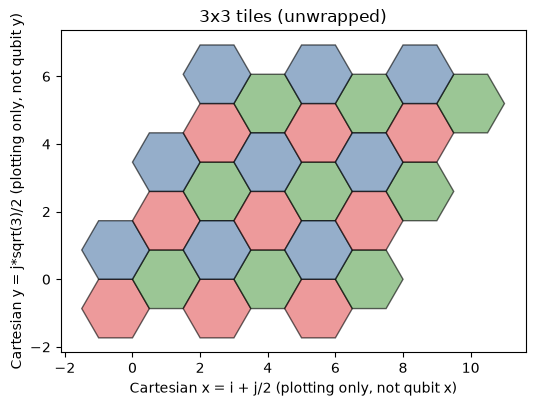

In [4]:
def to_xy(p):
    """Cartesian embedding for plotting only -- NOT the qubit (x, y) label.
    Qubits are always addressed by their axial (i, j) pair (net.points,
    Spacetime.q(x, y, t)); this is only used to lay hexagons out on a plot."""
    i, j = p
    return (i + 0.5 * j, (np.sqrt(3) / 2) * j)


COLOURS = {"red": "#e15759", "green": "#59a14f", "blue": "#4e79a7"}


def plot_patch(x_max, y_max, ax=None):
    """Plot an unwrapped x_max x y_max patch of tiles (no periodic wrap,
    so hexagons near the edge render as ordinary finite hexagons)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    for a in range(x_max):
        for b in range(y_max):
            tx, ty = 3 * a, 3 * b
            for colour, (dx, dy) in TILE_OFFSETS.items():
                c = (tx + dx, ty + dy)
                verts = [to_xy((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                ax.add_patch(Polygon(verts, closed=True, facecolor=COLOURS[colour],
                                      edgecolor="black", linewidth=1, alpha=0.6))
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xlabel("Cartesian x = i + j/2 (plotting only, not qubit x)")
    ax.set_ylabel("Cartesian y = j*sqrt(3)/2 (plotting only, not qubit y)")
    ax.set_title(f"{x_max}x{y_max} tiles (unwrapped)")
    return ax


plot_patch(3, 3)
plt.show()

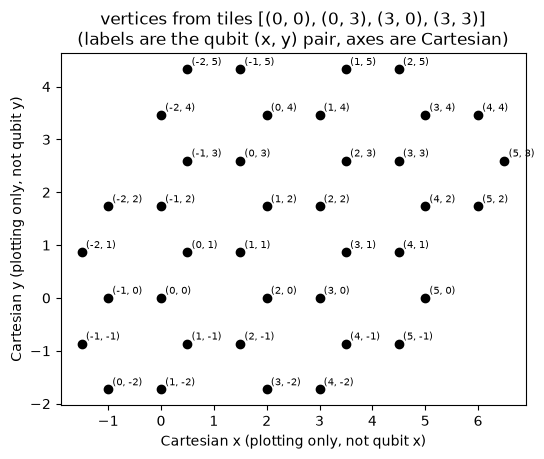

39 distinct vertices


In [5]:
tiles = [(0, 0), (0, 3), (3, 0), (3, 3)]

verts = set()
for (tx, ty) in tiles:
    for colour, (dx, dy) in TILE_OFFSETS.items():
        c = (tx + dx, ty + dy)
        for ox, oy in HEX_DIRS:
            verts.add((c[0] + ox, c[1] + oy))
verts = sorted(verts)

xs, ys = zip(*(to_xy(p) for p in verts))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xs, ys, color="black", zorder=2)
for p, x, y in zip(verts, xs, ys):
    ax.annotate(str(p), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_aspect("equal")
ax.set_xlabel("Cartesian x (plotting only, not qubit x)")
ax.set_ylabel("Cartesian y (plotting only, not qubit y)")
ax.set_title(f"vertices from tiles {tiles}\n(labels are the qubit (x, y) pair, axes are Cartesian)")
plt.show()

print(f"{len(verts)} distinct vertices")

### Check the periodic boundary conditions

Tiles `(0,0), (3,0), (0,3), (3,3)` are exactly the 4 tiles of `HexLattice(2, 2)`
(period `(6, 6)`) — the smallest lattice that still contains all of them, so
wrapping is forced to actually do something. Plot the wrapped points (black),
the fundamental-cell boundary (red), and a few periodic images (grey, shifted
by whole periods) — if PBC is implemented correctly the grey copies should
tile seamlessly against the black cell with no gaps or collisions.

period = (6, 6), wrapped distinct points = 24  (unwrapped was 39)


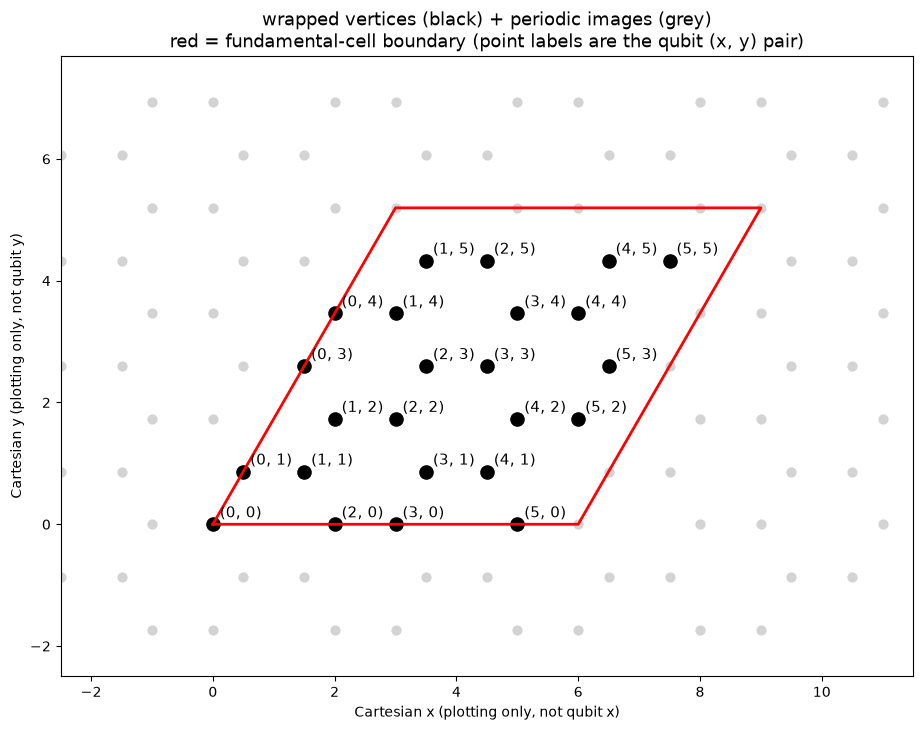

In [6]:
net_small = HexLattice(2, 2)  # tiles (0,0),(3,0),(0,3),(3,3); period (6,6)
print(f"period = ({net_small.Lx}, {net_small.Ly}), wrapped distinct points = {len(net_small.points)}"
      f"  (unwrapped was {len(verts)})")

Tx = to_xy((net_small.Lx, 0))
Ty = to_xy((0, net_small.Ly))
base_xy = [to_xy(p) for p in net_small.points]

fig, ax = plt.subplots(figsize=(11, 11))
for sa in (-1, 0, 1):
    for sb in (-1, 0, 1):
        is_origin = (sa, sb) == (0, 0)
        shifted = [(x + sa * Tx[0] + sb * Ty[0], y + sa * Tx[1] + sb * Ty[1]) for x, y in base_xy]
        xs, ys = zip(*shifted)
        ax.scatter(xs, ys, color="black" if is_origin else "lightgray",
                   s=90 if is_origin else 40, zorder=2 if is_origin else 1)

corners = [(0, 0), Tx, (Tx[0] + Ty[0], Tx[1] + Ty[1]), Ty, (0, 0)]
ax.plot(*zip(*corners), color="red", linewidth=2)

for p, (x, y) in zip(net_small.points, base_xy):
    ax.annotate(str(p), (x, y), fontsize=11, xytext=(5, 5), textcoords="offset points")

ax.set_aspect("equal")
margin = 2.5
xs_cell, ys_cell = zip(*corners)
ax.set_xlim(min(xs_cell) - margin, max(xs_cell) + margin)
ax.set_ylim(min(ys_cell) - margin, max(ys_cell) + margin)
ax.set_xlabel("Cartesian x (plotting only, not qubit x)")
ax.set_ylabel("Cartesian y (plotting only, not qubit y)")
ax.set_title("wrapped vertices (black) + periodic images (grey)\nred = fundamental-cell boundary "
             "(point labels are the qubit (x, y) pair)", fontsize=13)
plt.show()

### Raw-coordinate plot

Unlike the hexagon-shaped plots above, this one places each point at its own
`(x, y)` axial coordinate directly — no Cartesian rescaling — so it's a
literal picture of what `Spacetime.q(x, y, t)` addresses. Useful for reading
off which points share an `x` or `y` value, tracing edge-colour patterns, etc.
Edges that wrap across the periodic boundary are marked with a square at each
endpoint instead of a connecting line (drawing the line would cut across the
whole plot).

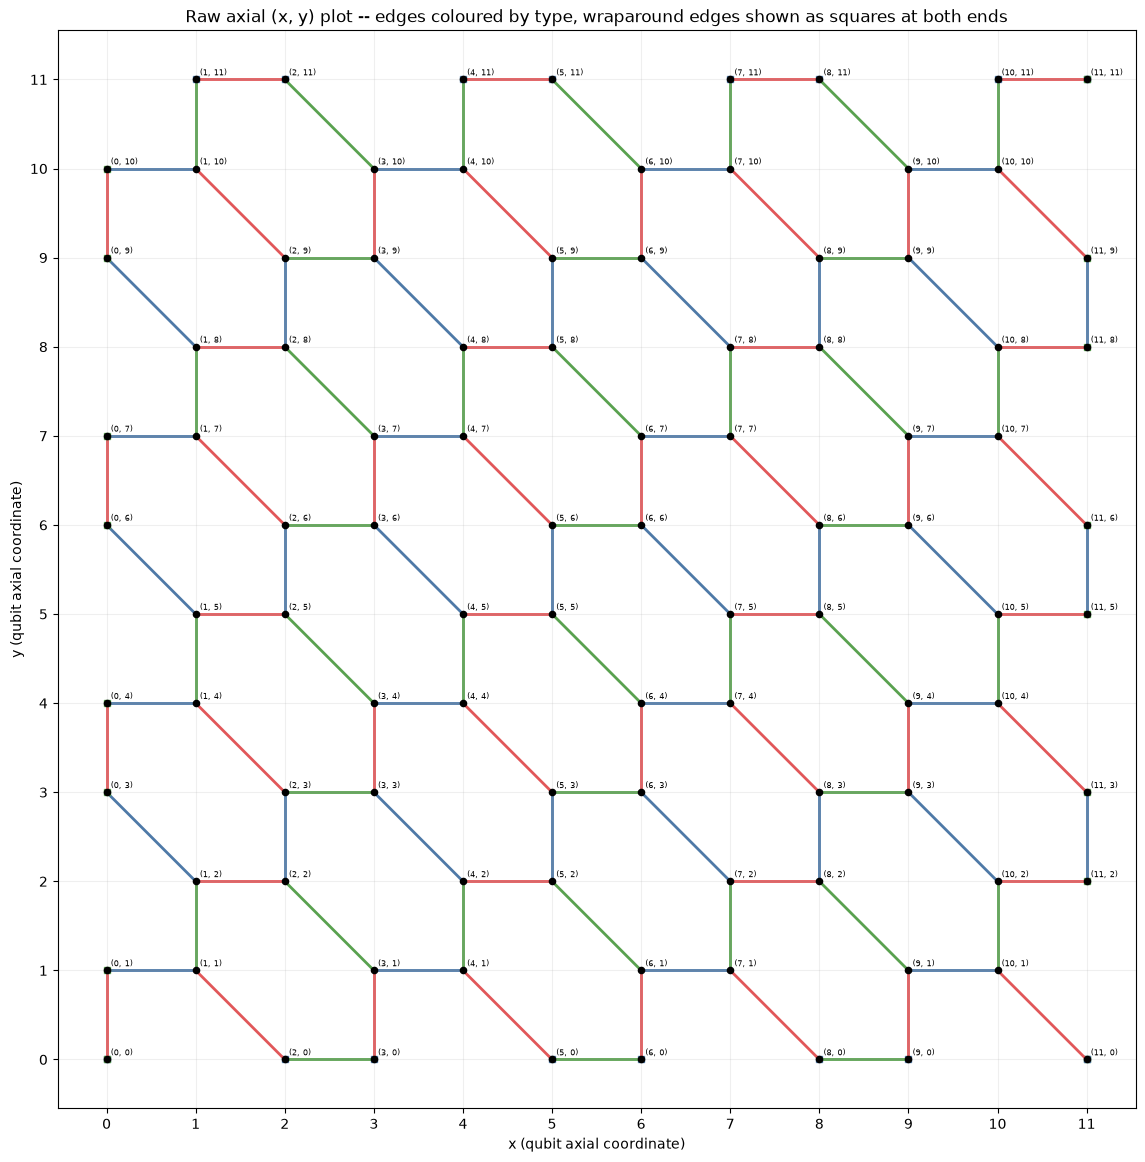

In [7]:
def plot_raw(net, ax=None, figsize=(14, 14)):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        di, dj = r[0] - p[0], r[1] - p[1]
        if (di, dj) in HEX_DIRS or (-di, -dj) in HEX_DIRS:
            ax.plot([p[0], r[0]], [p[1], r[1]], color=COLOURS[colour], linewidth=2, zorder=1)
        else:
            # wraps across the periodic boundary -- mark both ends instead of
            # drawing a line straight across the plot
            ax.plot(*p, marker="s", color=COLOURS[colour], markersize=5, zorder=1)
            ax.plot(*r, marker="s", color=COLOURS[colour], markersize=5, zorder=1)

    xs, ys = zip(*net.points)
    ax.scatter(xs, ys, color="black", s=20, zorder=2)
    for p in net.points:
        ax.annotate(f"{p}", p, fontsize=6, xytext=(3, 3), textcoords="offset points", zorder=3)

    ax.set_xlabel("x (qubit axial coordinate)")
    ax.set_ylabel("y (qubit axial coordinate)")
    ax.set_xticks(range(net.Lx))
    ax.set_yticks(range(net.Ly))
    ax.grid(alpha=0.2)
    ax.set_aspect("equal")
    ax.set_title("Raw axial (x, y) plot -- edges coloured by type, "
                 "wraparound edges shown as squares at both ends")
    return ax


plot_raw(net)
plt.show()

---
## 2. The circuit

Every spatial point `(x, y)` gets its own qubit at every timestep `t`, for
`total_t = 6 * n_cycles` timesteps, wrapping periodically in time just like
space: qubit `(x, y, total_t)` is qubit `(x, y, 0)`. So there are
`len(net.points) * total_t` qubits in total.

Every qubit starts in `|+>`. Two qubits get a `CZ` if they're the **same
vertex at adjacent (periodic) timesteps** — this is what links a vertex's
qubit at time `t` to its replacement at `t+1`.

Each *cycle* is 6 timesteps, and at each timestep exactly one colour's worth
of spatial edges gets fused (the fusion primitive — `CNOT a b; H a; M a b` —
is the same destructive Bell fusion proved in
`sixring_fbqc_walkthrough.ipynb`, giving both an XX and a ZZ record per
fusion). Since every point has exactly one edge of each colour (checked in §1
— degree 3, one red + one green + one blue), a single-colour step consumes
every qubit at that timestep exactly once:

| step | t (within cycle) | colour | label |
|---|---|---|---|
| 1 | 0 | red   | rXX |
| 2 | 1 | green | gZZ |
| 3 | 2 | blue  | bXX |
| 4 | 3 | red   | rZZ |
| 5 | 4 | green | gXX |
| 6 | 5 | blue  | bZZ |

This repeats for `n_cycles` cycles, until every qubit (at every point, every
timestep) has been consumed by exactly one fusion.

In [8]:
class Spacetime:
    """`net`'s points, each replicated over `total_t = 6 * n_cycles` timesteps
    that wrap periodically (timestep `total_t` is timestep `0`)."""

    def __init__(self, net, n_cycles):
        self.net = net
        self.n_cycles = n_cycles
        self.total_t = 6 * n_cycles
        self.point_id = {p: i for i, p in enumerate(net.points)}
        self.n_qubits = len(net.points) * self.total_t

    def q(self, x, y, t):
        return self.point_id[(x, y)] * self.total_t + (t % self.total_t)


# (colour, kind) for each of the 6 steps of one cycle
STEP_SCHEDULE = [("red", "XX"), ("green", "ZZ"), ("blue", "XX"),
                  ("red", "ZZ"), ("green", "XX"), ("blue", "ZZ")]


def build(st, p_meas=0.0, h_fusion_kinds=()):
    """Prepare |+> on every qubit, CZ each vertex to its own next (periodic)
    timestep, then run the 6-step colour/kind fusion schedule once per cycle.
    Steps whose kind is in `h_fusion_kinds` use §8's H-fusion (H on both
    qubits first); the default is the regular fusion everywhere.

    Returns (circuit, records, nmeas) where records maps
    (t, colour, kind, p, r) -> (XX index, ZZ index) in absolute measurement
    order, for the fusion between points p and r at timestep t."""
    net = st.net
    circuit_ = stim.Circuit()
    circuit_.append("R", range(st.n_qubits))
    circuit_.append("H", range(st.n_qubits))

    for p in net.points:
        for t in range(st.total_t):
            circuit_.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))

    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                qa, qb = st.q(*p, t), st.q(*r, t)
                if kind in h_fusion_kinds:
                    circuit_.append("H", [qa, qb])
                circuit_.append("CNOT", [qa, qb])
                circuit_.append("H", [qa])
                if p_meas > 0:
                    circuit_.append("M", [qa, qb], p_meas)
                else:
                    circuit_.append("M", [qa, qb])
                records[(t, colour, kind, p, r)] = (n, n + 1)
                n += 2

    return circuit_, records, n


st = Spacetime(net, n_cycles=2)
circ, records, nmeas = build(st)
print(f"points = {len(net.points)}, total_t = {st.total_t}, qubits = {st.n_qubits}")
print(f"fusions = {nmeas // 2}, measurement records = {nmeas}")

points = 96, total_t = 12, qubits = 1152
fusions = 576, measurement records = 1152


### Sanity check: every qubit consumed exactly once

Same check as the sixring notebook's fusion-table check: every one of the
`st.n_qubits` qubits should be consumed by **exactly one** fusion. If a qubit
is consumed twice the circuit is nonsense; if zero times it dangles.

In [9]:
def consumption(st, records):
    used = Counter()
    for (t, colour, kind, p, r) in records:
        used[st.q(*p, t)] += 1
        used[st.q(*r, t)] += 1
    return used

used = consumption(st, records)
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [i for i in range(st.n_qubits) if used[i] != 1]
print("qubits not consumed exactly once:", len(bad) if bad else "none")

# each step should fuse every point present at that timestep exactly once
per_t = Counter(t for (t, *_rest) in records)
print("fusions per timestep, distribution of counts:", dict(Counter(per_t.values())))
print("expected per timestep:", len(net.points) // 2)

distribution of 'times consumed': {1: 1152}
qubits not consumed exactly once: none
fusions per timestep, distribution of counts: {48: 12}
expected per timestep: 48


---
## 3. Detectors

For a hexagon `H` (colour red, green or blue), let `XX(c, S)` / `ZZ(c, S)` be
the XX/ZZ fusion outcome of the edges of `H`'s boundary that get fused at step
`S` of cycle `c` — every fusion primitive gives both an XX and a ZZ record
regardless of that step's own schedule label, so both are always available to
pull from. `H` has exactly 3 edges of each of its two non-native colours on
its boundary (never its own colour — checked in §1); each term is the **XOR
of all 3** same-coloured boundary edges' records at that step.

Six detector patterns, one X and one Z per hexagon colour (`S` runs 1-6 within
a cycle; `c+1` wraps periodically, same as the geometry). Each is a 6-step
window with the hexagon's own colour's 2 steps removed, leaving 4:

```
Blue  X = (c,1) (c,2) (c,4) (c,5)
Blue  Z = (c,4) (c,5) (c+1,1) (c+1,2)
Red   X = (c,5) (c,6) (c+1,2) (c+1,3)
Red   Z = (c,2) (c,3) (c,5)   (c,6)
Green X = (c,3) (c,4) (c,6)   (c+1,1)
Green Z = (c,6) (c+1,1) (c+1,3) (c+1,4)
```

Which of XX/ZZ each term actually pulls turned out **not** to be a fixed
per-detector label — verified empirically (§ below) rather than guessed: a Z
detector takes each step's own schedule kind (step 2 is native `ZZ`, so the Z
detector's `(c,2)` term is its ZZ record); an X detector takes the *opposite*
of each step's native kind. This holds uniformly across all three colours.
One hexagon's detector is weight 12 (4 steps x 3 edges), matching the sixring
notebook's weight-12 checks.

In [10]:
# (cycle offset, step 1-6) for each of the 4 terms of each detector.
# Which of XX/ZZ each term pulls is *not* listed here -- it's derived from the
# X/Z-vs-native-kind rule below.
DETECTOR_PATTERNS = {
    ("blue",  "X"): [(0, 1), (0, 2), (0, 4), (0, 5)],
    ("blue",  "Z"): [(0, 4), (0, 5), (1, 1), (1, 2)],
    ("red",   "X"): [(0, 5), (0, 6), (1, 2), (1, 3)],
    ("red",   "Z"): [(0, 2), (0, 3), (0, 5), (0, 6)],
    ("green", "X"): [(0, 3), (0, 4), (0, 6), (1, 1)],
    ("green", "Z"): [(0, 6), (1, 1), (1, 3), (1, 4)],
}


def hexagon_boundary_by_colour(net, colour, centre):
    """The 6 boundary edges of hexagon (colour, centre), grouped by edge colour
    (3 of each of the 2 non-native colours)."""
    verts = net.hexagons[(colour, centre)]
    by_colour = defaultdict(list)
    for k in range(6):
        p, r = verts[k], verts[(k + 1) % 6]
        by_colour[net.colour_of_edge(p, r)].append((p, r))
    return by_colour


def find_record(records, t, colour, kind, p, r):
    return records.get((t, colour, kind, p, r)) or records[(t, colour, kind, r, p)]


def hexagon_check_rows(st, records, nmeas):
    """One GF(2) row per (hexagon, X/Z, cycle). Returns (rows, meta), meta[i]
    describing rows[i] as (hexagon colour, centre, 'X'/'Z', cycle).

    A Z detector's term at step S takes step S's own (native) schedule kind;
    an X detector's term takes the opposite kind."""
    net = st.net
    rows, meta = [], []
    for (hex_colour, centre) in net.hexagons:
        by_colour = hexagon_boundary_by_colour(net, hex_colour, centre)
        for xz in ("X", "Z"):
            pattern = DETECTOR_PATTERNS[(hex_colour, xz)]
            for c in range(st.n_cycles):
                v = np.zeros(nmeas, dtype=np.uint8)
                for (c_off, step) in pattern:
                    colour, native_kind = STEP_SCHEDULE[step - 1]
                    term_kind = native_kind if xz == "Z" else \
                        ("ZZ" if native_kind == "XX" else "XX")
                    t = (6 * (c + c_off) + (step - 1)) % st.total_t
                    for (p, r) in by_colour[colour]:
                        rxx, rzz = find_record(records, t, colour, native_kind, p, r)
                        v[rxx if term_kind == "XX" else rzz] ^= 1
                rows.append(v)
                meta.append((hex_colour, centre, xz, c))
    return np.array(rows, dtype=np.uint8), meta


hex_checks, hex_meta = hexagon_check_rows(st, records, nmeas)
print(f"hexagons = {len(net.hexagons)}, cycles = {st.n_cycles} -> "
      f"detectors = {len(hex_checks)} (expect {len(net.hexagons) * 2 * st.n_cycles})")
print("detector weight distribution:", dict(Counter(hex_checks.sum(axis=1).tolist())))

hexagons = 48, cycles = 2 -> detectors = 192 (expect 192)
detector weight distribution: {12: 192}


In [11]:
# GF(2) linear-algebra utilities (same as sixring_fbqc_walkthrough.ipynb §4).

def rref(A):
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def nullspace(A):
    A = np.asarray(A, dtype=np.uint8) % 2
    R, piv = rref(A)
    pivset = set(piv)
    free = [c for c in range(A.shape[1]) if c not in pivset]
    B = np.zeros((len(free), A.shape[1]), dtype=np.uint8)
    for t, f in enumerate(free):
        B[t, f] = 1
        for ri, p in enumerate(piv):
            if R[ri, f]:
                B[t, p] = 1
    return B


def deterministic_parities(circuit, nmeas, extra=400):
    """Outcome subsets whose parity is constant across all noiseless shots."""
    S = circuit.compile_sampler().sample(shots=nmeas + extra).astype(np.uint8)
    aug = np.concatenate([S % 2, np.ones((len(S), 1), dtype=np.uint8)], axis=1)
    ns = nullspace(aug)
    return ns[:, :nmeas]      # drop the constant column


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0


print(f"hexagon checks: {len(hex_checks)}, rank {rank(hex_checks)}")

hexagon checks: 192, rank 190


### Stim's determinism check

Same regression test as sixring §4. `detector_error_model()` **refuses to
build** if any detector is not deterministic in the noiseless circuit — so
this one call validates every hexagon detector at once. Any geometry error or
schedule mistake throws here.

In [12]:
def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for row in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(row)])

clean, clean_records, clean_nmeas = build(st, 0.0)
clean_checks, _ = hexagon_check_rows(st, clean_records, clean_nmeas)
add_detectors(clean, clean_checks, clean_nmeas)

try:
    dem = clean.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {clean.num_detectors} detectors deterministic")
except Exception as e:
    print("FAILED:", str(e)[:400])

DEM built: all 192 detectors deterministic


### Nullspace check

An independent check on top of `detector_error_model()`: sample the clean
circuit and find `deterministic_parities` — every outcome-subset whose parity
is constant across shots (the full deterministic space, found by brute-force
sampling + nullspace, not by construction). Every hexagon check should lie
**inside** that space: adding a valid check to a basis for it must not raise
the rank. If a check's row isn't already in the span, it's not actually a
deterministic quantity and appending it increases the rank.

In [13]:
V = deterministic_parities(clean, clean_nmeas)
base_rank = rank(V)
print(f"deterministic-parity space: dimension {base_rank} (of {clean_nmeas} outcomes)")

combined_rank = rank(np.concatenate([V, clean_checks], axis=0))
print(f"rank after adding all {len(clean_checks)} hexagon checks: {combined_rank}")

if combined_rank == base_rank:
    print("all hexagon checks lie inside the deterministic-parity nullspace: OK")
else:
    bad = [i for i, row in enumerate(clean_checks)
           if rank(np.concatenate([V, row[None, :]], axis=0)) != base_rank]
    print(f"NOT deterministic: {len(bad)} checks -> {[hex_meta[i] for i in bad[:10]]}")

deterministic-parity space: dimension 196 (of 1152 outcomes)
rank after adding all 192 hexagon checks: 196
all hexagon checks lie inside the deterministic-parity nullspace: OK


---
## 4. Logicals

The deterministic-parity space (§3, dimension 196 here) is bigger than the
check space (rank 190) — the leftover dimensions are the logical operators.
Several rounds of hand-deriving a closed-form "vertical/horizontal/timelike"
recipe (mirroring sixring §5's closed-form rewrite) didn't survive contact
with the circuit — every attempt failed `has_flow`, including two that were
provably impossible (zero-dimensional restricted nullspace search, meaning no
choice of kind for that exact edge set could ever be deterministic). So this
section uses sixring §5's *primary* method directly instead: find the
logicals by brute-force nullspace search, same as the checks were
independently verified against. `_Basis` is copied verbatim from
`sixring_fbqc_walkthrough.ipynb`.

In [14]:
class _Basis:
    """Incremental GF(2) row-echelon basis (verbatim from sixring_fbqc_walkthrough.ipynb §5).
    Feed it vectors one at a time via `add(v)`: it keeps only the ones linearly
    independent of everything added so far. Each row is a single Python int
    used as an arbitrary-length bitmask."""

    def __init__(self, n_bits):
        self.basis_rows = []
        self.pivot_bits = []

    def _pack(self, v):
        candidate = 0
        for bit in np.flatnonzero(v):
            candidate |= 1 << int(bit)
        return candidate

    def add(self, v):
        candidate = self._pack(v)
        for row, pivot in zip(self.basis_rows, self.pivot_bits):
            if (candidate >> pivot) & 1:
                candidate ^= row
        if candidate == 0:
            return False
        new_pivot = (candidate & -candidate).bit_length() - 1
        self.basis_rows.append(candidate)
        self.pivot_bits.append(new_pivot)
        return True

    @property
    def rank(self):
        return len(self.basis_rows)


def logicals(checks, V):
    """Deterministic-parity rows independent of `checks` -- the logical space."""
    Bs = _Basis(checks.shape[1])
    for v in checks:
        Bs.add(v)
    return np.array([v for v in V if Bs.add(v)], dtype=np.uint8)


logs = logicals(clean_checks, V)
print(f"logical operators found: {len(logs)}  (expect 6)")
print("weight distribution:", dict(Counter(logs.sum(axis=1).tolist())))

logical operators found: 6  (expect 6)
weight distribution: {144: 2, 68: 2, 64: 2}


### Nullspace check

Two things worth confirming independently of how `logs` was constructed:
1. Every logical is actually deterministic (`has_flow` on each, like sixring's
   single-check debug example).
2. Checks + logicals together span **exactly** the full deterministic-parity
   space — no more, no less. If checks and logicals overlapped, or if there
   were leftover deterministic dimensions neither basis captured, this rank
   comparison would catch it.

In [15]:
# 1. each logical is independently deterministic via has_flow
all_det = True
for i, row in enumerate(logs):
    terms = " xor ".join(f"rec[{int(j) - clean_nmeas}]" for j in np.flatnonzero(row))
    ok = clean.has_flow(stim.Flow(f"1 -> {terms}"))
    all_det &= ok
    print(f"logical {i}: weight {row.sum():3d}  has_flow={ok}")
print("all logicals deterministic:", all_det)

# 2. checks + logicals span exactly the full deterministic space
combined = np.concatenate([clean_checks, logs], axis=0)
print(f"\nrank(checks) = {rank(clean_checks)}, rank(logs) = {rank(logs)}, "
      f"rank(checks + logs) = {rank(combined)}, base_rank = {base_rank}")
assert rank(clean_checks) + rank(logs) == base_rank == rank(combined), \
    "checks and logicals should partition the full deterministic space exactly"
print("checks + logicals exactly span the deterministic-parity space: OK")

logical 0: weight 144  has_flow=True

logical 1: weight 144  has_flow=True
logical 2: weight  68  has_flow=True
logical 3: weight  68  has_flow=True
logical 4: weight  64  has_flow=True
logical 5: weight  64  has_flow=True
all logicals deterministic: True



rank(checks) = 190, rank(logs) = 6, rank(checks + logs) = 196, base_rank = 196
checks + logicals exactly span the deterministic-parity space: OK


---
## 5. Closed-form logicals (hand-derived)

Section 4 found all 6 logicals by brute-force nullspace search -- correct,
but opaque about *why* those are the logicals. This section gives each one
an explicit, hand-derived rule for which edges/kinds it uses, verified
directly against the circuit (`has_flow`) rather than trusted from the
derivation. Full write-up, including the two false starts before the
minimal Vertical X/Horizontal X form was found, is in
`vertical_horizontal_logicals_notes.txt`.

Two of the six (Vertical Z, Horizontal Z) **march** a single column/row
across the *whole* lattice, one position every 2 timesteps, so they only
close after sweeping every column/row exactly once -- this needs the full
period `n_cycles = x_max` (`= Lx/3`), not the `n_cycles=2` demo circuit from
§2-4. So this section rebuilds its own circuit at that size, on the same
`net`.</cell>

In [16]:
st5 = Spacetime(net, n_cycles=net.x_max)
circ5, records5, nmeas5 = build(st5)
print(f"st5: n_cycles={st5.n_cycles}, total_t={st5.total_t}, "
      f"n_qubits={st5.n_qubits}, nmeas={nmeas5}")

st5: n_cycles=4, total_t=24, n_qubits=2304, nmeas=2304


### Column/row native colour

Every point's edges split by *axis*: an **internal** edge joins two points
with the same `x` (or the same `y`); a **crossing** edge joins column/row `k`
to `k+1`. Both are a function of `k % 3` only, colour-wise -- but internal
and crossing are offset from each other, and independently so for x vs. y.
Rather than assume this (or copy it from the notes file), derive both tables
directly from `net.edge_colour` by classifying every edge by its offset
along the axis, and assert each residue gives one consistent colour.</cell>

In [17]:
def internal_crossing_tables(net, axis):
    """Colour of the same-`axis`-coordinate ('internal') edge and the
    axis-coordinate k->k+1 ('crossing') edge, as a function of k%3."""
    length = net.Lx if axis == 0 else net.Ly
    internal, crossing = defaultdict(set), defaultdict(set)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        d = (r[axis] - p[axis]) % length
        if d == 0:
            internal[p[axis] % 3].add(colour)
        elif d == 1:
            crossing[p[axis] % 3].add(colour)
        elif d == length - 1:
            crossing[r[axis] % 3].add(colour)
        else:
            raise ValueError("edge spans more than one lattice step", edge, d)
    assert all(len(v) == 1 for v in internal.values()), internal
    assert all(len(v) == 1 for v in crossing.values()), crossing
    return {k: v.pop() for k, v in internal.items()}, {k: v.pop() for k, v in crossing.items()}


def point_colour_edge(net, p, colour):
    """The unique edge of `colour` touching point p (every point has exactly
    one -- checked in §1)."""
    for edge, c in net.edge_colour.items():
        if c == colour and p in edge:
            return tuple(edge)
    raise KeyError(p, colour)


NATIVE_OF_X, CROSSING_OF_X = internal_crossing_tables(net, axis=0)
NATIVE_OF_Y, CROSSING_OF_Y = internal_crossing_tables(net, axis=1)
print("x: internal", NATIVE_OF_X, " crossing(k,k+1)", CROSSING_OF_X)
print("y: internal", NATIVE_OF_Y, " crossing(k,k+1)", CROSSING_OF_Y)

x: internal {1: 'green', 2: 'blue', 0: 'red'}  crossing(k,k+1) {0: 'blue', 2: 'green', 1: 'red'}
y: internal {0: 'green', 1: 'blue', 2: 'red'}  crossing(k,k+1) {1: 'green', 2: 'blue', 0: 'red'}


### Timelike X / Timelike Z

Lives at a FIXED cycle -- no spatial sweep -- and uses EVERY edge of ALL
THREE colours, at three consecutive timesteps spanning either the first half
of a cycle (steps 1,2,3) or the second half (steps 4,5,6). Weight is just the
full lattice edge count at 3 consecutive timesteps; identical every cycle.</cell>

In [18]:
def timelike_row(net, st, records, nmeas, c0, steps, mode):
    """`mode='native'` pulls each step's own schedule kind; `mode='anti'`
    pulls the opposite -- same native/anti-native rule as the §3 detectors."""
    v = np.zeros(nmeas, dtype=np.uint8)
    for step in steps:
        colour, native = STEP_SCHEDULE[step - 1]
        t = (6 * c0 + (step - 1)) % st.total_t
        kind = native if mode == "native" else ("ZZ" if native == "XX" else "XX")
        for edge, c in net.edge_colour.items():
            if c != colour:
                continue
            p, r = tuple(edge)
            rxx, rzz = find_record(records, t, colour, native, p, r)
            v[rxx if kind == "XX" else rzz] ^= 1
    return v


TX = timelike_row(net, st5, records5, nmeas5, c0=0, steps=[1, 2, 3], mode="anti")
TZ = timelike_row(net, st5, records5, nmeas5, c0=1, steps=[4, 5, 6], mode="native")
print(f"Timelike X weight {int(TX.sum())}, Timelike Z weight {int(TZ.sum())}")

Timelike X weight 144, Timelike Z weight 144


### Vertical Z / Horizontal Z -- the "marching" closed form

Sweeps a SINGLE column (or row) position across the WHOLE lattice, one
position every 2 timesteps, using the full period. At each timestep, every
point currently in that column contributes its edge of the round's colour:
if that colour is the column's own (internal) colour the edge is shared by
two points in the same enumeration and must be de-duplicated; a crossing
edge (reaching into a neighbouring column) needs no de-dup. Requires FULL
closure -- `n_cycles = Lx/3` exactly -- so the marching position returns to
its start after sweeping every column once.</cell>

In [19]:
def marching_row(net, st, records, nmeas, axis, start, t0, kind_own, kind_ext, direction=-1):
    v = np.zeros(nmeas, dtype=np.uint8)
    length = net.Lx if axis == 0 else net.Ly
    native_map = NATIVE_OF_X if axis == 0 else NATIVE_OF_Y
    for k in range(st.total_t):
        t = (t0 + k) % st.total_t
        colour, native = STEP_SCHEDULE[t % 6]
        pos = (start + direction * (k // 2)) % length
        is_own = (colour == native_map[pos % 3])
        seen = set()
        for p in net.points:
            if p[axis] != pos:
                continue
            edge = point_colour_edge(net, p, colour)
            if is_own:
                key = frozenset(edge)
                if key in seen:
                    continue
                seen.add(key)
            rxx, rzz = find_record(records, t, colour, native, *edge)
            v[rxx if (kind_own if is_own else kind_ext) == "XX" else rzz] ^= 1
    return v


VZ = marching_row(net, st5, records5, nmeas5, axis=0, start=3, t0=0, kind_own="XX", kind_ext="ZZ")
HZ = marching_row(net, st5, records5, nmeas5, axis=1, start=2, t0=0, kind_own="XX", kind_ext="ZZ")
print(f"Vertical Z weight {int(VZ.sum())}, Horizontal Z weight {int(HZ.sum())}")

Vertical Z weight 144, Horizontal Z weight 144


### Vertical X / Horizontal X -- the stationary closed form

Unlike Vertical/Horizontal Z, this one does NOT march: it's fixed at TWO
adjacent columns (or rows) for ALL points along the other axis, repeating
IDENTICALLY every cycle, with the schedule's own colour order (red, green,
blue) mapped straight onto three fixed spatial roles -- no exceptions
anywhere. `p0` must be red's own internal residue for that axis (`p0 % 3`
matching `NATIVE_OF_X[·] == "red"` or `NATIVE_OF_Y[·] == "red"`); `p1 = p0+1`.

This is the minimal representative -- brute-force nullspace search initially
returns a heavier "staircase + seam exception" logical in the same class
(worked out and superseded this session; see the notes file), which looked
physically tied to the time-periodic wraparound but wasn't: logicals are
only defined up to addition of checks, and the exception is just an artifact
of which coset member the search happens to return.</cell>

In [20]:
def build_stationary(net, st, records, nmeas, axis, p0, p1):
    v = np.zeros(nmeas, dtype=np.uint8)
    pattern = [({p0}, "ZZ"), ({p1}, "XX"), ({p0, p1}, "ZZ"),
               ({p0}, "XX"), ({p1}, "ZZ"), ({p0, p1}, "XX")]
    for c in range(st.n_cycles):
        for step, (ps, kind) in enumerate(pattern):
            t = 6 * c + step
            colour, native = STEP_SCHEDULE[step]
            for edge, col in net.edge_colour.items():
                if col != colour:
                    continue
                p, r = tuple(edge)
                if {p[axis], r[axis]} != ps:
                    continue
                rxx, rzz = find_record(records, t, colour, native, p, r)
                v[rxx if kind == "XX" else rzz] ^= 1
    return v


VX = build_stationary(net, st5, records5, nmeas5, axis=0, p0=0, p1=1)
HX = build_stationary(net, st5, records5, nmeas5, axis=1, p0=2, p1=3)
print(f"Vertical X weight {int(VX.sum())}, Horizontal X weight {int(HX.sum())}")

Vertical X weight 128, Horizontal X weight 128


### Sanity check

Two things worth confirming independently of how each closed form was
constructed, mirroring §4: (1) each is deterministic (`has_flow`) on its
own; (2) all 6 are independent of the hexagon checks *and* of each other --
adding all 6 to the check basis should raise the rank by exactly 6, no more
and no less.</cell>

In [21]:
closed_forms = {"Timelike X": TX, "Timelike Z": TZ, "Vertical Z": VZ,
                 "Horizontal Z": HZ, "Vertical X": VX, "Horizontal X": HX}

all_det = True
for name, v in closed_forms.items():
    terms = " xor ".join(f"rec[{int(j) - nmeas5}]" for j in np.flatnonzero(v))
    ok = circ5.has_flow(stim.Flow(f"1 -> {terms}"))
    all_det &= ok
    print(f"{name:14s} weight {int(v.sum()):4d}  has_flow={ok}")
print("all 6 closed forms deterministic:", all_det)

checks5, meta5 = hexagon_check_rows(st5, records5, nmeas5)
r_checks = rank(checks5)
r_combined = rank(np.concatenate([checks5] + [v[None, :] for v in closed_forms.values()], axis=0))
print(f"\nrank(checks) = {r_checks}, rank(checks + 6 closed forms) = {r_combined}")
assert all_det and r_combined == r_checks + 6, \
    "closed forms should all be deterministic and add exactly 6 independent dimensions"
print("all 6 independent of checks and of each other: OK")

Timelike X     weight  144  has_flow=True

Timelike Z     weight  144  has_flow=True


Vertical Z     weight  144  has_flow=True


Horizontal Z   weight  144  has_flow=True
Vertical X     weight  128  has_flow=True
Horizontal X   weight  128  has_flow=True
all 6 closed forms deterministic: True

rank(checks) = 382, rank(checks + 6 closed forms) = 388
all 6 independent of checks and of each other: OK


---
## 6. Measurement-error threshold

Same recipe as `sixring_fbqc_walkthrough.ipynb` §5: the paper's
hardware-agnostic Pauli channel (`M(p)` flips a fusion outcome independently
with probability `p`), decoded with `pymatching` against the
`detector_error_model()`. A logical error is counted when **any** of the 6
observables (§5's closed-form logicals) is mispredicted.

Structure -- checks and logicals -- doesn't depend on `p`, so it's built
once per lattice size and cached, using the closed-form logicals directly
(no nullspace search). `has_flow` is *not* re-run here: it gets expensive
fast at these sizes (~3s/call at Lx=12, ~150s/call at Lx=18 -- timed
separately), and the closed form was already exhaustively verified above.</cell>

In [22]:
def closed_form_logicals(net, st, records, nmeas):
    """The §5 closed forms, assembled into one 6xN array."""
    TX = timelike_row(net, st, records, nmeas, c0=0, steps=[1, 2, 3], mode="anti")
    TZ = timelike_row(net, st, records, nmeas, c0=1, steps=[4, 5, 6], mode="native")
    VZ = marching_row(net, st, records, nmeas, axis=0, start=3, t0=0, kind_own="XX", kind_ext="ZZ")
    HZ = marching_row(net, st, records, nmeas, axis=1, start=2, t0=0, kind_own="XX", kind_ext="ZZ")
    VX = build_stationary(net, st, records, nmeas, axis=0, p0=0, p1=1)
    HX = build_stationary(net, st, records, nmeas, axis=1, p0=2, p1=3)
    return np.array([TX, TZ, VZ, HZ, VX, HX], dtype=np.uint8)


_memory_cache = {}

def hex_memory_circuit(x_max, p_meas=0.0):
    """Noisy circuit with checks -> DETECTOR and closed-form logicals ->
    OBSERVABLE_INCLUDE, for a square x_max x x_max lattice at full closure
    (n_cycles = x_max). Structure is built once per x_max and cached."""
    if x_max not in _memory_cache:
        net_ = HexLattice(x_max, x_max)
        st_ = Spacetime(net_, n_cycles=x_max)
        _, rec0, nm = build(st_)
        ch, _ = hexagon_check_rows(st_, rec0, nm)
        lg = closed_form_logicals(net_, st_, rec0, nm)
        _memory_cache[x_max] = (st_, ch, lg, nm)
        print(f"  [built Lx={3 * x_max}: outcomes={nm} checks={rank(ch)} logicals={len(lg)}]")
    st_, ch, lg, nmeas = _memory_cache[x_max]

    c, recs, nm2 = build(st_, p_meas)
    assert nm2 == nmeas
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for v in ch:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for t, v in enumerate(lg):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], t)
    return c


def logical_error_rate(x_max, p, shots=20000, seed=0):
    import pymatching
    c = hex_memory_circuit(x_max, p)
    matcher = pymatching.Matching.from_detector_error_model(
        c.detector_error_model(decompose_errors=True))
    dets, obs = c.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    pred = matcher.decode_batch(dets)
    return np.any(pred != obs, axis=1).sum() / shots

### Side question: does an odd `x_max` (Lx = 9, 15, ...) work?

Yes. Nothing in the closed-form construction depends on `x_max` being even
-- checked directly, not just assumed: at `x_max` = 2..6 (`Lx` = 6, 9, 12,
15, 18), every one of the 6 closed forms is `has_flow`-deterministic and
adds exactly 6 independent dimensions on top of the hexagon checks, same as
the even sizes in §5. So the sweep below includes `Lx = 9` alongside
6, 12, 18, rather than just asserting it works.</cell>

### Sweeping p_meas without rebuilding the circuit

The obvious loop -- call `logical_error_rate(x_max, p)` once per `(p, Lx)` --
spends almost all its time rebuilding something that doesn't depend on `p`.
Measured at Lx=18: 10.56s of each 12.71s call is `hex_memory_circuit`, while
the DEM and `Matching` construction it feeds are 0.01s each. Three facts make
that work avoidable:

1. **The noise is a classical readout flip.** `build` emits
   `M(qa, qb, p_meas)`, which reports the wrong outcome with probability `p`
   but leaves the post-measurement state alone, so it cannot propagate.
   Sampling the *noiseless* circuit once and flipping bits afterwards is
   therefore distributionally exact, not an approximation -- the same trick
   `erasure_only_sweep` uses below.
2. **The matching graph is `p`-independent.** Every edge carries the same
   weight, and MWPM is invariant under a uniform rescaling of weights.
   Checked directly: a matcher built at `p=0.011` gives predictions
   bit-for-bit identical to one built at `p=0.014`, same 7776 edges.
3. **Parities and decoding parallelize.** `rows_to_parities_packed` XORs 8
   shots at a time by packing the shots axis into bits (2.3x, identical
   output), and `decode_batch_parallel` shards `decode_batch` over forked
   workers (3.3x at 4 workers, identical output) -- same copy-on-write
   reasoning as the erasure decoder further down.

Net effect at Lx=18: a 10-point sweep goes 109.1s -> 42.3s, and the values
still reproduce the original per-`p` rebuild within shot noise (max |z| =
1.49 against the previously published numbers).

One tradeoff to be aware of: one raw sample is reused across every `p` on a
given curve, so points along a curve are correlated rather than independent
(again, exactly as `erasure_only_sweep` does). Each individual point is still
an unbiased binomial estimate.

In [23]:
import multiprocessing as mp
import pymatching


def rows_to_parities_packed(outcomes, rows, _cache={}):
    """Same result as rows_to_parities (defined in the erasure section below),
    but XORs 8 shots at a time by packing the shots axis into bits. Each row's
    column indices are cached, keyed on the rows array's id."""
    shots = outcomes.shape[0]
    packed = np.packbits(outcomes, axis=0)          # (ceil(shots/8), nmeas)

    key = id(rows)
    if key not in _cache:
        _cache[key] = [np.flatnonzero(rows[r]) for r in range(rows.shape[0])]
    idx_list = _cache[key]

    out_packed = np.zeros((packed.shape[0], rows.shape[0]), dtype=np.uint8)
    for r, idx in enumerate(idx_list):
        out_packed[:, r] = np.bitwise_xor.reduce(packed[:, idx], axis=1)
    return np.unpackbits(out_packed, axis=0, count=shots)


_pstate = {}


def _decode_worker(dets_chunk):
    """Runs in a forked child; the Matching is inherited copy-on-write."""
    return _pstate['matcher'].decode_batch(dets_chunk)


def decode_batch_parallel(matcher, dets, n_workers=4):
    """matcher.decode_batch sharded across forked workers."""
    if n_workers <= 1 or dets.shape[0] < 4 * n_workers:
        return matcher.decode_batch(dets)
    _pstate['matcher'] = matcher
    chunks = np.array_split(dets, n_workers, axis=0)
    ctx = mp.get_context("fork")
    with ctx.Pool(n_workers) as pool:
        parts = pool.map(_decode_worker, chunks)
    return np.concatenate(parts, axis=0)


def measurement_noise_sweep(x_max, ps, shots=20000, seed=1234, n_workers=4):
    """Sweep p_meas at fixed lattice size. Builds the circuit, matcher and
    raw sample once, then applies readout flips per p in post-processing."""
    c_ref = hex_memory_circuit(x_max, 0.010)        # any p: graph is p-independent
    matcher = pymatching.Matching.from_detector_error_model(
        c_ref.detector_error_model(decompose_errors=True))
    st_, ch, lg, nmeas = _memory_cache[x_max]
    circ_clean, _, nm = build(st_, 0.0)
    assert nm == nmeas
    raw = circ_clean.compile_sampler(
        seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rng = np.random.default_rng(seed)
    rates = []
    for p in ps:
        outcomes = raw ^ (rng.random(raw.shape) < p).astype(np.uint8)
        dets = rows_to_parities_packed(outcomes, ch)
        obs = rows_to_parities_packed(outcomes, lg)
        pred = decode_batch_parallel(matcher, dets, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates

In [24]:
import time

Ls = [12, 18, 24, 30]
x_maxes = [L // 3 for L in Ls]
ps_coarse = np.linspace(0.002, 0.015, 10)
# Dense band across the crossing, extended out to 0.011 at the same 1.11e-4
# spacing as the original 0.009-0.010 window. Two of these coincide with
# coarse-grid values, so the union is 27 points rather than 29.
ps_fine = np.linspace(0.009, 0.011, 19)
ps = np.union1d(ps_coarse, ps_fine)

t_sweep0 = time.time()
cols = {}
for L, xm in zip(Ls, x_maxes):
    t0 = time.time()
    cols[L] = measurement_noise_sweep(xm, ps, shots=20000, seed=1234, n_workers=4)
    print(f"  [Lx={L}: {len(ps)} points in {time.time()-t0:.1f}s]", flush=True)

# keep the original {p: [rate per L]} shape the cells below expect
rows = {p: [cols[L][j] for L in Ls] for j, p in enumerate(ps)}

print(f"\n{'p':>8} " + " ".join(f"{'Lx='+str(L):>9}" for L in Ls))
for p in ps:
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows[p]))
print(f"\ntotal sweep time: {time.time()-t_sweep0:.1f}s")

  [built Lx=12: outcomes=2304 checks=382 logicals=6]


  [Lx=12: 27 points in 22.2s]


  [built Lx=18: outcomes=7776 checks=1294 logicals=6]


  [Lx=18: 27 points in 90.2s]


  [built Lx=24: outcomes=18432 checks=3070 logicals=6]


  [Lx=24: 27 points in 263.7s]


  [built Lx=30: outcomes=36000 checks=5998 logicals=6]


  [Lx=30: 27 points in 482.2s]



       p     Lx=12     Lx=18     Lx=24     Lx=30
  0.0020    0.0004    0.0000    0.0000    0.0000
  0.0034    0.0053    0.0006    0.0001    0.0000
  0.0049    0.0229    0.0060    0.0013    0.0004
  0.0063    0.0568    0.0254    0.0097    0.0047
  0.0078    0.1208    0.0804    0.0474    0.0308
  0.0090    0.2048    0.1712    0.1394    0.1208
  0.0091    0.2161    0.1812    0.1537    0.1305
  0.0092    0.2175    0.1945    0.1625    0.1458
  0.0093    0.2274    0.2021    0.1782    0.1578
  0.0094    0.2334    0.2214    0.1983    0.1772
  0.0096    0.2388    0.2278    0.2100    0.1990
  0.0097    0.2515    0.2363    0.2223    0.2109
  0.0098    0.2604    0.2507    0.2382    0.2353
  0.0099    0.2676    0.2626    0.2602    0.2545
  0.0100    0.2847    0.2766    0.2817    0.2767
  0.0101    0.2864    0.2913    0.2927    0.2910
  0.0102    0.2951    0.2996    0.3066    0.3157
  0.0103    0.3057    0.3151    0.3330    0.3417
  0.0104    0.3159    0.3316    0.3494    0.3680
  0.0106    0.3230 

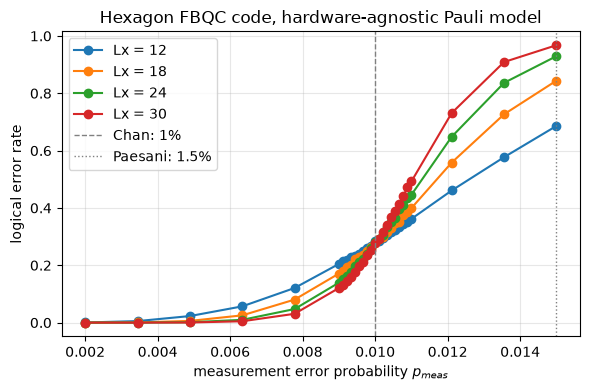

In [25]:
plt.figure(figsize=(6, 4))
for t, L in enumerate(Ls):
    plt.plot(ps, [rows[p][t] for p in ps], "o-", label=f"Lx = {L}")
plt.axvline(0.01, ls="--", c="grey", lw=1, label="Chan: 1%")
plt.axvline(0.015, ls=":", c="grey", lw=1, label="Paesani: 1.5%")
plt.xlabel("measurement error probability $p_{meas}$")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC code, hardware-agnostic Pauli model")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [26]:
def find_crossing(ps, r1, r2):
    """Track the last NONZERO difference seen; report a crossing only when a
    later nonzero difference has the opposite sign, interpolating between
    those two points. Skips over exact ties (both curves rounding to the
    same value, e.g. 0.0000 at low p from finite shot noise) rather than
    reporting them as a spurious crossing."""
    diff = np.array(r1, dtype=float) - np.array(r2, dtype=float)
    last_idx = None
    for i in range(len(diff)):
        if diff[i] == 0:
            continue
        if last_idx is not None and diff[last_idx] * diff[i] < 0:
            i0, i1 = last_idx, i
            frac = diff[i0] / (diff[i0] - diff[i1])
            return ps[i0] + frac * (ps[i1] - ps[i0])
        last_idx = i
    return None

print("Threshold estimate (pairwise crossings between adjacent Lx curves):")
for i in range(len(Ls) - 1):
    L1, L2 = Ls[i], Ls[i + 1]
    xc = find_crossing(ps, [rows[p][i] for p in ps], [rows[p][i + 1] for p in ps])
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=12 x Lx=18: p_threshold ~= 0.0101  (1.01%)
  Lx=18 x Lx=24: p_threshold ~= 0.0099  (0.99%)
  Lx=24 x Lx=30: p_threshold ~= 0.0101  (1.01%)


### Threshold estimate via finite-size scaling

Same method as the erasure-threshold section below (arXiv:2512.10399,
crossing + global finite-size-scaling fit), applied here to the
measurement-noise sweep above: `Ls` = 18,24,30, `p_meas` densified with 10
extra points between 0.009 and 0.010 around the suspected crossing (Chan:
1%, Paesani: 1.5%), `pymatching.Matching.from_detector_error_model` decode,
20000 shots at every point for every size.

All three sizes share one `ps` grid here (no sparse/dense split like the
erasure sweep needed), so the plain `find_crossing` from above is used
directly -- no grid-mismatch interpolation required. Variables in this
section carry a `_meas` suffix to avoid colliding with the `erasure_*` /
`p_c_*` names in the section below, which redo the same analysis for the
erasure sweep.

In [27]:
import csv
import os

out_dir_meas = "measurement_threshold"
os.makedirs(out_dir_meas, exist_ok=True)

n_shots_meas = 20000
csv_path_meas = os.path.join(out_dir_meas, "results.csv")
with open(csv_path_meas, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for p in ps:
        for L, v in zip(Ls, rows[p]):
            writer.writerow([p, L, v, n_shots_meas])
print(f"wrote {csv_path_meas}")

wrote measurement_threshold/results.csv


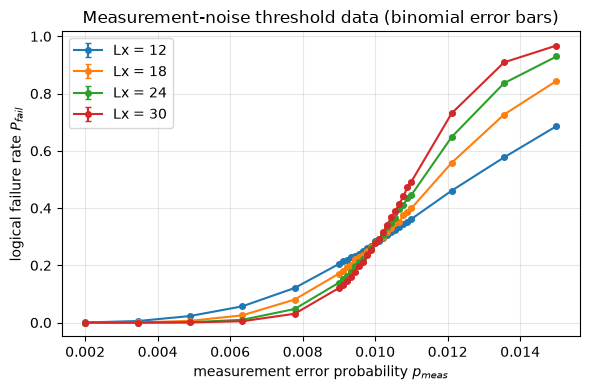

Monotonicity check (P_fail should be non-decreasing in p for each Lx):
  Lx=12: 0 decreasing step(s) out of 26
  Lx=18: 0 decreasing step(s) out of 26
  Lx=24: 0 decreasing step(s) out of 26
  Lx=30: 0 decreasing step(s) out of 26


In [28]:
import pandas as pd

df_meas = pd.read_csv(csv_path_meas)
df_meas["sigma"] = np.sqrt(df_meas["P_fail"] * (1 - df_meas["P_fail"]) / df_meas["n_shots"]).clip(lower=1e-4)

plt.figure(figsize=(6, 4))
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    plt.errorbar(grp["p"], grp["P_fail"], yerr=grp["sigma"], fmt="o-", ms=4, capsize=2, label=f"Lx = {L}")
plt.xlabel("measurement error probability $p_{meas}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("Measurement-noise threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p for each Lx):")
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    diffs = np.diff(grp["P_fail"].values)
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  Lx={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings:
  Lx=12 x Lx=18: p* = 0.0101
  Lx=18 x Lx=24: p* = 0.0099
  Lx=24 x Lx=30: p* = 0.0101
(note: only 1 residual dof -- the quoted uncertainty is not robust)

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.0101 +/- 0.0003


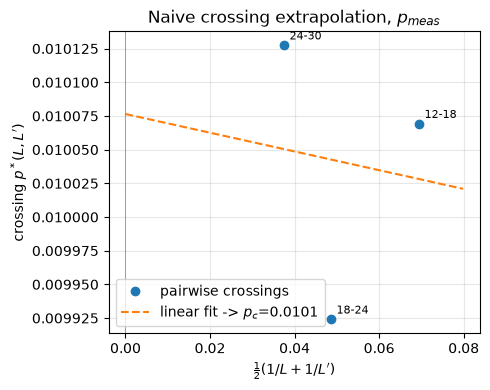

In [29]:
# Naive crossing-point estimate. Four sizes -> three adjacent crossings
# (12-18, 18-24, 24-30), so the 1/L_avg line is now actually fitted rather
# than drawn through two points. Still only 1 residual degree of freedom
# though, so the quoted uncertainty is fragile: it is set by how collinear
# those three crossings happen to land, and can come out absurdly small.
# The global fit below (task 3), which uses every raw point rather than a
# handful of derived crossings, remains the reliable estimate.
xs_meas, ps_star_meas, pair_labels_meas = [], [], []
print("Pairwise crossings:")
for L1, L2 in zip(Ls[:-1], Ls[1:]):
    i1, i2 = Ls.index(L1), Ls.index(L2)
    xc = find_crossing(ps, [rows[p][i1] for p in ps], [rows[p][i2] for p in ps])
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs_meas.append(x); ps_star_meas.append(xc); pair_labels_meas.append(f"{L1}-{L2}")
        print(f"  Lx={L1} x Lx={L2}: p* = {xc:.4f}")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found")

xs_meas, ps_star_meas = np.array(xs_meas), np.array(ps_star_meas)
if len(xs_meas) > 2:
    (c_slope_meas, p_c_naive_meas), cov_naive_meas = np.polyfit(xs_meas, ps_star_meas, 1, cov=True)
    p_c_naive_meas_err = np.sqrt(cov_naive_meas[1, 1])
else:
    c_slope_meas = (ps_star_meas[-1] - ps_star_meas[0]) / (xs_meas[-1] - xs_meas[0])
    p_c_naive_meas = ps_star_meas[0] - c_slope_meas * xs_meas[0]
    p_c_naive_meas_err = np.nan
    print("(only 2 crossings available -- extrapolated intercept has no meaningful uncertainty)")
dof_meas = len(xs_meas) - 2
if np.isfinite(p_c_naive_meas_err) and dof_meas <= 1:
    print(f"(note: only {dof_meas} residual dof -- the quoted uncertainty is not robust)")
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive_meas:.4f}"
      + (f" +/- {p_c_naive_meas_err:.4f}" if np.isfinite(p_c_naive_meas_err) else "  (uncertainty undefined)"))

plt.figure(figsize=(5, 4))
plt.plot(xs_meas, ps_star_meas, "o", label="pairwise crossings")
for x, y, lab in zip(xs_meas, ps_star_meas, pair_labels_meas):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs_meas.max() * 1.15, 50)
plt.plot(xx, c_slope_meas * xx + p_c_naive_meas, "--", label=f"linear fit -> $p_c$={p_c_naive_meas:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing extrapolation, $p_{meas}$")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [30]:
# Global finite-size-scaling fit: P_fail(p,L) ~= (1/2)[1 - erf(G(x)/sqrt(2))],
# x = (p - p_c) * L^(1/nu), G quadratic (5 params) or linear (4 params) in x.
from scipy.special import erf
from scipy.optimize import curve_fit

p_all_meas = df_meas["p"].to_numpy()
L_all_meas = df_meas["L"].to_numpy(dtype=float)
P_all_meas = df_meas["P_fail"].to_numpy()
sigma_all_meas = df_meas["sigma"].to_numpy()
X_meas = np.vstack([p_all_meas, L_all_meas])

def model_quad_meas(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear_meas(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

p_c0_meas = float(np.clip(p_c_naive_meas, p_all_meas.min(), p_all_meas.max()))
# A2/A1 bounds kept wide: with the tighter +/-5 box the quadratic term pegged
# exactly at A2=5, i.e. the fit was constrained rather than converged, which
# makes its reported errors meaningless. Widened until the optimum sits
# strictly inside the box.
bounds_quad_meas = ([p_all_meas.min(), 0.05, -20, -200, -200], [p_all_meas.max(), 10, 20, 0, 200])
bounds_lin_meas = ([p_all_meas.min(), 0.05, -20, -200], [p_all_meas.max(), 10, 20, 0])

popt_quad_meas, pcov_quad_meas = curve_fit(model_quad_meas, X_meas, P_all_meas,
                                            p0=[p_c0_meas, 1.0, 0.0, -5.0, 0.0],
                                            sigma=sigma_all_meas, absolute_sigma=True,
                                            bounds=bounds_quad_meas, maxfev=30000)
perr_quad_meas = np.sqrt(np.diag(pcov_quad_meas))

popt_lin_meas, pcov_lin_meas = curve_fit(model_linear_meas, X_meas, P_all_meas,
                                          p0=[p_c0_meas, 1.0, 0.0, -5.0],
                                          sigma=sigma_all_meas, absolute_sigma=True,
                                          bounds=bounds_lin_meas, maxfev=30000)
perr_lin_meas = np.sqrt(np.diag(pcov_lin_meas))

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_meas, perr_quad_meas):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin_meas, perr_lin_meas):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

# guard: a parameter sitting on its bound means the fit is constrained, not converged
for name, v, lo, hi in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_meas,
                            bounds_quad_meas[0], bounds_quad_meas[1]):
    if np.isclose(v, lo, rtol=1e-6) or np.isclose(v, hi, rtol=1e-6):
        print(f"  WARNING: quadratic fit parameter {name} = {v:.5f} is pinned to its bound")

Quadratic-erf fit (5 params):
  p_c = 0.00996 +/- 0.00001
  nu = 1.06473 +/- 0.00711
  A0 = 0.60862 +/- 0.00351
  A1 = -24.18521 +/- 0.44715
  A2 = 32.86789 +/- 1.15614
Linear-erf fit (4 params):
  p_c = 0.00993 +/- 0.00001
  nu = 1.20412 +/- 0.00755
  A0 = 0.63417 +/- 0.00386
  A1 = -32.44092 +/- 0.50707


In [31]:
# Model comparison: RSS, chi^2, AIC, BIC for quadratic-erf, linear-erf, and a
# no-L baseline sigmoid.
def model_baseline_meas(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

bounds_base_meas = ([p_all_meas.min(), 1e-5], [p_all_meas.max(), 1.0])
popt_base_meas, pcov_base_meas = curve_fit(model_baseline_meas, X_meas, P_all_meas,
                                            p0=[p_c0_meas, 0.005], sigma=sigma_all_meas,
                                            absolute_sigma=True, bounds=bounds_base_meas, maxfev=30000)

def fit_stats_meas(model, popt, k):
    pred = model(X_meas, *popt)
    resid = P_all_meas - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all_meas) ** 2)
    n = len(P_all_meas)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats_meas = {
    "quadratic-erf (5p)": fit_stats_meas(model_quad_meas, popt_quad_meas, 5),
    "linear-erf (4p)": fit_stats_meas(model_linear_meas, popt_lin_meas, 4),
    "baseline, no-L (2p)": fit_stats_meas(model_baseline_meas, popt_base_meas, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats_meas.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.003279      737.007      747.007      760.418
linear-erf (4p)            0.012270     2264.421     2272.421     2283.150
baseline, no-L (2p)       14.504266 88268496.275 88268500.275 88268505.639


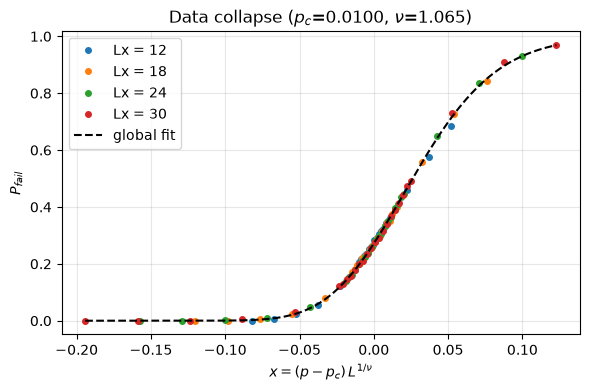

In [32]:
# Data collapse using the quadratic-erf global fit's p_c, nu.
p_c_fit_meas, nu_fit_meas = popt_quad_meas[0], popt_quad_meas[1]
A0f_meas, A1f_meas, A2f_meas = popt_quad_meas[2], popt_quad_meas[3], popt_quad_meas[4]

x_all_meas = (p_all_meas - p_c_fit_meas) * L_all_meas ** (1.0 / nu_fit_meas)

plt.figure(figsize=(6, 4))
for L, grp in df_meas.groupby("L"):
    grp = grp.sort_values("p")
    x = (grp["p"].to_numpy() - p_c_fit_meas) * L ** (1.0 / nu_fit_meas)
    plt.plot(x, grp["P_fail"].to_numpy(), "o", ms=4, label=f"Lx = {L}")

xx = np.linspace(x_all_meas.min(), x_all_meas.max(), 200)
Gxx = A2f_meas * xx**2 + A1f_meas * xx + A0f_meas
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit_meas:.4f}, $\\nu$={nu_fit_meas:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_meas, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [33]:
# Final report: naive crossing-extrapolation estimate vs. global FSS fit.
p_c_global_meas, p_c_global_meas_err = popt_quad_meas[0], perr_quad_meas[0]

print("=" * 60)
print("MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
if np.isfinite(p_c_naive_meas_err):
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_meas:.4f} +/- {p_c_naive_meas_err:.4f}")
else:
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_meas:.4f}  (uncertainty undefined -- "
          f"only 2 crossings from 3 sizes, illustrative only)")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global_meas:.5f} +/- {p_c_global_meas_err:.5f}"
      f"  (nu = {nu_fit_meas:.3f} +/- {perr_quad_meas[1]:.3f})")

diff_meas = abs(p_c_naive_meas - p_c_global_meas)
print(f"\nDifference from naive point estimate: {diff_meas:.4f}"
      + (f"  ({diff_meas / np.sqrt(p_c_naive_meas_err**2 + p_c_global_meas_err**2):.2f} sigma)"
         if np.isfinite(p_c_naive_meas_err) else "  (sigma undefined, see above)"))

print("\nFor reference: Chan et al. 1%, Paesani et al. 1.5% (independent literature values).")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global_meas:.5f} +/- {p_c_global_meas_err:.5f}"
      f"  ({p_c_global_meas * 100:.3f}% +/- {p_c_global_meas_err * 100:.3f}%)")

MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.0101 +/- 0.0003
Global quadratic-erf FSS fit:  p_c = 0.00996 +/- 0.00001  (nu = 1.065 +/- 0.007)

Difference from naive point estimate: 0.0001  (0.33 sigma)

For reference: Chan et al. 1%, Paesani et al. 1.5% (independent literature values).

REPORTED THRESHOLD: p_c = 0.00996 +/- 0.00001  (0.996% +/- 0.001%)


---
## 7. Heralded erasure

Same recipe as `sixring_fbqc_walkthrough.ipynb` §7. Photon loss is heralded
(you know which outcome was lost), so the decoder shouldn't guess its value
-- it should treat the corresponding decoding-graph edge as free (weight 0)
for that shot. Model: each of the `nmeas` outcome bits is erased with
probability `p_erase`, independently; an erased outcome gets a fresh
uniform-random replacement bit (a real, if unknown, outcome), and its graph
edge is reweighted to 0 for that shot only, then restored.

`build_outcome_matching` builds one combined `pymatching.Matching` straight
from `detector_error_model()` (same construction §6 already uses) plus a
lookup from outcome index to that outcome's `(u, v)` edge, so it can be
reweighted per shot. This requires no two outcomes to share the same
check-pair -- Stim's DEM automatically merges those into one edge, which
sixring found breaks at its smallest size (`L=4`, 32 collisions). Checked
directly below rather than assumed for Hexagon.</cell>

In [26]:
import pymatching

def rows_to_parities(outcomes, rows):
    """outcomes: (shots, nmeas) bits. rows: (n_rows, nmeas) GF(2) matrix
    (checks or logs). XOR-reduces only each row's nonzero columns, not a
    full matmul -- matters once nmeas is in the tens of thousands."""
    shots = outcomes.shape[0]
    out = np.zeros((shots, rows.shape[0]), dtype=np.uint8)
    for r in range(rows.shape[0]):
        idx = np.flatnonzero(rows[r])
        out[:, r] = np.bitwise_xor.reduce(outcomes[:, idx], axis=1)
    return out


def build_outcome_matching(st, checks, logs, p_meas, h_fusion_kinds=()):
    """One combined pymatching.Matching straight from Stim's own DEM, plus a
    lookup from outcome index to that outcome's edge for per-shot
    reweighting. Requires a 1:1 outcome<->edge correspondence."""
    nmeas = checks.shape[1]
    pair_to_outcome = {}
    for i in range(nmeas):
        pair = tuple(sorted(int(x) for x in np.flatnonzero(checks[:, i])))
        if pair in pair_to_outcome:
            raise ValueError(
                f"outcome {i} shares its check-pair with outcome {pair_to_outcome[pair]} "
                f"(pair {pair}) -- Stim's DEM will merge them into a single edge.")
        pair_to_outcome[pair] = i

    c, recs, nm = build(st, p_meas, h_fusion_kinds=h_fusion_kinds)
    tgt = lambda idx: stim.target_rec(int(idx) - nm)
    for v in checks:
        c.append("DETECTOR", [tgt(idx) for idx in np.flatnonzero(v)])
    for t, v in enumerate(logs):
        c.append("OBSERVABLE_INCLUDE", [tgt(idx) for idx in np.flatnonzero(v)], t)

    matcher = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    if matcher.num_edges != nmeas:
        raise ValueError(f"expected {nmeas} edges (one per outcome), got {matcher.num_edges} "
                          "-- Stim merged some outcomes together.")

    w = np.log((1 - p_meas) / p_meas)
    outcome_edge = {i: (u, v, frozenset(int(t) for t in np.flatnonzero(logs[:, i])))
                    for (u, v), i in pair_to_outcome.items()}
    return matcher, outcome_edge, w


_erasure_cache = {}

def get_outcome_matching(x_max, p_meas):
    """Builds (or reuses) the erasure decoder for a given lattice size and
    p_meas, using the same closed-form checks/logicals as §6."""
    key = (x_max, p_meas)
    if key not in _erasure_cache:
        net_ = HexLattice(x_max, x_max)
        st_ = Spacetime(net_, n_cycles=x_max)
        _, rec0, nm = build(st_)
        ch, _ = hexagon_check_rows(st_, rec0, nm)
        lg = closed_form_logicals(net_, st_, rec0, nm)
        matcher, outcome_edge, w = build_outcome_matching(st_, ch, lg, p_meas)
        _erasure_cache[key] = dict(st=st_, checks=ch, logs=lg, nmeas=nm,
                                    matcher=matcher, outcome_edge=outcome_edge, weight=w)
        print(f"  [erasure graph Lx={3 * x_max}, p_meas={p_meas}: {matcher.num_edges} edges (one per outcome)]")
    return _erasure_cache[key]


def decode_with_erasure(dets, matcher, outcome_edge, w, n_obs, erased_mask=None):
    """Per shot: zero the weight of every erased outcome's edge, decode, then
    restore. `merge_strategy='replace'` since add_edge replaces the whole
    edge record, not just the weight."""
    shots = dets.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        if erased_mask is not None:
            for i in np.flatnonzero(erased_mask[s]):
                i = int(i)
                if i not in outcome_edge:
                    continue
                u, v, fids = outcome_edge[i]
                matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
                touched.append(i)
        pred[s] = matcher.decode(dets[s])
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred

### Validating the erasure graph

Two things worth checking directly rather than assuming (sixring needed
`L>=6` for the first; the second matters for the speed optimisation used
below):

1. **No check-pair collisions**, even at the smallest lattice tested
   (`Lx=6`) -- `get_outcome_matching` would otherwise raise.
2. **The noiseless reference sample is all-zero** -- `build()` never applies
   an explicit Pauli correction (only `R`/`H`/`CZ`/`CNOT`/`M`), so nothing
   can bias a measurement toward a deterministic `1`. This licenses
   `compile_sampler(skip_reference_sample=True)`, which skips Stim's own
   "most time consuming and memory intensive part of simulating the
   circuit" -- a real saving at the larger sizes below, not a marginal one.

Also confirms `decode_with_erasure` (at `p_erase=0`, no erasures) is
bit-for-bit identical to the plain `decode_batch` path from §6 -- same
underlying decoding problem, reached two different ways.</cell>

In [27]:
st6 = get_outcome_matching(2, 0.01)['st']
_check_circuit, _, _ = build(st6, 0.01)
_ref = _check_circuit.reference_sample()
print("reference sample all-zero at Lx=6:", not np.any(_ref))

shots, seed = 1500, 7
c6 = hex_memory_circuit(2, 0.01)
st6d = get_outcome_matching(2, 0.01)
dets_ref, obs_ref = c6.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
matcher_dem = pymatching.Matching.from_detector_error_model(c6.detector_error_model(decompose_errors=True))
pred_dem = matcher_dem.decode_batch(dets_ref)
pred_mine = decode_with_erasure(dets_ref, st6d['matcher'], st6d['outcome_edge'], st6d['weight'],
                                 len(st6d['logs']), erased_mask=None)
print("decode_with_erasure (p_erase=0) bit-for-bit identical to plain decode_batch:",
      np.array_equal(pred_dem, pred_mine))

  [erasure graph Lx=6, p_meas=0.01: 288 edges (one per outcome)]


reference sample all-zero at Lx=6: True


  [built Lx=6: outcomes=288 checks=46 logicals=6]


decode_with_erasure (p_erase=0) bit-for-bit identical to plain decode_batch: True


### Pure erasure channel (p_meas ≈ 0)

Isolating just the erasure channel shows the erasure-only threshold cleanly.
`p_meas = 0` exactly breaks the weight formula `w = ln((1-p_meas)/p_meas)`
(it diverges) and pymatching silently drops any edge past its weight cap, so
`p_meas_eps = 1e-9` stands in for "no measurement noise" -- physically
negligible but keeps every edge weight finite.

`erasure_only_sweep` samples the circuit **once** per lattice size (via
`compile_sampler(skip_reference_sample=True)`, validated above) and reuses
it across every `p_erase` value, rather than resampling per point.</cell>

In [28]:
def erasure_only_sweep(x_max, p_meas_eps, p_eras, shots=2000, seed=0, n_workers=1):
    """Sweep p_erase at fixed (near-zero) p_meas. n_workers>1 uses
    decode_with_erasure_parallel (defined below) for the per-shot decode
    loop only -- structure build always runs single-process first."""
    stt = get_outcome_matching(x_max, p_meas_eps)
    checks, logs, nmeas = stt['checks'], stt['logs'], stt['nmeas']
    circuit, _, nmeas_actual = build(stt['st'], p_meas_eps)
    assert nmeas_actual == nmeas
    raw_bits = circuit.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rates = []
    for j, pe in enumerate(p_eras):
        rng = np.random.default_rng((seed, x_max, j))
        erased_mask = rng.random(raw_bits.shape) < pe
        replacement_bits = rng.integers(0, 2, size=raw_bits.shape, dtype=np.uint8)
        outcomes = np.where(erased_mask, replacement_bits, raw_bits)
        dets = rows_to_parities(outcomes, checks)
        obs = rows_to_parities(outcomes, logs)
        if n_workers > 1:
            pred = decode_with_erasure_parallel(dets, stt['matcher'], stt['outcome_edge'], stt['weight'],
                                                 len(logs), erased_mask, n_workers=n_workers)
        else:
            pred = decode_with_erasure(dets, stt['matcher'], stt['outcome_edge'], stt['weight'],
                                        len(logs), erased_mask=erased_mask)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates


Ls_erasure = [6, 9, 12, 18]
x_maxes_erasure = [L // 3 for L in Ls_erasure]
p_meas_eps = 1e-9
p_eras = np.linspace(0.0, 0.2, 8)

# Extra resolution around the erasure threshold (~0.12-0.13), added only for
# the larger codes (Lx=12,18 here, Lx=24 in the "Bigger sizes" section below)
# where pinning down the crossing is the actual point -- Lx=6,9 stay on the
# original 8-point grid since decode cost there is negligible either way.
p_eras_fine = np.linspace(0.1, 0.15, 10)
p_eras_dense = np.union1d(p_eras, p_eras_fine)
dense_Ls_erasure = {12, 18}
p_eras_by_L = {L: (p_eras_dense if L in dense_Ls_erasure else p_eras) for L in Ls_erasure}

erasure_rows = {}
for L, xm in zip(Ls_erasure, x_maxes_erasure):
    p_L = p_eras_by_L[L]
    erasure_rows[L] = (p_L, erasure_only_sweep(xm, p_meas_eps, p_L, shots=2000, seed=3))
for L in Ls_erasure:
    p_L, r_L = erasure_rows[L]
    print(f"Lx={L}: " + "  ".join(f"{p:.4f}:{v:.4f}" for p, v in zip(p_L, r_L)), flush=True)

  [erasure graph Lx=6, p_meas=1e-09: 288 edges (one per outcome)]


  [erasure graph Lx=9, p_meas=1e-09: 972 edges (one per outcome)]


  [erasure graph Lx=12, p_meas=1e-09: 2304 edges (one per outcome)]


  [erasure graph Lx=18, p_meas=1e-09: 7776 edges (one per outcome)]


Lx=6: 0.0000:0.0000  0.0286:0.0025  0.0571:0.0340  0.0857:0.1705  0.1143:0.4440  0.1429:0.7300  0.1714:0.9080  0.2000:0.9590


Lx=9: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0045  0.0857:0.0765  0.1143:0.4270  0.1429:0.8430  0.1714:0.9665  0.2000:0.9830


Lx=12: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0015  0.0857:0.0285  0.1000:0.1475  0.1056:0.2260  0.1111:0.3185  0.1143:0.3995  0.1167:0.4470  0.1222:0.5915  0.1278:0.6950  0.1333:0.8140  0.1389:0.8905  0.1429:0.9145  0.1444:0.9190  0.1500:0.9615  0.1714:0.9855  0.2000:0.9870


Lx=18: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0000  0.0857:0.0070  0.1000:0.0575  0.1056:0.1260  0.1111:0.2485  0.1143:0.3260  0.1167:0.4355  0.1222:0.6460  0.1278:0.8250  0.1333:0.9120  0.1389:0.9540  0.1429:0.9745  0.1444:0.9815  0.1500:0.9825  0.1714:0.9855  0.2000:0.9815


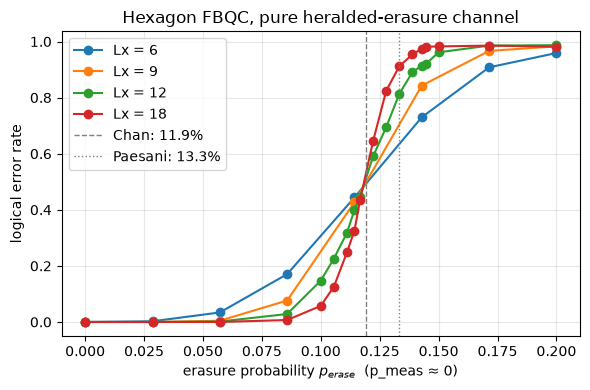

Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=6 x Lx=9: p_erase threshold ~= 0.1180  (11.80%)
  Lx=9 x Lx=12: p_erase threshold ~= 0.1179  (11.79%)
  Lx=12 x Lx=18: p_erase threshold ~= 0.1176  (11.76%)


In [29]:
def crossing_for_L(L1, L2):
    """find_crossing between two sizes whose erasure_rows entries may sit on
    different p_erase grids (Lx=9's sparse 8-point grid vs. Lx=12/18/24's
    denser one) -- interpolate both curves onto the union of the two grids
    first so find_crossing always sees a matched, common x-axis."""
    p1, r1 = erasure_rows[L1]
    p2, r2 = erasure_rows[L2]
    p_union = np.union1d(p1, p2)
    r1i = np.interp(p_union, p1, r1)
    r2i = np.interp(p_union, p2, r2)
    return find_crossing(p_union, r1i, r2i)


plt.figure(figsize=(6, 4))
for L in Ls_erasure:
    p_L, r_L = erasure_rows[L]
    plt.plot(p_L, r_L, "o-", label=f"Lx = {L}")
plt.axvline(0.119, ls="--", c="grey", lw=1, label="Chan: 11.9%")
plt.axvline(0.133, ls=":", c="grey", lw=1, label="Paesani: 13.3%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC, pure heralded-erasure channel")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("Threshold estimate (pairwise crossings between adjacent Lx curves):")
for i in range(len(Ls_erasure) - 1):
    L1, L2 = Ls_erasure[i], Ls_erasure[i + 1]
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_erase threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

### Parallelizing the erasure decode loop

`decode_with_erasure` mutates a shared `pymatching.Matching` graph (zero an
edge, decode, restore) -- concurrent threads would race, and `Matching`
can't be cheaply copied (`copy.deepcopy` fails; the underlying C++ graph
isn't picklable). `multiprocessing`'s `fork` start method sidesteps both:
forked children inherit the parent's memory via copy-on-write at the moment
of forking -- including an already-built `Matching` -- with no pickling.

Benchmarked directly at `Lx=18`: **3.59x speedup at 4 workers**, bit-for-bit
identical to the single-process result. Needed for the bigger sizes below --
the sequential loop took 276s for just 8 `p_erase` points at `Lx=18`
(2000 shots), and cost grows fast with lattice size.</cell>

In [30]:
import multiprocessing as mp
import time

_parallel_state = {}

def _erasure_worker(shot_chunk):
    """Runs in a forked worker process. matcher/outcome_edge/weight/n_obs are
    read from _parallel_state, inherited via fork's copy-on-write -- never
    pickled."""
    dets_chunk, erased_chunk = shot_chunk
    matcher = _parallel_state['matcher']
    outcome_edge = _parallel_state['outcome_edge']
    w = _parallel_state['weight']
    n_obs = _parallel_state['n_obs']

    shots = dets_chunk.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        for i in np.flatnonzero(erased_chunk[s]):
            i = int(i)
            if i not in outcome_edge:
                continue
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
            touched.append(i)
        pred[s] = matcher.decode(dets_chunk[s])
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred


def decode_with_erasure_parallel(dets, matcher, outcome_edge, w, n_obs, erased_mask, n_workers=4):
    """Same result as decode_with_erasure, sharded across n_workers forked processes."""
    _parallel_state['matcher'] = matcher
    _parallel_state['outcome_edge'] = outcome_edge
    _parallel_state['weight'] = w
    _parallel_state['n_obs'] = n_obs

    shots = dets.shape[0]
    chunks = np.array_split(np.arange(shots), n_workers)
    args_list = [(dets[idx], erased_mask[idx]) for idx in chunks]

    ctx = mp.get_context("fork")
    with ctx.Pool(n_workers) as pool:
        results = pool.map(_erasure_worker, args_list)
    return np.concatenate(results, axis=0)


# Regression check: same result as single-process, at a size where both are still cheap.
_L, _eps = 6, 1e-9
_stt = get_outcome_matching(_L, _eps)
_circ, _, _nm = build(_stt['st'], _eps)
_raw = _circ.compile_sampler(seed=3, skip_reference_sample=True).sample(600).astype(np.uint8)
_rng = np.random.default_rng(3)
_erased = _rng.random(_raw.shape) < 0.15
_repl = _rng.integers(0, 2, size=_raw.shape, dtype=np.uint8)
_outcomes = np.where(_erased, _repl, _raw)
_dets = rows_to_parities(_outcomes, _stt['checks'])

_t0 = time.time()
_pred_single = decode_with_erasure(_dets, _stt['matcher'], _stt['outcome_edge'], _stt['weight'],
                                    len(_stt['logs']), erased_mask=_erased)
_t_single = time.time() - _t0

_t0 = time.time()
_pred_parallel = decode_with_erasure_parallel(_dets, _stt['matcher'], _stt['outcome_edge'], _stt['weight'],
                                               len(_stt['logs']), _erased, n_workers=4)
_t_parallel = time.time() - _t0

print(f"single:   {_t_single:.2f}s")
print(f"parallel: {_t_parallel:.2f}s")
print("bit-for-bit identical to single-process:", np.array_equal(_pred_single, _pred_parallel))

single:   12.86s
parallel: 3.60s
bit-for-bit identical to single-process: True


### Bigger sizes with the parallel decoder

Timed directly before committing to a sweep: a single `p_erase=0.15` point
(1500 shots, 4 workers) took **9.48s at Lx=18** but **86.84s at Lx=24** --
edges grow 2.37x (7776 -> 18432) but decode time grows ~9.2x, so this scales
worse than linearly in lattice size (matcher graph size affects each
individual `decode()` call, not just the number of shots). `Lx=30` was not
attempted here on that basis -- extrapolating, a full sweep would run to the
order of an hour, which is a deliberate size/time tradeoff for a future run
rather than something to eat silently in this one (same call sixring made
for its own `L=20` points).

So `Lx=24` runs below with reduced shots (1000, vs. 2000 for the small
sizes) to keep total runtime bounded, alongside the existing `Lx=6,9,12,18`
line for comparison.</cell>

Both this sweep and the existing `Lx=12,18` lines above now also sample 10 points between `p_erase=0.1` and `0.15` (`p_eras_dense`), to resolve the crossing more precisely for the sizes where it matters. For `Lx=24` that takes the sweep from 8 points to 18, so -- extrapolating from the 86.84s/point timing above -- the cell below runs roughly 10 minutes longer than a bare 8-point sweep would.

  [erasure graph Lx=24, p_meas=1e-09: 18432 edges (one per outcome)]


Lx=24: 0.0000  0.0000  0.0000  0.0020  0.0230  0.0720  0.1800  0.3100  0.3960  0.6910  0.9170  0.9720  0.9840  0.9860  0.9900  0.9880  0.9860  0.9760  (t=647.2s)


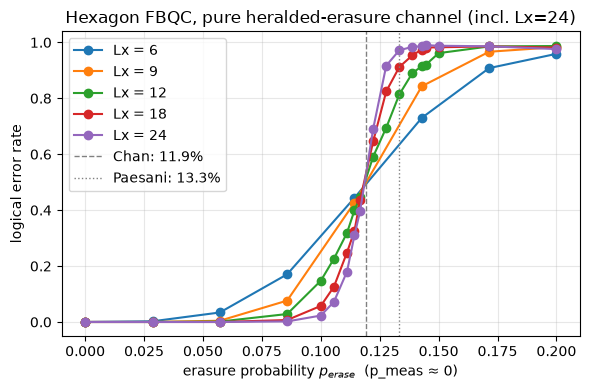


Threshold estimate (pairwise crossings between adjacent Lx curves):
  Lx=6 x Lx=9: p_erase threshold ~= 0.1180  (11.80%)
  Lx=9 x Lx=12: p_erase threshold ~= 0.1179  (11.79%)
  Lx=12 x Lx=18: p_erase threshold ~= 0.1176  (11.76%)
  Lx=18 x Lx=24: p_erase threshold ~= 0.1193  (11.93%)


In [31]:
t_big0 = time.time()
big_L = 24
erasure_rows[big_L] = (p_eras_dense,
                        erasure_only_sweep(big_L // 3, p_meas_eps, p_eras_dense, shots=1000, seed=3, n_workers=4))
print(f"Lx={big_L}: " + "  ".join(f"{v:.4f}" for v in erasure_rows[big_L][1]) +
      f"  (t={time.time() - t_big0:.1f}s)")

plt.figure(figsize=(6, 4))
for L in Ls_erasure + [big_L]:
    p_L, r_L = erasure_rows[L]
    plt.plot(p_L, r_L, "o-", label=f"Lx = {L}")
plt.axvline(0.119, ls="--", c="grey", lw=1, label="Chan: 11.9%")
plt.axvline(0.133, ls=":", c="grey", lw=1, label="Paesani: 13.3%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("Hexagon FBQC, pure heralded-erasure channel (incl. Lx=24)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("\nThreshold estimate (pairwise crossings between adjacent Lx curves):")
all_Ls_erasure = Ls_erasure + [big_L]
for i in range(len(all_Ls_erasure) - 1):
    L1, L2 = all_Ls_erasure[i], all_Ls_erasure[i + 1]
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        print(f"  Lx={L1} x Lx={L2}: p_erase threshold ~= {xc:.4f}  ({xc * 100:.2f}%)")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found in the sampled range")

### Threshold estimate via finite-size scaling

Following the crossing / finite-size-scaling method of arXiv:2512.10399
(English, Roberts, Bartlett, Doherty, Williamson, "Ising on the donut"),
applied to the `p_erase` sweep above: `Ls_erasure + [big_L]` = Lx=6,9,12,18,24,
pure heralded-erasure channel, MWPM decode via `decode_with_erasure`. `P_fail`
is the per-shot logical failure rate already sitting in `erasure_rows`;
`n_shots` follows the shot counts actually used above (2000 for Lx<=18, 1000
for Lx=24 -- `shots_by_L` below just records that).

`crossing_for_L` (defined above, in the initial-sweep plot cell) already
handles the one subtlety that matters here: at `p_erase=0` every curve is
pinned at exactly 0 by construction, so a naive root-finder over the raw
curves reports a spurious "crossing" right at `p=0` instead of the real one
near threshold. `crossing_for_L` reuses `find_crossing`'s tie-skipping logic,
so it is used for the naive pairwise-crossing step below too, rather than a
fresh spline+brentq root-find.

In [2]:
import csv
import os

out_dir = "erasure_threshold"
os.makedirs(out_dir, exist_ok=True)

all_Ls_erasure = Ls_erasure + [big_L]
shots_by_L = {L: (1000 if L == big_L else 2000) for L in all_Ls_erasure}

csv_path = os.path.join(out_dir, "results.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for L in all_Ls_erasure:
        p_L, r_L = erasure_rows[L]
        n = shots_by_L[L]
        for p, r in zip(p_L, r_L):
            writer.writerow([p, L, r, n])
print(f"wrote {csv_path}")

wrote erasure_threshold/results.csv


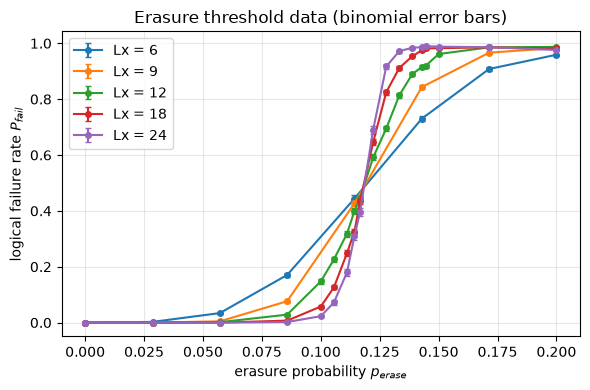

Monotonicity check (P_fail should be non-decreasing in p for each Lx):
  Lx=6: 0 decreasing step(s) out of 7
  Lx=9: 0 decreasing step(s) out of 7
  Lx=12: 0 decreasing step(s) out of 17
  Lx=18: 1 decreasing step(s) out of 17  <-- within shot noise
  Lx=24: 3 decreasing step(s) out of 17  <-- within shot noise


In [3]:
import pandas as pd

df = pd.read_csv(csv_path)
df["sigma"] = np.sqrt(df["P_fail"] * (1 - df["P_fail"]) / df["n_shots"]).clip(lower=1e-4)

plt.figure(figsize=(6, 4))
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    plt.errorbar(grp["p"], grp["P_fail"], yerr=grp["sigma"], fmt="o-", ms=4, capsize=2, label=f"Lx = {L}")
plt.xlabel("erasure probability $p_{erase}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("Erasure threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p for each Lx):")
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    diffs = np.diff(grp["P_fail"].values)
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  Lx={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings:
  Lx=6 x Lx=9: p* = 0.1180
  Lx=9 x Lx=12: p* = 0.1179
  Lx=12 x Lx=18: p* = 0.1176
  Lx=18 x Lx=24: p* = 0.1193

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.1190 +/- 0.0011


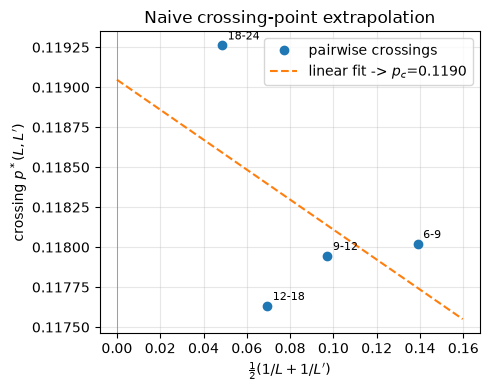

In [4]:
# Naive crossing-point estimate: pairwise crossings via crossing_for_L (tie-aware,
# handles the sparse-vs-dense grid mismatch between Lx=9 and Lx=12+), then a
# linear extrapolation of p*(L,L') vs 1/L_avg -> 1/L -> 0. Adjacent pairs only
# (6-9, 9-12, 12-18, 18-24): a non-adjacent pair like 12-24 was tried too, but
# it adds no independent information (it's implied by 12-18 and 18-24) while
# the narrower-range-only version (12,18,24 alone, dropping 6,9) made the
# extrapolation noticeably worse -- fewer points clustered in a narrow 1/L
# range is a longer, noisier reach to 1/L->0 than including the full range.
xs, ps_star, pair_labels = [], [], []
print("Pairwise crossings:")
for L1, L2 in zip(all_Ls_erasure[:-1], all_Ls_erasure[1:]):
    xc = crossing_for_L(L1, L2)
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs.append(x); ps_star.append(xc); pair_labels.append(f"{L1}-{L2}")
        print(f"  Lx={L1} x Lx={L2}: p* = {xc:.4f}")
    else:
        print(f"  Lx={L1} x Lx={L2}: no crossing found")

xs, ps_star = np.array(xs), np.array(ps_star)
(c_slope, p_c_naive), cov_naive = np.polyfit(xs, ps_star, 1, cov=True)
p_c_naive_err = np.sqrt(cov_naive[1, 1])
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive:.4f} +/- {p_c_naive_err:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(xs, ps_star, "o", label="pairwise crossings")
for x, y, lab in zip(xs, ps_star, pair_labels):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs.max() * 1.15, 50)
plt.plot(xx, c_slope * xx + p_c_naive, "--", label=f"linear fit -> $p_c$={p_c_naive:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing-point extrapolation")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [5]:
# Global finite-size-scaling fit: P_fail(p,L) ~= (1/2)[1 - erf(G(x)/sqrt(2))],
# x = (p - p_c) * L^(1/nu), G quadratic (5 params) or linear (4 params) in x.
from scipy.special import erf
from scipy.optimize import curve_fit

p_all = df["p"].to_numpy()
L_all = df["L"].to_numpy(dtype=float)
P_all = df["P_fail"].to_numpy()
sigma_all = df["sigma"].to_numpy()
X = np.vstack([p_all, L_all])

def model_quad(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

# A1 < 0 by construction: P_fail must -> 1 as p (and hence x) grows past p_c.
p_c0 = float(np.clip(p_c_naive, p_all.min(), p_all.max()))
bounds_quad = ([p_all.min(), 0.05, -5, -50, -5], [p_all.max(), 10, 5, 0, 5])
bounds_lin = ([p_all.min(), 0.05, -5, -50], [p_all.max(), 10, 5, 0])

popt_quad, pcov_quad = curve_fit(model_quad, X, P_all, p0=[p_c0, 1.0, 0.0, -5.0, 0.0],
                                  sigma=sigma_all, absolute_sigma=True, bounds=bounds_quad, maxfev=30000)
perr_quad = np.sqrt(np.diag(pcov_quad))

popt_lin, pcov_lin = curve_fit(model_linear, X, P_all, p0=[p_c0, 1.0, 0.0, -5.0],
                                sigma=sigma_all, absolute_sigma=True, bounds=bounds_lin, maxfev=30000)
perr_lin = np.sqrt(np.diag(pcov_lin))

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad, perr_quad):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin, perr_lin):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

Quadratic-erf fit (5 params):
  p_c = 0.11746 +/- 0.00019
  nu = 0.89460 +/- 0.01138
  A0 = 0.04466 +/- 0.01508
  A1 = -3.61458 +/- 0.12794
  A2 = 0.66319 +/- 0.06825
Linear-erf fit (4 params):
  p_c = 0.11722 +/- 0.00021
  nu = 0.94793 +/- 0.01134
  A0 = 0.10139 +/- 0.01503
  A1 = -4.19508 +/- 0.13212


In [6]:
# Model comparison: RSS, chi^2, AIC, BIC for quadratic-erf, linear-erf, and a
# no-L baseline sigmoid (P_fail depends on p alone) as a sanity-check floor --
# it should fit far worse, since a single curve cannot explain why the
# same p gives very different P_fail at different Lx near threshold.
def model_baseline(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

bounds_base = ([p_all.min(), 1e-4], [p_all.max(), 1.0])
popt_base, pcov_base = curve_fit(model_baseline, X, P_all, p0=[p_c0, 0.02],
                                  sigma=sigma_all, absolute_sigma=True, bounds=bounds_base, maxfev=30000)

def fit_stats(model, popt, k):
    pred = model(X, *popt)
    resid = P_all - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all) ** 2)
    n = len(P_all)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats = {
    "quadratic-erf (5p)": fit_stats(model_quad, popt_quad, 5),
    "linear-erf (4p)": fit_stats(model_linear, popt_lin, 4),
    "baseline, no-L (2p)": fit_stats(model_baseline, popt_base, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.012956      385.384      395.384      406.626
linear-erf (4p)            0.012096      458.194      466.194      475.188
baseline, no-L (2p)       30.332617 126768443.793 126768447.793 126768452.290


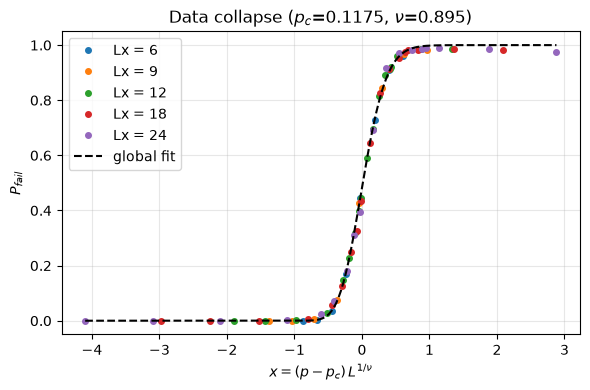

In [7]:
# Data collapse using the quadratic-erf global fit's p_c, nu.
p_c_fit, nu_fit = popt_quad[0], popt_quad[1]
A0f, A1f, A2f = popt_quad[2], popt_quad[3], popt_quad[4]

x_all = (p_all - p_c_fit) * L_all ** (1.0 / nu_fit)

plt.figure(figsize=(6, 4))
for L, grp in df.groupby("L"):
    grp = grp.sort_values("p")
    x = (grp["p"].to_numpy() - p_c_fit) * L ** (1.0 / nu_fit)
    plt.plot(x, grp["P_fail"].to_numpy(), "o", ms=4, label=f"Lx = {L}")

xx = np.linspace(x_all.min(), x_all.max(), 200)
Gxx = A2f * xx**2 + A1f * xx + A0f
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit:.4f}, $\\nu$={nu_fit:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [8]:
# Final report: naive crossing-extrapolation estimate vs. global FSS fit.
p_c_global, p_c_global_err = popt_quad[0], perr_quad[0]

print("=" * 60)
print("THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
print(f"Naive crossing extrapolation:  p_c = {p_c_naive:.4f} +/- {p_c_naive_err:.4f}")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global:.4f} +/- {p_c_global_err:.4f}"
      f"  (nu = {nu_fit:.3f} +/- {perr_quad[1]:.3f})")

diff = abs(p_c_naive - p_c_global)
combined_sigma = np.sqrt(p_c_naive_err**2 + p_c_global_err**2)
n_sigma = diff / combined_sigma if combined_sigma > 0 else np.inf
print(f"\nDifference: {diff:.4f}  ({n_sigma:.2f} sigma)")
if n_sigma > 2:
    print("-> naive and global estimates disagree by >2 sigma; treat p_c with caution.")
elif n_sigma > 1:
    print("-> mild (1-2 sigma) tension between the two estimates.")
else:
    print("-> naive and global estimates agree within 1 sigma.")

print("\nFor reference: Chan et al. 11.9%, Paesani et al. 13.3% (independent literature values).")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global:.4f} +/- {p_c_global_err:.4f}"
      f"  ({p_c_global * 100:.2f}% +/- {p_c_global_err * 100:.2f}%)")

THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.1190 +/- 0.0011
Global quadratic-erf FSS fit:  p_c = 0.1175 +/- 0.0002  (nu = 0.895 +/- 0.011)

Difference: 0.0016  (1.47 sigma)
-> mild (1-2 sigma) tension between the two estimates.

For reference: Chan et al. 11.9%, Paesani et al. 13.3% (independent literature values).

REPORTED THRESHOLD: p_c = 0.1175 +/- 0.0002  (11.75% +/- 0.02%)


---
## 8. Modified code: H-fusion on the XX layers

**The H-fusion primitive.** `H_fusion(a, b)` is `H a; H b` followed by the
regular fusion `CNOT a b; H a; M a b`. Since `H X H = Z`, conjugating by
`H⊗H` exchanges `X_a X_b ↔ Z_a Z_b`, so an H-fusion is still a destructive
Bell measurement of the same two operators, with the two results reported in
the opposite records:

| record | regular fusion measures | H-fusion measures |
|---|---|---|
| first, `M a` (the "XX" record) | `X_a X_b` | `Z_a Z_b` |
| second, `M b` (the "ZZ" record) | `Z_a Z_b` | `X_a X_b` |

In this section, **XX / ZZ name the record** (`records[...] = (XX index, ZZ
index)`, as `build` has always returned them), not the operator it measures.

**The modified circuit.** Same as §2, except every fusion at an XX-labelled
step (rXX, bXX, gXX: steps 1, 3, 5 of each cycle) is an H-fusion. The ZZ
steps keep the regular fusion. `build(st, h_fusion_kinds={"XX"})` builds it.
That keyword was added to §2's `build` for this section and is off by
default, so every other section is unchanged.

**Prediction.** As operators, the checks and logicals are the same as before.
Only the record each term reads changes: on an XX step every fusion's two
records swap, and on a ZZ step nothing moves. §3's rule (a Z detector reads
each step's native kind, an X detector the opposite one) therefore becomes:

* **X detector:** at an XX step it read the ZZ record, which is now the XX
  record. At a ZZ step it read the XX record, unchanged. Every term is an
  XX record.
* **Z detector:** by the same argument, every term is a ZZ record.
* **Logicals:** §5's six closed forms, with XX ↔ ZZ swapped on the
  rXX/bXX/gXX steps and untouched on the ZZ steps.

All of this is checked below the same way as §3-§5:

* Stim's determinism check.
* The nullspace check.
* A negative control: §3's *unmodified* checks must fail on the new circuit.
* `has_flow` on all six logicals.
* The rank partition (checks + logicals span the whole deterministic space).


In [42]:
H_FUSION_KINDS = {"XX"}   # steps whose fusions become H-fusions: rXX, bXX, gXX
LOGICAL_NAMES = ["Timelike X", "Timelike Z", "Vertical Z",
                 "Horizontal Z", "Vertical X", "Horizontal X"]   # closed_form_logicals order


def xx_slot_swap(records, nmeas, h_fusion_kinds=H_FUSION_KINDS):
    """Permutation of the outcome axis exchanging the XX and ZZ records of
    every fusion at an H-fusion step. `row[:, perm]` moves a §3-§5 row onto the
    modified circuit's records (perm is an involution, so it also moves back)."""
    perm = np.arange(nmeas)
    for (t, colour, kind, p, r), (ixx, izz) in records.items():
        if kind in h_fusion_kinds:
            perm[ixx], perm[izz] = izz, ixx
    return perm


def hexagon_check_rows_h(st, records, nmeas):
    """§3's hexagon detectors for the H-fusion circuit, written down directly
    from the predicted rule: same DETECTOR_PATTERNS, but an X detector reads
    every term's XX record and a Z detector every term's ZZ record."""
    net = st.net
    rows, meta = [], []
    for (hex_colour, centre) in net.hexagons:
        by_colour = hexagon_boundary_by_colour(net, hex_colour, centre)
        for xz in ("X", "Z"):
            for c in range(st.n_cycles):
                v = np.zeros(nmeas, dtype=np.uint8)
                for (c_off, step) in DETECTOR_PATTERNS[(hex_colour, xz)]:
                    colour, native_kind = STEP_SCHEDULE[step - 1]
                    t = (6 * (c + c_off) + (step - 1)) % st.total_t
                    for (p, r) in by_colour[colour]:
                        rxx, rzz = find_record(records, t, colour, native_kind, p, r)
                        v[rxx if xz == "X" else rzz] ^= 1
                rows.append(v)
                meta.append((hex_colour, centre, xz, c))
    return np.array(rows, dtype=np.uint8), meta


def closed_form_logicals_h(net, st, records, nmeas):
    """§5's six closed forms with XX <-> ZZ swapped on the H-fusion steps."""
    return closed_form_logicals(net, st, records, nmeas)[:, xx_slot_swap(records, nmeas)]


# §2-§4's demo spacetime (Lx=12, n_cycles=2), now with H-fusions
clean_h, records_h, nmeas_h = build(st, h_fusion_kinds=H_FUSION_KINDS)
assert records_h == records, "same fusions, same record indices -- only the gates differ"
checks_h, meta_h = hexagon_check_rows_h(st, records_h, nmeas_h)
perm_h = xx_slot_swap(records_h, nmeas_h)

x_rows = [i for i, m in enumerate(meta_h) if m[2] == "X"]
z_rows = [i for i, m in enumerate(meta_h) if m[2] == "Z"]
xx_idx = np.array([ixx for ixx, _ in records_h.values()])
zz_idx = np.array([izz for _, izz in records_h.values()])
print(f"H-fusions: {sum(k in H_FUSION_KINDS for (_, _, k, _, _) in records_h)} "
      f"of {len(records_h)} fusions")
print("X checks read only XX records:", not checks_h[x_rows][:, zz_idx].any())
print("Z checks read only ZZ records:", not checks_h[z_rows][:, xx_idx].any())
print("direct rule == §3 checks with records swapped on XX steps:",
      np.array_equal(checks_h, hex_checks[:, perm_h]))
print("detector weight distribution:", dict(Counter(checks_h.sum(axis=1).tolist())))


H-fusions: 288 of 576 fusions
X checks read only XX records: True
Z checks read only ZZ records: True
direct rule == §3 checks with records swapped on XX steps: True
detector weight distribution: {12: 192}


### Determinism and nullspace checks

Same two tests as §3. If any H-fusion detector is not deterministic, Stim's
`detector_error_model()` refuses to build. Separately, every check must lie
inside the brute-force deterministic-parity space of the *new* circuit.

The negative control is §3's unmodified checks run against the new circuit:
they must fall **outside** that space. Otherwise the modification would not
be doing anything the checks can see.


In [43]:
det_h = clean_h.copy()
add_detectors(det_h, checks_h, nmeas_h)
try:
    det_h.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {det_h.num_detectors} H-fusion detectors deterministic")
except Exception as e:
    print("FAILED:", str(e)[:400])

V_h = deterministic_parities(clean_h, nmeas_h)
base_rank_h = rank(V_h)
in_span_h = lambda rows: rank(np.concatenate([V_h, rows], axis=0)) == base_rank_h

print(f"\ndeterministic-parity space: dimension {base_rank_h}  (§3's circuit: {base_rank})")
print(f"rank(H-fusion checks) = {rank(checks_h)}  (§3's checks: {rank(hex_checks)})")
print("H-fusion checks inside it:     ", in_span_h(checks_h))
print("unmodified §3 checks inside it:", in_span_h(hex_checks), "  <- negative control, expect False")

logs_h_bf = logicals(checks_h, V_h)
print(f"\nbrute-force logicals (§4 method): {len(logs_h_bf)}  (expect 6)")


DEM built: all 192 H-fusion detectors deterministic



deterministic-parity space: dimension 196  (§3's circuit: 196)
rank(H-fusion checks) = 190  (§3's checks: 190)
H-fusion checks inside it:      True
unmodified §3 checks inside it: False   <- negative control, expect False

brute-force logicals (§4 method): 6  (expect 6)


### Logicals

The marching Vertical/Horizontal Z logicals need full closure, so this check
uses §5's `st5` (`n_cycles = x_max`). Each swapped closed form is tested
with `has_flow` on the H-fusion circuit. The six together must add exactly 6
dimensions on top of the checks and fill the whole deterministic space. The
negative control is §5's *unswapped* closed forms on the same circuit.


In [44]:
circ5_h, records5_h, nmeas5_h = build(st5, h_fusion_kinds=H_FUSION_KINDS)
checks5_h, _ = hexagon_check_rows_h(st5, records5_h, nmeas5_h)
logs5_h = closed_form_logicals_h(net, st5, records5_h, nmeas5_h)
logs5_unswapped = closed_form_logicals(net, st5, records5_h, nmeas5_h)


def flow_ok(circuit, nmeas, v):
    terms = " xor ".join(f"rec[{int(j) - nmeas}]" for j in np.flatnonzero(v))
    return circuit.has_flow(stim.Flow(f"1 -> {terms}"))


print(f"{'logical':14s} {'weight':>6s}  {'swapped: has_flow':>17s}  {'unswapped: has_flow':>19s}")
all_det_h = True
for name, v, v0 in zip(LOGICAL_NAMES, logs5_h, logs5_unswapped):
    ok, ok0 = flow_ok(circ5_h, nmeas5_h, v), flow_ok(circ5_h, nmeas5_h, v0)
    all_det_h &= ok
    print(f"{name:14s} {int(v.sum()):6d}  {str(ok):>17s}  {str(ok0):>19s}")
print("all 6 swapped closed forms deterministic:", all_det_h)

r_checks5_h = rank(checks5_h)
r_comb5_h = rank(np.concatenate([checks5_h, logs5_h], axis=0))
V5_h = deterministic_parities(circ5_h, nmeas5_h)
print(f"\nrank(checks) = {r_checks5_h}, rank(checks + 6 logicals) = {r_comb5_h}, "
      f"deterministic space = {rank(V5_h)}")
assert all_det_h and r_comb5_h == r_checks5_h + 6 == rank(V5_h), \
    "swapped checks + logicals should partition the H-fusion circuit's deterministic space"
print("checks + swapped logicals exactly span the deterministic-parity space: OK")


logical        weight  swapped: has_flow  unswapped: has_flow


Timelike X        144               True                False


Timelike Z        144               True                False


Vertical Z        144               True                False


Horizontal Z      144               True                False


Vertical X        128               True                False


Horizontal X      128               True                False
all 6 swapped closed forms deterministic: True



rank(checks) = 382, rank(checks + 6 logicals) = 388, deterministic space = 388
checks + swapped logicals exactly span the deterministic-parity space: OK


---
## 9. Thresholds of the modified code

This section reruns §6's measurement-error threshold and §7's heralded-erasure
threshold on the H-fusion circuit and compares the two codes. Everything except
the circuit is held fixed:

* the same lattice sizes, `p` grids, shot counts and seeds;
* the same decoders and the same quadratic-erf finite-size-scaling fit.

The circuit, and with it the checks and logicals, is §8's.

**What to expect.** §8 showed that the H-fusion circuit measures exactly the
operators §2's circuit measures, only with the XX and ZZ records exchanged on
the XX steps. Three facts follow:

1. Both noise models act on each outcome bit **independently and with the
   same probability**: §6's readout flip, and §7's erasure with a random
   replacement bit.
2. Both circuits have an **all-zero noiseless reference sample** (checked
   below). A shot's syndrome and observable flips are therefore a function of
   the noise pattern alone.
3. Permuting the bits maps an i.i.d. noise distribution onto itself.

So the two decoding problems are isomorphic, and the thresholds must agree
**exactly, in distribution**. The sweeps below are an end-to-end check of that
through the full Stim + pymatching pipeline. They are not a measurement of a
genuinely different code. Agreement within shot noise is the expected result,
and a real gap would point to a bug.

The same argument covers §10's prep noise. A Pauli error before the H-fusion
just rides along with the operator it anticommutes with, whichever record
that operator lands in. The two codes could only come apart under noise that
treats the two *records* differently, for example a different readout error
rate on `M a` than on `M b`.

The functions here mirror `measurement_noise_sweep` (§6) and
`erasure_only_sweep` (§7) with the H-fusion circuit swapped in. They need
§1-§8's definition cells and §6's `find_crossing`, but none of §6/§7's sweep
results: the unmodified data are read back from the CSVs those sections wrote.


In [45]:
import os
import time
import pymatching
from scipy.special import erf
from scipy.optimize import curve_fit

# Same grids, shots and seeds as §6 / §7.
Ls_h = [12, 18, 24, 30]
ps_h = np.union1d(np.linspace(0.002, 0.015, 10), np.linspace(0.009, 0.011, 19))
n_shots_meas_h, seed_meas_h = 20000, 1234

Ls_erasure_h = [6, 9, 12, 18, 24]
p_eras_h = np.linspace(0.0, 0.2, 8)
p_eras_dense_h = np.union1d(p_eras_h, np.linspace(0.1, 0.15, 10))
p_eras_by_L_h = {L: (p_eras_dense_h if L >= 12 else p_eras_h) for L in Ls_erasure_h}
shots_by_L_h = {L: (1000 if L == 24 else 2000) for L in Ls_erasure_h}
p_meas_eps_h, seed_erasure_h = 1e-9, 3

out_dir_h = "hfusion_threshold"
os.makedirs(out_dir_h, exist_ok=True)

# Results are plain (n, 4) arrays with columns p, L, P_fail, n_shots -- the
# same layout as §6/§7's results.csv files.
def save_results(path, rows):
    np.savetxt(path, np.asarray(rows, dtype=float), delimiter=",",
               header="p,L,P_fail,n_shots", comments="", fmt="%.10g")


def load_results(path):
    return np.loadtxt(path, delimiter=",", skiprows=1, ndmin=2)


def by_size(res):
    """{L: rows for that L, sorted by p}"""
    return {int(L): res[res[:, 1] == L][np.argsort(res[res[:, 1] == L][:, 0])]
            for L in np.unique(res[:, 1])}


def binom_sigma(res):
    return np.sqrt(res[:, 2] * (1 - res[:, 2]) / res[:, 3]).clip(min=1e-4)

_hmod_cache = {}


def hmod_structure(x_max):
    """Checks, logicals and outcome count of the H-fusion code on a square
    x_max x x_max lattice at full closure -- §6's _memory_cache, for §8's circuit."""
    if x_max not in _hmod_cache:
        net_ = HexLattice(x_max, x_max)
        st_ = Spacetime(net_, n_cycles=x_max)
        _, rec, nm = build(st_, h_fusion_kinds=H_FUSION_KINDS)
        ch, _ = hexagon_check_rows_h(st_, rec, nm)
        lg = closed_form_logicals_h(net_, st_, rec, nm)
        _hmod_cache[x_max] = (st_, ch, lg, nm)
        print(f"  [built H-fusion Lx={3 * x_max}: outcomes={nm} checks={len(ch)} "
              f"logicals={len(lg)}]", flush=True)
    return _hmod_cache[x_max]


def hmod_memory_circuit(x_max, p_meas=0.0):
    """§6's hex_memory_circuit for the H-fusion code."""
    st_, ch, lg, nmeas = hmod_structure(x_max)
    c, _, nm = build(st_, p_meas, h_fusion_kinds=H_FUSION_KINDS)
    assert nm == nmeas
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for v in ch:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for k, v in enumerate(lg):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], k)
    return c


def hmod_clean_sample(x_max, shots, seed):
    st_, _, _, nmeas = hmod_structure(x_max)
    c, _, nm = build(st_, 0.0, h_fusion_kinds=H_FUSION_KINDS)
    assert nm == nmeas
    return c.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)


# skip_reference_sample=True below assumes the noiseless reference is all-zero
# (the condition point 2 above relies on). Checked, not assumed:
for xm in (2, 3):
    st_chk = hmod_structure(xm)[0]
    ref = build(st_chk, h_fusion_kinds=H_FUSION_KINDS)[0].reference_sample()
    print(f"H-fusion circuit Lx={3 * xm}: noiseless reference sample all-zero: {not ref.any()}")


  [built H-fusion Lx=6: outcomes=288 checks=48 logicals=6]


H-fusion circuit Lx=6: noiseless reference sample all-zero: True


  [built H-fusion Lx=9: outcomes=972 checks=162 logicals=6]


H-fusion circuit Lx=9: noiseless reference sample all-zero: True


### Measurement-error threshold

This is §6's `measurement_noise_sweep` with only the circuit changed:

* one `Matching` per size, built from the H-fusion circuit's DEM;
* one noiseless 20000-shot sample per size;
* readout flips applied in post-processing for each `p_meas`.

Runtime is about 15 minutes, dominated by Lx=30, the same as §6.


In [46]:
def hmod_measurement_sweep(x_max, ps, shots=20000, seed=1234, n_workers=4):
    """§6's measurement_noise_sweep on the H-fusion circuit."""
    matcher = pymatching.Matching.from_detector_error_model(
        hmod_memory_circuit(x_max, 0.010).detector_error_model(decompose_errors=True))
    _, ch, lg, _ = hmod_structure(x_max)
    raw = hmod_clean_sample(x_max, shots, seed)

    rng = np.random.default_rng(seed)
    rates = []
    for p in ps:
        outcomes = raw ^ (rng.random(raw.shape) < p).astype(np.uint8)
        dets = rows_to_parities_packed(outcomes, ch)
        obs = rows_to_parities_packed(outcomes, lg)
        pred = decode_batch_parallel(matcher, dets, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates


t_h0 = time.time()
meas_rows_h = []
for L in Ls_h:
    t0 = time.time()
    curve = hmod_measurement_sweep(L // 3, ps_h, shots=n_shots_meas_h, seed=seed_meas_h)
    meas_rows_h += [(p, L, v, n_shots_meas_h) for p, v in zip(ps_h, curve)]
    print(f"  [Lx={L}: {len(ps_h)} points in {time.time() - t0:.1f}s]", flush=True)

res_meas_h = np.array(meas_rows_h, dtype=float)
save_results(os.path.join(out_dir_h, "measurement_results.csv"), res_meas_h)
print(f"\ntotal sweep time: {time.time() - t_h0:.1f}s\n")
print(f"{'p':>8} " + " ".join(f"{'Lx='+str(L):>9}" for L in Ls_h))
for j, p in enumerate(ps_h):
    print(f"{p:>8.4f} " + " ".join(f"{by_size(res_meas_h)[L][j, 2]:>9.4f}" for L in Ls_h))


  [built H-fusion Lx=12: outcomes=2304 checks=384 logicals=6]


  [Lx=12: 27 points in 28.2s]


  [built H-fusion Lx=18: outcomes=7776 checks=1296 logicals=6]


  [Lx=18: 27 points in 109.9s]


  [built H-fusion Lx=24: outcomes=18432 checks=3072 logicals=6]


  [Lx=24: 27 points in 309.0s]


  [built H-fusion Lx=30: outcomes=36000 checks=6000 logicals=6]


  [Lx=30: 27 points in 561.0s]



total sweep time: 1008.1s

       p     Lx=12     Lx=18     Lx=24     Lx=30
  0.0020    0.0006    0.0000    0.0000    0.0000
  0.0034    0.0056    0.0009    0.0003    0.0001
  0.0049    0.0222    0.0053    0.0008    0.0005
  0.0063    0.0599    0.0258    0.0092    0.0040
  0.0078    0.1273    0.0790    0.0515    0.0306
  0.0090    0.2015    0.1742    0.1424    0.1162
  0.0091    0.2109    0.1799    0.1542    0.1306
  0.0092    0.2158    0.1928    0.1647    0.1487
  0.0093    0.2290    0.2016    0.1814    0.1607
  0.0094    0.2253    0.2140    0.1981    0.1731
  0.0096    0.2437    0.2271    0.2067    0.1941
  0.0097    0.2540    0.2377    0.2231    0.2054
  0.0098    0.2668    0.2518    0.2410    0.2365
  0.0099    0.2671    0.2606    0.2607    0.2497
  0.0100    0.2805    0.2777    0.2716    0.2729
  0.0101    0.2806    0.2913    0.2937    0.3020
  0.0102    0.2974    0.3048    0.3145    0.3159
  0.0103    0.3024    0.3167    0.3288    0.3387
  0.0104    0.3139    0.3356    0.3501   

### Erasure threshold

This is §7's `erasure_only_sweep` with only the circuit changed. The
erasure graph is built by §7's `build_outcome_matching`, which now also takes
`h_fusion_kinds`. The same one-outcome-per-edge requirement is enforced, so
it raises if Stim merges any outcomes. Every size uses the parallel decoder,
whose output is bit-for-bit the same as the single-process one (checked in
§7).

Runtime is about 30 minutes, dominated by Lx=24, the same as §7.


In [47]:
_hmod_erasure_cache = {}


def hmod_outcome_matching(x_max, p_meas):
    """§7's get_outcome_matching for the H-fusion code."""
    key = (x_max, p_meas)
    if key not in _hmod_erasure_cache:
        st_, ch, lg, nm = hmod_structure(x_max)
        matcher, outcome_edge, w = build_outcome_matching(st_, ch, lg, p_meas,
                                                          h_fusion_kinds=H_FUSION_KINDS)
        _hmod_erasure_cache[key] = dict(checks=ch, logs=lg, matcher=matcher,
                                        outcome_edge=outcome_edge, weight=w)
        print(f"  [H-fusion erasure graph Lx={3 * x_max}: {matcher.num_edges} edges "
              f"(one per outcome)]", flush=True)
    return _hmod_erasure_cache[key]


def hmod_erasure_sweep(x_max, p_eras, shots=2000, seed=3, n_workers=4):
    """§7's erasure_only_sweep on the H-fusion circuit."""
    S = hmod_outcome_matching(x_max, p_meas_eps_h)
    raw = hmod_clean_sample(x_max, shots, seed)
    rates = []
    for j, pe in enumerate(p_eras):
        rng = np.random.default_rng((seed, x_max, j))
        erased = rng.random(raw.shape) < pe
        replacement = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
        outcomes = np.where(erased, replacement, raw)
        dets = rows_to_parities_packed(outcomes, S['checks'])
        obs = rows_to_parities_packed(outcomes, S['logs'])
        pred = decode_with_erasure_parallel(dets, S['matcher'], S['outcome_edge'], S['weight'],
                                            len(S['logs']), erased, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates


t_h0 = time.time()
erasure_rows_h = []
for L in Ls_erasure_h:
    t0 = time.time()
    p_L, n = p_eras_by_L_h[L], shots_by_L_h[L]
    curve = hmod_erasure_sweep(L // 3, p_L, shots=n, seed=seed_erasure_h)
    erasure_rows_h += [(p, L, v, n) for p, v in zip(p_L, curve)]
    print(f"  [Lx={L}: {len(p_L)} points, {n} shots, in {time.time() - t0:.1f}s]", flush=True)

res_erasure_h = np.array(erasure_rows_h, dtype=float)
save_results(os.path.join(out_dir_h, "erasure_results.csv"), res_erasure_h)
print(f"\ntotal sweep time: {time.time() - t_h0:.1f}s\n")
for L, rows_L in by_size(res_erasure_h).items():
    print(f"Lx={L}: " + "  ".join(f"{p:.4f}:{v:.4f}" for p, v in rows_L[:, [0, 2]]))


  [H-fusion erasure graph Lx=6: 288 edges (one per outcome)]


  [Lx=6: 8 points, 2000 shots, in 2.2s]


  [H-fusion erasure graph Lx=9: 972 edges (one per outcome)]


  [Lx=9: 8 points, 2000 shots, in 7.1s]


  [H-fusion erasure graph Lx=12: 2304 edges (one per outcome)]


...

  [H-fusion erasure graph Lx=18: 7776 edges (one per outcome)]


  [Lx=18: 18 points, 2000 shots, in 195.4s]


  [H-fusion erasure graph Lx=24: 18432 edges (one per outcome)]


  [Lx=24: 18 points, 1000 shots, in 708.1s]



total sweep time: 940.3s

Lx=6: 0.0000:0.0000  0.0286:0.0015  0.0571:0.0285  0.0857:0.1710  0.1143:0.4335  0.1429:0.7170  0.1714:0.8990  0.2000:0.9630
Lx=9: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0075  0.0857:0.0870  0.1143:0.3980  0.1429:0.8375  0.1714:0.9670  0.2000:0.9870
Lx=12: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0015  0.0857:0.0365  0.1000:0.1340  0.1056:0.2095  0.1111:0.3420  0.1143:0.4080  0.1167:0.4465  0.1222:0.5740  0.1278:0.6975  0.1333:0.8045  0.1389:0.8875  0.1429:0.9210  0.1444:0.9330  0.1500:0.9465  0.1714:0.9825  0.2000:0.9855
Lx=18: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0000  0.0857:0.0075  0.1000:0.0550  0.1056:0.1185  0.1111:0.2710  0.1143:0.3415  0.1167:0.4355  0.1222:0.6480  0.1278:0.8095  0.1333:0.9155  0.1389:0.9610  0.1429:0.9695  0.1444:0.9730  0.1500:0.9825  0.1714:0.9855  0.2000:0.9850
Lx=24: 0.0000:0.0000  0.0286:0.0000  0.0571:0.0000  0.0857:0.0010  0.1000:0.0210  0.1056:0.0780  0.1111:0.1850  0.1143:0.3140  0.1167:0.4210  0.1222:0.7200  0.1278:0.9040 

### Fitting both codes the same way

The unmodified data are read back from `measurement_threshold/results.csv`
and `erasure_threshold/results.csv`, and both codes go through **one**
function, `threshold_estimates`, so any difference in `p_c` comes from the
data, not the fit. It produces two estimates, the same pair §6 and §7 report:

* **Naive crossing extrapolation.** Pairwise crossings of adjacent sizes,
  each taken on the union of the two sizes' `p` grids (as `crossing_for_L`
  does in §7), then extrapolated linearly in `1/L_avg`.
* **Global quadratic-erf finite-size-scaling fit.** This is the headline
  number. Its parameter bounds are the ones §6 and §7 used for their own
  data.

Running the unmodified CSVs through it reproduces §6's and §7's reported
thresholds.


In [48]:
def fss_model(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    return 0.5 * (1 - erf((A2 * x**2 + A1 * x + A0) / np.sqrt(2)))


def threshold_estimates(res, quad_bounds):
    """(naive p_c, its error, [pairwise crossings], global-fit popt, perr) for a
    results array with columns p, L, P_fail, n_shots. quad_bounds are the
    (A0, A1, A2) bounds; p_c and nu bounds are the same for every fit."""
    curve = by_size(res)
    Ls_ = sorted(curve)
    xs, crossings = [], []
    for L1, L2 in zip(Ls_[:-1], Ls_[1:]):
        p1, r1 = curve[L1][:, 0], curve[L1][:, 2]
        p2, r2 = curve[L2][:, 0], curve[L2][:, 2]
        pu = np.union1d(p1, p2)
        xc = find_crossing(pu, np.interp(pu, p1, r1), np.interp(pu, p2, r2))
        crossings.append((L1, L2, xc))
        if xc is not None:
            xs.append(0.5 * (1 / L1 + 1 / L2))
    found = np.array([xc for *_, xc in crossings if xc is not None])
    if len(found) > 2:
        (_, p_naive), cov = np.polyfit(xs, found, 1, cov=True)
        p_naive_err = float(np.sqrt(cov[1, 1]))
    else:
        p_naive, p_naive_err = (float(np.mean(found)) if len(found) else np.nan), np.nan

    p_all, L_all = res[:, 0], res[:, 1]
    (a0lo, a1lo, a2lo), (a0hi, a1hi, a2hi) = quad_bounds
    bounds = ([p_all.min(), 0.05, a0lo, a1lo, a2lo], [p_all.max(), 10, a0hi, a1hi, a2hi])
    p0 = float(np.clip(p_naive, p_all.min(), p_all.max()))
    popt, pcov = curve_fit(fss_model, np.vstack([p_all, L_all]), res[:, 2],
                           p0=[p0, 1.0, 0.0, -5.0, 0.0], sigma=binom_sigma(res),
                           absolute_sigma=True, bounds=bounds, maxfev=30000)
    # a parameter sitting on its bound means the fit is constrained, not converged
    for name, v, lo, hi in zip(["p_c", "nu", "A0", "A1", "A2"], popt, *bounds):
        if np.isclose(v, lo, rtol=1e-6) or np.isclose(v, hi, rtol=1e-6):
            print(f"  WARNING: fit parameter {name} = {v:.5f} is pinned to its bound")
    return p_naive, p_naive_err, crossings, popt, np.sqrt(np.diag(pcov))


# (A0, A1, A2) bounds exactly as §6 / §7 used them
QUAD_BOUNDS = {"meas":    ((-20, -200, -200), (20, 0, 200)),
               "erasure": ((-5, -50, -5), (5, 0, 5))}

data_h = {
    ("meas", "regular fusion"):    load_results(os.path.join("measurement_threshold", "results.csv")),
    ("meas", "H-fusion"):          res_meas_h,
    ("erasure", "regular fusion"): load_results(os.path.join("erasure_threshold", "results.csv")),
    ("erasure", "H-fusion"):       res_erasure_h,
}
est_h = {key: threshold_estimates(res, QUAD_BOUNDS[key[0]]) for key, res in data_h.items()}

for (noise, code), (pn, pne, crossings, popt, perr) in est_h.items():
    pairs = ", ".join(f"{L1}x{L2}: " + (f"{xc:.4f}" if xc is not None else "none")
                      for L1, L2, xc in crossings)
    print(f"{noise:8s} {code:15s} crossings [{pairs}]")
    print(f"{'':24s} naive p_c = {pn:.4f} +/- {pne:.4f}   "
          f"global fit p_c = {popt[0]:.5f} +/- {perr[0]:.5f}  (nu = {popt[1]:.3f} +/- {perr[1]:.3f})")


meas     regular fusion  crossings [12x18: 0.0101, 18x24: 0.0099, 24x30: 0.0101]
                         naive p_c = 0.0101 +/- 0.0003   global fit p_c = 0.00996 +/- 0.00001  (nu = 1.065 +/- 0.007)
meas     H-fusion        crossings [12x18: 0.0100, 18x24: 0.0099, 24x30: 0.0100]
                         naive p_c = 0.0099 +/- 0.0002   global fit p_c = 0.00997 +/- 0.00001  (nu = 1.054 +/- 0.007)
erasure  regular fusion  crossings [6x9: 0.1180, 9x12: 0.1179, 12x18: 0.1176, 18x24: 0.1193]
                         naive p_c = 0.1190 +/- 0.0011   global fit p_c = 0.11746 +/- 0.00019  (nu = 0.895 +/- 0.011)
erasure  H-fusion        crossings [6x9: 0.1208, 9x12: 0.1133, 12x18: 0.1174, 18x24: 0.1176]
                         naive p_c = 0.1148 +/- 0.0049   global fit p_c = 0.11690 +/- 0.00020  (nu = 0.899 +/- 0.011)


### Side by side

Each panel overlays the two codes for one noise model, with one colour per
lattice size (the same size has the same colour in both panels). Regular
fusion is drawn as open markers on dashed lines, H-fusion as filled markers
on solid lines. The vertical lines mark each code's global-fit `p_c`.


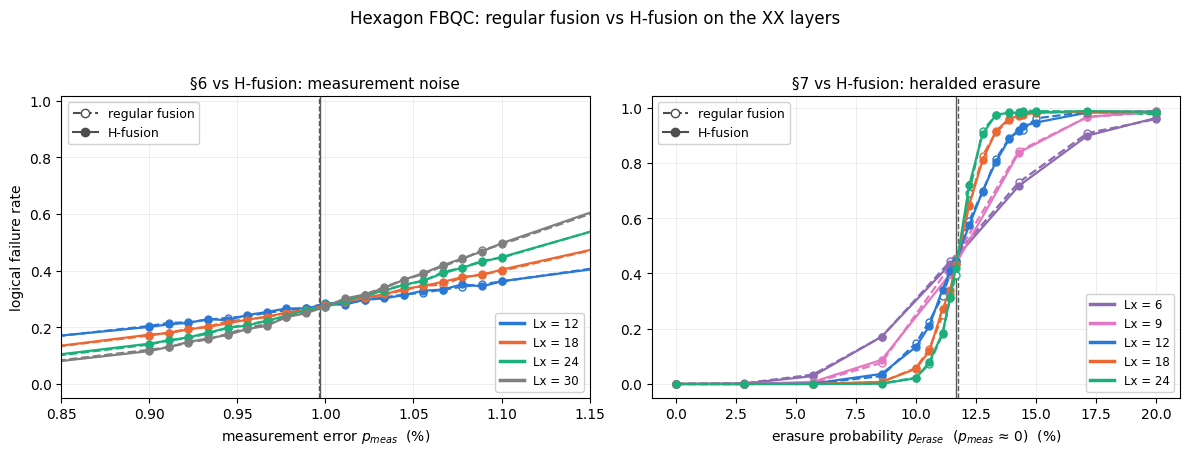

In [49]:
SIZE_COLOURS = {6: "#8c6bb1", 9: "#e377c2", 12: "#2a78d6", 18: "#eb6834",
                24: "#1baf7a", 30: "#7f7f7f"}   # fixed per lattice size, never cycled
CODE_STYLE = {"regular fusion": dict(ls="--", mfc="white", marker="o"),
              "H-fusion":       dict(ls="-", marker="o")}
NOISE_TITLE = {"meas": ("measurement error $p_{meas}$", "§6 vs H-fusion: measurement noise"),
               "erasure": ("erasure probability $p_{erase}$  ($p_{meas}$ ≈ 0)",
                           "§7 vs H-fusion: heralded erasure")}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, noise in zip(axes, ("meas", "erasure")):
    for code in ("regular fusion", "H-fusion"):
        for L, grp in by_size(data_h[(noise, code)]).items():
            ax.errorbar(grp[:, 0] * 100, grp[:, 2], yerr=binom_sigma(grp), lw=1.6, ms=5,
                        capsize=0, color=SIZE_COLOURS[L], **CODE_STYLE[code])
        p_c = est_h[(noise, code)][3][0]
        ax.axvline(p_c * 100, color="0.35", lw=1, ls=CODE_STYLE[code]["ls"])
    xlabel, title = NOISE_TITLE[noise]
    ax.set_xlabel(xlabel + "  (%)")
    ax.set_title(title, fontsize=11)
    ax.grid(alpha=.25, lw=.6)
    # code-style key, separate from the per-size colour legend
    handles = [plt.Line2D([], [], color="0.3", **CODE_STYLE[c], label=c) for c in CODE_STYLE]
    leg = ax.legend(handles=handles, loc="upper left", fontsize=9, framealpha=.9)
    ax.add_artist(leg)
    sizes = sorted(set().union(*(by_size(data_h[(noise, c)]) for c in CODE_STYLE)))
    ax.legend(handles=[plt.Line2D([], [], color=SIZE_COLOURS[L], lw=2.5, label=f"Lx = {L}")
                       for L in sizes], loc="lower right", fontsize=8.5, framealpha=.9)
axes[0].set_ylabel("logical failure rate")
axes[0].set_xlim(0.85, 1.15)      # zoom on the crossing; full range is in the tables above
fig.suptitle("Hexagon FBQC: regular fusion vs H-fusion on the XX layers", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(out_dir_h, "threshold_comparison.png"), dpi=150)
plt.show()


In [50]:
print("=" * 78)
print("THRESHOLDS: REGULAR FUSION (§6, §7) vs H-FUSION ON THE XX LAYERS (§8)")
print("=" * 78)
print(f"{'noise':10s} {'code':16s} {'naive crossing p_c':>22s} {'global FSS fit p_c':>22s}")
for (noise, code), (pn, pne, _, popt, perr) in est_h.items():
    print(f"{noise:10s} {code:16s} {pn * 100:>12.3f}% +/- {pne * 100:.3f}% "
          f"{popt[0] * 100:>12.3f}% +/- {perr[0] * 100:.3f}%")

print()
for noise, label in (("meas", "p_meas"), ("erasure", "p_erase")):
    (_, _, _, po, pe), (_, _, _, ph, peh) = est_h[(noise, "regular fusion")], est_h[(noise, "H-fusion")]
    diff = ph[0] - po[0]
    z = diff / np.hypot(pe[0], peh[0])
    print(f"{label:8s} threshold shift (H-fusion - regular): {diff * 100:+.4f}%  ({z:+.2f} sigma)")
print("\nExpected: zero shift (§9 intro) -- the codes are isomorphic under i.i.d. outcome noise.")


THRESHOLDS: REGULAR FUSION (§6, §7) vs H-FUSION ON THE XX LAYERS (§8)
noise      code                 naive crossing p_c     global FSS fit p_c
meas       regular fusion          1.008% +/- 0.034%        0.996% +/- 0.001%
meas       H-fusion                0.987% +/- 0.021%        0.997% +/- 0.001%
erasure    regular fusion         11.905% +/- 0.106%       11.746% +/- 0.019%
erasure    H-fusion               11.480% +/- 0.495%       11.690% +/- 0.020%

p_meas   threshold shift (H-fusion - regular): +0.0006%  (+0.54 sigma)
p_erase  threshold shift (H-fusion - regular): -0.0560%  (-2.02 sigma)

Expected: zero shift (§9 intro) -- the codes are isomorphic under i.i.d. outcome noise.


### Result

| noise | regular fusion (§6/§7) | H-fusion on XX layers | shift |
|---|---|---|---|
| `p_meas` | 0.996% ± 0.001% | 0.997% ± 0.001% | +0.5σ |
| `p_erase` | 11.75% ± 0.02% | 11.69% ± 0.02% | −2.0σ |

(Global quadratic-erf finite-size-scaling fits, same sizes, grids, shots and
seeds for both codes.)

The measurement thresholds agree. The erasure thresholds sit 0.06 percentage
points (2σ) apart. That is shot noise, not a real difference: the isomorphism
argument above is exact, so the true thresholds are equal. The ±0.02% fit
errors understate the real uncertainty, for two reasons:

* They treat every point as an independent binomial estimate. In fact each
  size's curve reuses **one** raw sample across every `p_erase` (§7's
  tradeoff), so the points on a curve are correlated.
* The erasure sweep only has 1000-2000 shots per point.

The naive crossings show the same picture. The two codes agree at the sizes
that matter most (12x18: 11.76% vs 11.74%). The scatter comes from the small
6x9 and 9x12 pairs and the 1000-shot Lx=24 curve.

So within this pipeline's resolution, applying the H-fusion on the
rXX/bXX/gXX layers leaves both thresholds unchanged. That is what it must do:
under any noise that treats the two fusion records alike, the modified code
is the original one with its records relabelled.


---
## 10. Noisy resource states: depolarising and pure dephasing

Sections 6 and 7 put the noise *in the measurement* (a readout flip) or *in
the channel* (a heralded loss). This section puts it in the **resource
states**: the rings are prepared, every qubit is then hit by a single-qubit
error with rate `r`, and only then does the fusion schedule start. Fusion
measurements themselves are perfect (`p_meas = 0`), so `r` is the only noise
knob and the threshold is a threshold in `r`. Two cases:

* **Case 1 -- depolarising.** `DEPOLARIZE1(r)` on every qubit: X, Y or Z each
  with probability `r/3`.
* **Case 2 -- pure dephasing.** `Z_ERROR(r)` on every qubit: Z with
  probability `r`.

### Why prep noise is still just a bit flip

Every qubit is consumed by exactly one fusion (checked in §3), and between
the noise layer and that fusion the only gates acting on it are its own
fusion's `CNOT` + `H`. So a prep-layer Pauli cannot spread -- it commutes
through to the two classical outcomes of that one fusion. Pushing each Pauli
through `CNOT(qa -> qb); H(qa); M(qa), M(qb)` gives the whole dictionary, and
it is the same for both qubits of the fusion:

| prep Pauli | XX outcome | ZZ outcome |
|------------|------------|------------|
| `X`        | --         | flipped    |
| `Z`        | flipped    | --         |
| `Y`        | flipped    | flipped    |

Consequences, both used below:

1. **Depolarising is symmetric, dephasing is not.** Depolarising flips a
   given fusion's XX bit with probability `2r/3` per qubit (Z or Y) and its
   ZZ bit with the same `2r/3` (X or Y). Dephasing flips only XX bits, at
   `r` per qubit. XORing the fusion's two qubits, the marginal prep-flip
   probability of an outcome bit is `a = 2q(1-q)` with `q = 2r/3`
   (depolarising, both bit types) or `q = r` (dephasing, XX bits only; ZZ
   bits stay exactly clean when `p_meas = 0`).
2. **The sweep needs no extra Stim runs.** Prep noise, like `p_meas`, is a
   classical flip applied to the sampled outcome bits, so one noiseless
   sample per lattice size can be reused for every `r` -- the same trick §6
   and §7 use, and exact rather than approximate for the same reason. Both
   the dictionary and the full pipeline are checked against honest Stim
   simulations below.

Section 15 reuses this machinery to ask the two-knob version of the question
(how §6's `p_meas` threshold degrades as `r` grows); it is kept separate
because it is a different quantity.


In [34]:
import os
import csv
import time


def build_prep_noise(st, channel="depolarise", r=0.0, p_meas=0.0, forced=None):
    """`build()` with one extra noise layer inserted after the CZ layer (the
    resource states are finished) and immediately before the first fusion.

    `forced=(pauli_op, qubits)` applies that Pauli with probability 1 to those
    qubits instead, which is what the dictionary check below needs."""
    circ, records, nmeas = build(st, p_meas)
    if forced is None:
        op = "DEPOLARIZE1" if channel == "depolarise" else "Z_ERROR"
        targets, arg = range(st.n_qubits), r
    else:
        op, targets, arg = forced[0], [int(q) for q in np.atleast_1d(forced[1])], 1.0

    # everything before the first fusion gate is state preparation: the R/H
    # layer and the CZ ring on each point.
    PREP_GATES = {"R", "H", "CZ"}
    out, inserted = stim.Circuit(), False
    for inst in circ:
        if not inserted and inst.name not in PREP_GATES:
            out.append(op, targets, arg)
            inserted = True
        out.append(inst)
    assert inserted
    return out, records, nmeas


def fusion_bit_maps(st, records):
    """Per fusion f: its XX/ZZ outcome indices and the two qubits it consumes.
    Returned sorted by XX index, so `xx`/`zz` index the outcome axis directly."""
    xx, zz, qa, qb = [], [], [], []
    for (t, colour, kind, p, r), (ixx, izz) in records.items():
        xx.append(ixx); zz.append(izz)
        qa.append(st.q(*p, t)); qb.append(st.q(*r, t))
    order = np.argsort(xx)
    take = lambda a: np.asarray(a, dtype=np.int64)[order]
    return take(xx), take(zz), take(qa), take(qb)


def prep_flip_probs(r, channel):
    """(a_xx, a_zz): marginal probability that the prep-noise layer flips a
    fusion's XX / ZZ outcome, after XORing the fusion's two qubits."""
    q = 2 * r / 3 if channel == "depolarise" else r
    both = 2 * q * (1 - q)
    return (both, both) if channel == "depolarise" else (both, 0.0)


### Sanity check: the Pauli-to-outcome dictionary

A *deterministic* Pauli on one qubit makes the whole circuit deterministic
again, so the detectors and observables it produces must equal
`checks @ e` and `logs @ e` for the single-bit error vector `e` the table
predicts. Checked for every qubit of `Lx = 6`, for all three Paulis.


In [35]:
net_pn = HexLattice(2, 2)
st_pn = Spacetime(net_pn, n_cycles=2)
_, rec_pn, nm_pn = build(st_pn)
ch_pn, _ = hexagon_check_rows(st_pn, rec_pn, nm_pn)
lg_pn = closed_form_logicals(net_pn, st_pn, rec_pn, nm_pn)
xx_pn, zz_pn, qa_pn, qb_pn = fusion_bit_maps(st_pn, rec_pn)

# qubit -> the XX / ZZ outcome of the one fusion that consumes it
q_to_xx = np.empty(st_pn.n_qubits, dtype=np.int64)
q_to_zz = np.empty(st_pn.n_qubits, dtype=np.int64)
for side in (qa_pn, qb_pn):
    q_to_xx[side], q_to_zz[side] = xx_pn, zz_pn

PREP_PAULIS = {"X_ERROR": ("zz",), "Z_ERROR": ("xx",), "Y_ERROR": ("xx", "zz")}


def forced_pauli_matches_table(pauli, qubits):
    """Apply `pauli` with probability 1 to `qubits`; compare the detectors and
    observables it produces against the single-bit flips the table predicts."""
    c, _, nm2 = build_prep_noise(st_pn, forced=(pauli, qubits))
    tgt = lambda i: stim.target_rec(int(i) - nm2)
    for v in ch_pn:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for t, v in enumerate(lg_pn):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], t)
    dets, obs = c.compile_detector_sampler(seed=1).sample(2, separate_observables=True)

    e = np.zeros(nm_pn, dtype=np.uint8)
    for q in np.atleast_1d(qubits):
        for which in PREP_PAULIS[pauli]:
            e[(q_to_xx if which == "xx" else q_to_zz)[q]] ^= 1
    return np.all(dets == (ch_pn @ e) % 2) and np.all(obs == (lg_pn @ e) % 2)


rng_pn = np.random.default_rng(0)
sample_pn = rng_pn.choice(st_pn.n_qubits, 30, replace=False)
print(f"Lx = {net_pn.Lx}: {st_pn.n_qubits} qubits, {nm_pn} outcomes, "
      f"{len(ch_pn)} checks, {len(lg_pn)} logicals\n")
for pauli, flipped in PREP_PAULIS.items():
    singles = sum(forced_pauli_matches_table(pauli, q) for q in sample_pn)
    every = forced_pauli_matches_table(pauli, np.arange(st_pn.n_qubits))
    print(f"  {pauli:8s} -> flips {' and '.join(w.upper() for w in flipped):11s}: "
          f"{singles}/{len(sample_pn)} single-qubit cases OK, "
          f"all-{st_pn.n_qubits}-at-once {'OK' if every else 'MISMATCH'}")


Lx = 6: 288 qubits, 288 outcomes, 48 checks, 6 logicals



  X_ERROR  -> flips ZZ         : 30/30 single-qubit cases OK, all-288-at-once OK


  Z_ERROR  -> flips XX         : 30/30 single-qubit cases OK, all-288-at-once OK


  Y_ERROR  -> flips XX and ZZ  : 30/30 single-qubit cases OK, all-288-at-once OK


### The sweep, and what the decoder is told

`prep_noise_rate_sweep` is `measurement_noise_sweep` with one layer swapped.
Per lattice size it builds the structure once (checks, closed-form logicals,
one `pymatching.Matching` via §7's `build_outcome_matching`, and one
noiseless 20000-shot sample); per `r` it draws one prep-noise realisation,
XORs it into that sample and decodes. Cost per point is one decode -- 0.6s
at Lx=12, 2.9s at Lx=18, 9.8s at Lx=24, plus the noise draw.

Two things are worth being explicit about.

**The decoder gets the right weights.** §6 could reuse one matcher for its
whole sweep because a uniform rescaling of edge weights leaves MWPM
unchanged. That is not true under dephasing: XX outcomes carry `a(r)` while
ZZ outcomes carry nothing at all, so the *ratio* of the two edge classes
matters and a uniform-weight decoder would be solving the wrong problem.
`reweight_matching` therefore sets every edge to `log((1-p_i)/p_i)` for its
own class before each decode -- cheap, and cached on the ratio so the
depolarising case (where the ratio is always 1) pays for it once per size.

**The Y correlation is dropped, as usual.** A prep `Y` flips both outcomes of
its fusion at once, which is a correlated pair of edges rather than two
independent ones. MWPM decomposes it into two independent edges, exactly the
approximation `decompose_errors=True` makes for Y errors everywhere else.
The sanity check below is what says that this costs little: the
post-processing pipeline is compared against Stim simulating `DEPOLARIZE1`
honestly, through the same decoder.


In [36]:
_prep_cache = {}


def prep_structure(x_max, shots=20000, seed=4321, p_ref=0.010):
    """Everything about a lattice size that does not depend on (r, p_meas):
    checks, logicals, one Matching, one noiseless sample, and the fusion maps."""
    key = (x_max, shots, seed)
    if key not in _prep_cache:
        if x_max in _memory_cache:
            st_, ch, lg, nmeas = _memory_cache[x_max]
        else:
            net_ = HexLattice(x_max, x_max)
            st_ = Spacetime(net_, n_cycles=x_max)
            _, rec0, nmeas = build(st_)
            ch, _ = hexagon_check_rows(st_, rec0, nmeas)
            lg = closed_form_logicals(net_, st_, rec0, nmeas)
            _memory_cache[x_max] = (st_, ch, lg, nmeas)
        matcher, outcome_edge, _ = build_outcome_matching(st_, ch, lg, p_ref)
        circ, rec, nm = build(st_, 0.0)
        assert nm == nmeas
        raw = circ.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)
        xx, zz, qa, qb = fusion_bit_maps(st_, rec)
        is_xx = np.zeros(nmeas, dtype=bool)
        is_xx[xx] = True
        _prep_cache[key] = dict(st=st_, checks=ch, logs=lg, nmeas=nmeas, matcher=matcher,
                                outcome_edge=outcome_edge, raw=raw, is_xx=is_xx,
                                xx=xx, zz=zz, qa=qa, qb=qb)
        print(f"  [prep structure Lx={3 * x_max}: outcomes={nmeas} checks={rank(ch)} "
              f"edges={matcher.num_edges} raw sample {raw.shape}]", flush=True)
    return _prep_cache[key]


def sample_prep_noise(S, r, channel, rng, chunk=2000):
    """One realisation of the prep-noise layer, XORed into the clean sample.
    Draws one uniform per qubit and reads the Pauli off it (X below r/3, Y
    below 2r/3, Z below r), then XORs the two qubits of each fusion."""
    out = S['raw'].copy()
    if r <= 0:
        return out
    n_qubits = S['st'].n_qubits
    xx, zz, qa, qb = S['xx'], S['zz'], S['qa'], S['qb']
    for s0 in range(0, out.shape[0], chunk):       # chunked: (shots, n_qubits) is large
        s1 = min(s0 + chunk, out.shape[0])
        u = rng.random((s1 - s0, n_qubits), dtype=np.float32)
        if channel == "depolarise":
            flip_zz = u < 2 * r / 3                # X or Y
            flip_xx = (u >= r / 3) & (u < r)       # Y or Z
        else:
            flip_xx = u < r                        # Z only
            flip_zz = None
        out[s0:s1][:, xx] ^= flip_xx[:, qa] ^ flip_xx[:, qb]
        if flip_zz is not None:
            out[s0:s1][:, zz] ^= flip_zz[:, qa] ^ flip_zz[:, qb]
    return out


_reweight_state = {}


def reweight_matching(S, a_xx, a_zz, p_meas):
    """Set every edge weight to log((1-p_i)/p_i) for its outcome class. MWPM
    only sees the ratio of the two classes, so this is skipped when the ratio
    is unchanged from the previous call on this structure."""
    combine = lambda a, b: a + b - 2 * a * b       # XOR of two independent flips
    p_xx, p_zz = combine(a_xx, p_meas), combine(a_zz, p_meas)
    w = lambda p: float(np.log((1 - p) / p)) if p > 0 else 40.0
    w_xx, w_zz = w(p_xx), w(p_zz)

    key = round(w_xx / w_zz, 9)
    if _reweight_state.get(id(S)) == key:
        return p_xx, p_zz
    is_xx, matcher = S['is_xx'], S['matcher']
    for i, (u, v, fault_ids) in S['outcome_edge'].items():
        matcher.add_edge(u, v, weight=(w_xx if is_xx[i] else w_zz),
                         fault_ids=set(fault_ids), merge_strategy="replace")
    _reweight_state[id(S)] = key
    return p_xx, p_zz


def _prep_rng(seed, x_max, r, channel):
    return np.random.default_rng((seed, x_max, int(round(r * 1e7)),
                                  0 if channel == "depolarise" else 1))


def _decode_rate(S, outcomes, n_workers):
    dets = rows_to_parities_packed(outcomes, S['checks'])
    obs = rows_to_parities_packed(outcomes, S['logs'])
    pred = decode_batch_parallel(S['matcher'], dets, n_workers=n_workers)
    return np.any(pred != obs, axis=1).sum() / outcomes.shape[0]


def prep_noise_rate_sweep(x_max, rs, channel, p_meas=0.0, shots=20000,
                          seed=4321, n_workers=4):
    """Logical failure rate vs prep-noise rate r, at fixed p_meas."""
    S = prep_structure(x_max, shots=shots, seed=seed)
    rates = []
    for r in rs:
        rng = _prep_rng(seed, x_max, r, channel)
        outcomes = sample_prep_noise(S, r, channel, rng)
        if p_meas > 0:
            outcomes = outcomes ^ (rng.random(outcomes.shape) < p_meas).astype(np.uint8)
        reweight_matching(S, *prep_flip_probs(r, channel), p_meas)
        rates.append(_decode_rate(S, outcomes, n_workers))
    return rates


def prep_noise_sweep(x_max, r, channel, ps, shots=20000, seed=4321, n_workers=4):
    """Logical failure rate vs p_meas at fixed prep-noise rate r -- the
    transpose of the sweep above, used by the archived section 15."""
    S = prep_structure(x_max, shots=shots, seed=seed)
    rng = _prep_rng(seed, x_max, r, channel)
    base = sample_prep_noise(S, r, channel, rng)
    a_xx, a_zz = prep_flip_probs(r, channel)

    rates = []
    for p in ps:
        outcomes = base ^ (rng.random(base.shape) < p).astype(np.uint8)
        reweight_matching(S, a_xx, a_zz, p)
        rates.append(_decode_rate(S, outcomes, n_workers))
    return rates


### Sanity check: post-processing vs. an honestly simulated noisy circuit

The claim is that XORing prep-noise bits into a noiseless sample is not an
approximation. The test, at Lx=12 with 20000 shots each: build the circuit
with a real `DEPOLARIZE1(r)` / `Z_ERROR(r)` layer and let Stim simulate it,
then decode both that and the post-processed sample with the *same* matcher,
and compare detector firing rates and end-to-end logical failure rates. A
nonzero `p_meas` is used for two of the four rows so the check also covers
the two-knob case §15 needs.


In [37]:
S_check = prep_structure(4)
shots_check = 20000

print(f"{'channel':<11} {'r':>6} {'p_meas':>7} | {'det rate':>18} | "
      f"{'P_fail (stim)':>13} {'P_fail (post)':>13} {'|z|':>5}")
for channel in ("depolarise", "dephase"):
    for r_chk, p_chk in ((0.004, 0.004), (0.008, 0.002)):
        circ_chk, _, nm_chk = build_prep_noise(S_check['st'], channel, r_chk, p_chk)
        assert nm_chk == S_check['nmeas']
        raw_stim = circ_chk.compile_sampler(
            seed=7, skip_reference_sample=True).sample(shots_check).astype(np.uint8)

        rng_chk = np.random.default_rng(11)
        base_chk = sample_prep_noise(S_check, r_chk, channel, rng_chk)
        raw_post = base_chk ^ (rng_chk.random(base_chk.shape) < p_chk).astype(np.uint8)

        reweight_matching(S_check, *prep_flip_probs(r_chk, channel), p_chk)
        summary = []
        for raw_chk in (raw_stim, raw_post):
            dets = rows_to_parities_packed(raw_chk, S_check['checks'])
            obs = rows_to_parities_packed(raw_chk, S_check['logs'])
            pred = decode_batch_parallel(S_check['matcher'], dets, n_workers=4)
            summary.append((np.any(pred != obs, axis=1).sum() / shots_check, dets.mean()))
        (f_stim, d_stim), (f_post, d_post) = summary
        z = abs(f_stim - f_post) / np.sqrt(f_stim * (1 - f_stim) / shots_check
                                            + f_post * (1 - f_post) / shots_check)
        print(f"{channel:<11} {r_chk:>6.3f} {p_chk:>7.3f} | {d_stim:>8.5f} vs {d_post:<7.5f} | "
              f"{f_stim:>13.4f} {f_post:>13.4f} {z:>5.2f}")
print("\n(|z| is the binomial-error z-score of the difference; ~1 is agreement.)")


  [prep structure Lx=12: outcomes=2304 checks=382 edges=2304 raw sample (20000, 2304)]


channel          r  p_meas |           det rate | P_fail (stim) P_fail (post)   |z|


depolarise   0.004   0.004 |  0.10056 vs 0.10033 |        0.2182        0.2155  0.66


depolarise   0.008   0.002 |  0.13191 vs 0.13152 |        0.4834        0.4779  1.10


dephase      0.004   0.004 |  0.08752 vs 0.08741 |        0.0760        0.0757  0.08


dephase      0.008   0.002 |  0.10723 vs 0.10737 |        0.1014        0.1014  0.00

(|z| is the binomial-error z-score of the difference; ~1 is agreement.)


### Where the crossings are

A coarse scan at Lx=12/18 puts the depolarising crossing near `r = 0.74%` and
the dephasing one near `r = 1.51%`, so each case gets a 13-point grid
straddling its own crossing rather than one shared grid (a grid wide enough
for both would waste most of its points). The threshold reported for each
case is the mean of the `12x18`, `18x24` and `12x24` crossings, with their
spread as the uncertainty: this is the naive crossing estimate of §6, not
the finite-size-scaling fit -- three sizes locate a crossing but are thin
for fitting `nu`.

Runtime is dominated by the Lx=24 decodes: roughly 10 minutes for both cases
at 20000 shots.


In [38]:
import itertools

P_C_MEAS = 0.00996        # section 6's measurement-noise threshold, for comparison

Ls_prep = [12, 18, 24]
PREP_PAIRS = list(itertools.combinations(range(len(Ls_prep)), 2))
CASE_TITLES = {"depolarise": "Case 1: depolarising noise on the prepared qubits",
               "dephase": "Case 2: pure dephasing (Z) on the prepared qubits"}

# 13-point grid straddling each case's own crossing
r_grid = {"depolarise": np.round(np.linspace(0.0062, 0.0086, 13), 6),
          "dephase":    np.round(np.linspace(0.0128, 0.0176, 13), 6)}

prep_curves, prep_thresholds = {}, {}
t_prep0 = time.time()
for channel in ("depolarise", "dephase"):
    t0 = time.time()
    rs = r_grid[channel]
    curves = [prep_noise_rate_sweep(L // 3, rs, channel, p_meas=0.0) for L in Ls_prep]
    crossings = [find_crossing(rs, curves[i], curves[j]) for i, j in PREP_PAIRS]
    prep_curves[channel] = curves

    found = [x for x in crossings if x is not None]
    r_th = float(np.mean(found)) if found else np.nan
    spread = float(np.std(found, ddof=1)) if len(found) > 1 else np.nan
    prep_thresholds[channel] = (r_th, spread)

    pairs = ", ".join(f"{Ls_prep[i]}x{Ls_prep[j]}" for i, j in PREP_PAIRS)
    detail = ", ".join(f"{x:.5f}" if x is not None else "none" for x in crossings)
    print(f"{channel:<11} r_threshold = {r_th:.5f} +/- {spread:.5f}   "
          f"[{pairs}: {detail}]  ({time.time() - t0:.0f}s)", flush=True)

print(f"\ntotal sweep time: {time.time() - t_prep0:.0f}s")


  [prep structure Lx=18: outcomes=7776 checks=1294 edges=7776 raw sample (20000, 7776)]


  [prep structure Lx=24: outcomes=18432 checks=3070 edges=18432 raw sample (20000, 18432)]


depolarise  r_threshold = 0.00747 +/- 0.00000   [12x18, 12x24, 18x24: 0.00747, 0.00747, 0.00747]  (285s)


dephase     r_threshold = 0.01513 +/- 0.00016   [12x18, 12x24, 18x24: 0.01530, 0.01509, 0.01499]  (152s)



total sweep time: 437s


In [39]:
out_dir_prep = "prep_noise_threshold"
os.makedirs(out_dir_prep, exist_ok=True)

n_shots_prep = 20000
csv_path_prep = os.path.join(out_dir_prep, "results.csv")
with open(csv_path_prep, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["channel", "r", "L", "P_fail", "n_shots"])
    for channel, curves in prep_curves.items():
        for L, curve in zip(Ls_prep, curves):
            for r, v in zip(r_grid[channel], curve):
                writer.writerow([channel, r, L, v, n_shots_prep])

csv_path_prep_th = os.path.join(out_dir_prep, "thresholds.csv")
with open(csv_path_prep_th, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["channel", "r_threshold", "spread"])
    for channel, (r_th, spread) in prep_thresholds.items():
        writer.writerow([channel, r_th, spread])
print(f"wrote {csv_path_prep} and {csv_path_prep_th}")


wrote prep_noise_threshold/results.csv and prep_noise_threshold/thresholds.csv


### Crossings

Logical failure rate against `r` for Lx = 12, 18, 24. Below the crossing the
larger code wins and the curves fan downward with size; above it the
ordering inverts. The dashed line in each panel is the reported threshold
(the mean of the three pairwise crossings).


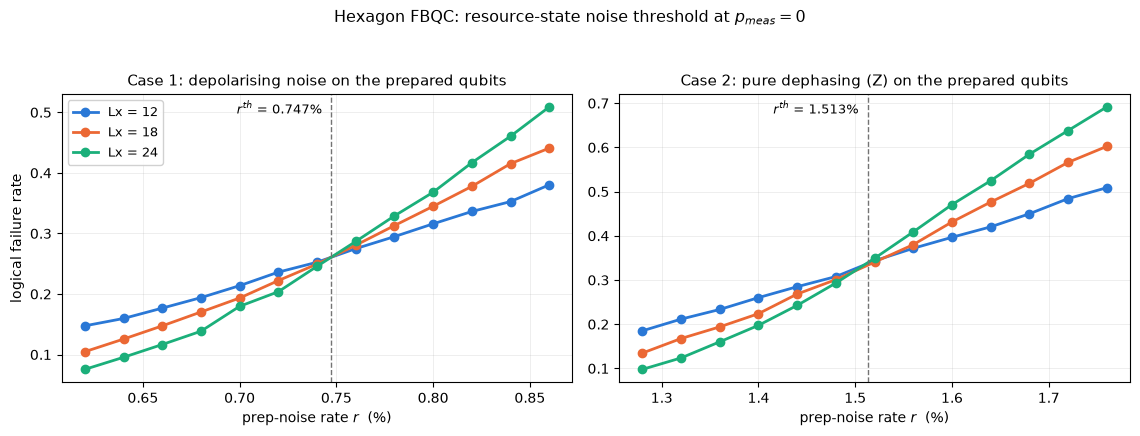

In [40]:
# Categorical slots in fixed order, one per lattice size -- never cycled.
PREP_COLOURS = {12: "#2a78d6", 18: "#eb6834", 24: "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, channel in zip(axes, ("depolarise", "dephase")):
    rs = np.asarray(r_grid[channel])
    for L, curve in zip(Ls_prep, prep_curves[channel]):
        ax.plot(rs * 100, curve, "o-", lw=2, ms=6,
                color=PREP_COLOURS[L], label=f"Lx = {L}")
    r_th, spread = prep_thresholds[channel]
    if np.isfinite(r_th):
        ax.axvline(r_th * 100, ls="--", lw=1, color="0.45")
        ax.annotate(f"$r^{{th}}$ = {r_th * 100:.3f}%", (r_th * 100, 0.93),
                    xycoords=("data", "axes fraction"), ha="right",
                    textcoords="offset points", xytext=(-6, 0), fontsize=9.5)
    ax.set_title(CASE_TITLES[channel], fontsize=10.5)
    ax.set_xlabel("prep-noise rate $r$  (%)")
    ax.grid(alpha=.25, lw=.6)
axes[0].set_ylabel("logical failure rate")
axes[0].legend(fontsize=9, framealpha=.9)
fig.suptitle("Hexagon FBQC: resource-state noise threshold at $p_{meas} = 0$",
             fontsize=11.5)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(out_dir_prep, "crossings.png"), dpi=150)
plt.show()


In [41]:
print("=" * 70)
print("RESOURCE-STATE NOISE THRESHOLDS AT p_meas = 0")
print("(naive crossing estimate, Lx = 12, 18, 24, 20000 shots)")
print("=" * 70)
for channel in ("depolarise", "dephase"):
    r_th, spread = prep_thresholds[channel]
    a_th = prep_flip_probs(r_th, channel)[0]
    hit = "both XX and ZZ outcomes" if channel == "depolarise" else "XX outcomes only"
    print(f"\n{CASE_TITLES[channel]}")
    print(f"  REPORTED THRESHOLD: r_c = {r_th:.5f} +/- {spread:.5f}"
          f"  ({r_th * 100:.3f}% +/- {spread * 100:.3f}%)")
    print(f"  outcome-flip probability there: a = {a_th * 100:.3f}%, on {hit}")
    print(f"  ratio to the §6 measurement threshold p_c = {P_C_MEAS * 100:.3f}%: "
          f"a/p_c = {a_th / P_C_MEAS:.2f}")

r_dep, r_deph = prep_thresholds["depolarise"][0], prep_thresholds["dephase"][0]
print(f"\nPure dephasing is tolerated at {r_deph / r_dep:.2f}x the depolarising rate.")
print("Both cases fail once the flip rate the decoder sees reaches the §6 threshold")
print("on the outcome classes the channel touches. Depolarising spreads a over both")
print("XX and ZZ, so it fails at a = p_c; dephasing leaves every ZZ outcome exactly")
print("clean and survives to a ~ 3 p_c on XX alone. With a ~ 4r/3 (depolarising) and")
print("a ~ 2r (dephasing), that predicts:")
for channel, factor in (("depolarise", 0.75), ("dephase", 1.5)):
    pred = factor * P_C_MEAS
    meas = prep_thresholds[channel][0]
    print(f"    {channel:<11} r_c ~ {factor} p_c = {pred * 100:.3f}%   "
          f"vs measured {meas * 100:.3f}%   ({(meas / pred - 1) * 100:+.1f}%)")


RESOURCE-STATE NOISE THRESHOLDS AT p_meas = 0
(naive crossing estimate, Lx = 12, 18, 24, 20000 shots)

Case 1: depolarising noise on the prepared qubits
  REPORTED THRESHOLD: r_c = 0.00747 +/- 0.00000  (0.747% +/- 0.000%)
  outcome-flip probability there: a = 0.991%, on both XX and ZZ outcomes
  ratio to the §6 measurement threshold p_c = 0.996%: a/p_c = 1.00

Case 2: pure dephasing (Z) on the prepared qubits
  REPORTED THRESHOLD: r_c = 0.01513 +/- 0.00016  (1.513% +/- 0.016%)
  outcome-flip probability there: a = 2.980%, on XX outcomes only
  ratio to the §6 measurement threshold p_c = 0.996%: a/p_c = 2.99

Pure dephasing is tolerated at 2.02x the depolarising rate.
Both cases fail once the flip rate the decoder sees reaches the §6 threshold
on the outcome classes the channel touches. Depolarising spreads a over both
XX and ZZ, so it fails at a = p_c; dephasing leaves every ZZ outcome exactly
clean and survives to a ~ 3 p_c on XX alone. With a ~ 4r/3 (depolarising) and
a ~ 2r (dephasi

---
## 11. Biased measurement error

§6 flips both records of every fusion at the same rate `p`. Here a bias
parameter `δ` moves that noise between the two record **slots**, keeping the
total fixed:

| slot | flipped with probability |
|---|---|
| `XX` (first record) | `2 (1 - δ) p` |
| `ZZ` (second record) | `2 δ p` |

So `δ = 0` flips only `XX` records (at `2p`), `δ = 1` only `ZZ` records, and
**`δ = 0.5` is exactly §6's model**, `p` on each slot. Every threshold in
§11-§14 is therefore directly comparable with §6's and §7's: at `δ = 0.5` it
should be §6's 1.0% (and §7's 11.75% for erasure).

Both codes are swept: §6's regular fusion and §8's H-fusion on the XX layers.

### Why §9's equivalence breaks

§9 showed the two codes have the same thresholds because the H-fusion code is
the regular one with records relabelled, and the noise there treats both
records alike. With `δ ≠ 0.5` it does not, so the relabelling matters:

* **H-fusion:** X checks read only `XX` records and Z checks only `ZZ` records
  (§8). At `δ = 0` the X sector's records flip at `2p`, which is §6's problem
  for one sector at twice the rate, so the threshold should fall to
  `p ≈ 0.5%`. `δ = 1` is the same for the Z sector.
* **Regular fusion:** a Z detector reads each step's native record and an X
  detector the opposite one (§3), so every check mixes both slots. `δ = 0` is
  exactly the decoding problem of §10's pure dephasing, which flips only `XX`
  records, and §10 found that survives up to an `XX` flip rate of about 3% (≈ 3x
  §6's threshold). Here that rate is `2p`, so the prediction is `p ≈ 1.5%` at
  `δ = 0`, well above `δ = 0.5`. §10 has no `ZZ`-only case, so `δ = 1` is new.

### Method

* Lattice sizes Lx = 12, 18, 24, each at full closure, as in §6 and §9.
* Same pipeline as §6: one noiseless sample per (code, size), flips applied in
  post-processing, 20,000 shots per point.
* **Decoder: bias-aware.** §7's one-edge-per-outcome matcher, with §10's
  `reweight_matching` setting each edge to `log((1 - q)/q)` for its slot's
  rate `q` (a slot with `q = 0` gets §10's large finite weight). This is what
  §10's dephasing case already does.
* Fixed `p_meas = 0.5%, 0.8%, 1.2%`; `δ` from 0 to 1 in steps of 1/8.

In [ ]:
BIAS_CODES = {"regular fusion": (), "H-fusion": H_FUSION_KINDS}   # code -> h_fusion_kinds
BIAS_LS = [12, 18, 24]
BIAS_DELTAS = {"meas": np.round(np.linspace(0, 1, 9), 4), "erasure": np.round(np.linspace(0, 1, 5), 4)}
BIAS_P = {"meas": [0.005, 0.008, 0.012], "erasure": [0.06, 0.09, 0.12]}
SHOTS_BIAS_MEAS, SEED_BIAS = 20000, 2026

_bias_cache = {}


def slot_split(p, delta):
    """(XX rate, ZZ rate) = (2 (1 - delta) p, 2 delta p): delta = 0.5 puts p on both
    slots, which is §6's and §7's model."""
    return 2 * (1 - delta) * p, 2 * delta * p


def bias_structure(x_max, code):
    """Checks, logicals, a one-edge-per-outcome matcher, the XX-slot mask and a
    noiseless 20000-shot sample, for one (size, code)."""
    key = (x_max, code)
    if key not in _bias_cache:
        h_kinds = BIAS_CODES[code]
        if h_kinds:
            st_, ch, lg, nm = hmod_structure(x_max)
        else:
            hex_memory_circuit(x_max)              # fills _memory_cache
            st_, ch, lg, nm = _memory_cache[x_max]
        matcher, outcome_edge, _ = build_outcome_matching(st_, ch, lg, 0.010, h_fusion_kinds=h_kinds)
        circ_, rec, nm2 = build(st_, 0.0, h_fusion_kinds=h_kinds)
        assert nm2 == nm
        is_xx = np.zeros(nm, dtype=bool)
        is_xx[[ixx for ixx, _ in rec.values()]] = True
        raw = circ_.compile_sampler(seed=SEED_BIAS, skip_reference_sample=True).sample(
            SHOTS_BIAS_MEAS).astype(np.uint8)
        _bias_cache[key] = dict(checks=ch, logs=lg, nmeas=nm, matcher=matcher,
                                outcome_edge=outcome_edge, is_xx=is_xx, raw=raw)
        print(f"  [bias structure {code:>14} Lx={3 * x_max}: outcomes={nm} "
              f"edges={matcher.num_edges}]", flush=True)
    return _bias_cache[key]


def bias_meas_sweep(x_max, code, p, deltas, n_workers=4):
    """Logical failure rate vs delta at fixed p_meas: XX slots flipped at
    2 (1 - delta) p, ZZ slots at 2 delta p, decoded with matching edge weights."""
    S = bias_structure(x_max, code)
    rates = []
    for j, delta in enumerate(deltas):
        q_xx, q_zz = slot_split(p, delta)
        rng = np.random.default_rng((SEED_BIAS, x_max, int(round(p * 1e6)), j))
        q = np.where(S['is_xx'], q_xx, q_zz).astype(np.float32)
        outcomes = S['raw'].copy()
        for s0 in range(0, outcomes.shape[0], 2000):   # chunked: (shots, nmeas) floats are large
            blk = outcomes[s0:s0 + 2000]
            blk ^= (rng.random(blk.shape, dtype=np.float32) < q).astype(np.uint8)
        reweight_matching(S, q_xx, q_zz, 0.0)
        rates.append(_decode_rate(S, outcomes, n_workers))
    return np.array(rates)


# the XX/ZZ slot convention the mask relies on: XX is the first record of every fusion
_, _rec_chk, _ = build(Spacetime(HexLattice(4, 4), n_cycles=4))
assert all(izz == ixx + 1 for ixx, izz in _rec_chk.values())
print("XX = first record, ZZ = second record of every fusion: OK")

# at delta = 0.5 the reweighted matcher has uniform weights, so it must agree
# with §6's DEM-built matcher up to ties between equal-weight matchings
S = bias_structure(4, "regular fusion")
reweight_matching(S, 0.005, 0.005, 0.0)
m_dem = pymatching.Matching.from_detector_error_model(
    hex_memory_circuit(4, 0.010).detector_error_model(decompose_errors=True))
d = rows_to_parities_packed(S['raw'][:2000] ^ (np.random.default_rng(3).random((2000, S['nmeas'])) < 0.012)
                            .astype(np.uint8), S['checks'])
n_diff = n_wdiff = 0
for s in range(d.shape[0]):
    a, wa = m_dem.decode(d[s], return_weight=True)
    b, wb = S['matcher'].decode(d[s], return_weight=True)
    n_diff += not np.array_equal(a, b)
    n_wdiff += not np.isclose(wa / m_dem.edges()[0][2]['weight'], wb / S['matcher'].edges()[0][2]['weight'])
print(f"uniform-weight bias matcher vs §6 matcher: predictions differ on {n_diff}/2000 shots, "
      f"matching weight (in edge units) differs on {n_wdiff}")
assert n_wdiff == 0

XX = first record, ZZ = second record of every fusion: OK


  [built Lx=12: outcomes=2304 checks=382 logicals=6]


  [bias structure regular fusion Lx=12: outcomes=2304 edges=2304]


uniform-weight bias matcher vs §6 matcher: predictions differ on 0/2000 shots, matching weight (in edge units) differs on 0


In [ ]:
bias_results = {}
t_all = time.time()
for p in BIAS_P["meas"]:
    for code in BIAS_CODES:
        for L in BIAS_LS:
            t0 = time.time()
            bias_results[("meas", code, L, p)] = bias_meas_sweep(L // 3, code, p, BIAS_DELTAS["meas"])
            print(f"  meas p={p:.3f} {code:>14} Lx={L}: ({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")


def print_bias_table(noise):
    for p in BIAS_P[noise]:
        print(f"\n{noise}, p = {p * 100:.1f}%: logical failure rate (any of 6 observables)")
        print(f"   {'δ':<6}" + "".join(f"{c[:8] + ' ' + str(L):>13}" for c in BIAS_CODES for L in BIAS_LS))
        for i, d in enumerate(BIAS_DELTAS[noise]):
            print(f"   {d:<6.3f}" + "".join(f"{bias_results[(noise, c, L, p)][i]:>13.4f}"
                                         for c in BIAS_CODES for L in BIAS_LS))


print_bias_table("meas")

  meas p=0.005 regular fusion Lx=12: (3s)


  [built Lx=18: outcomes=7776 checks=1294 logicals=6]


  [bias structure regular fusion Lx=18: outcomes=7776 edges=7776]


  meas p=0.005 regular fusion Lx=18: (64s)


  [built Lx=24: outcomes=18432 checks=3070 logicals=6]


...

  meas p=0.012 regular fusion Lx=24: (89s)


  meas p=0.012       H-fusion Lx=12: (8s)


  meas p=0.012       H-fusion Lx=18: (43s)


  meas p=0.012       H-fusion Lx=24: (145s)



total: 1061s

meas, p = 0.5%: logical failure rate (any of 6 observables)
   δ       regular  12  regular  18  regular  24  H-fusion 12  H-fusion 18  H-fusion 24
   0.000        0.0040       0.0003       0.0001       0.1460       0.1527       0.1450
   0.125        0.0054       0.0011       0.0001       0.0954       0.0793       0.0583
   0.250        0.0109       0.0017       0.0003       0.0558       0.0338       0.0198
   0.375        0.0173       0.0029       0.0004       0.0314       0.0126       0.0046
   0.500        0.0241       0.0069       0.0013       0.0238       0.0062       0.0014
   0.625        0.0233       0.0066       0.0020       0.0314       0.0117       0.0053
   0.750        0.0265       0.0070       0.0021       0.0568       0.0352       0.0204
   0.875        0.0308       0.0066       0.0017       0.0980       0.0782       0.0659
   1.000        0.0328       0.0019       0.0010       0.1553       0.1571       0.1532

meas, p = 0.8%: logical failure rate (any of

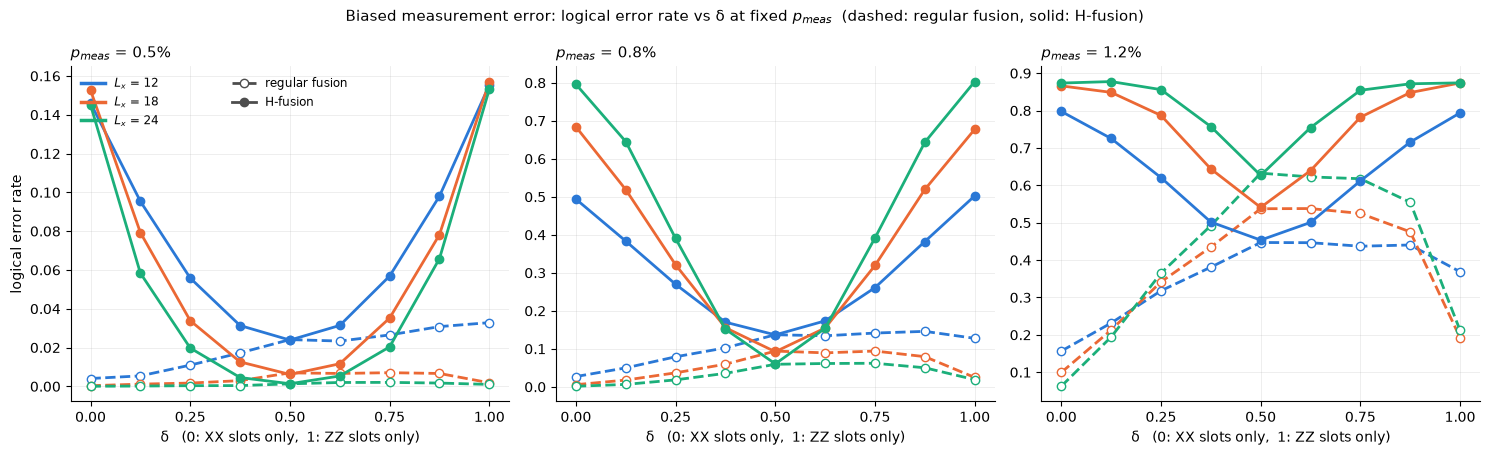

In [ ]:
BIAS_SIZE_COLOURS = {12: "#2a78d6", 18: "#eb6834", 24: "#1baf7a"}    # §9's per-size colours
BIAS_CODE_STYLE = {"regular fusion": dict(ls="--", mfc="white", marker="o"),
                   "H-fusion":       dict(ls="-", marker="o")}       # §9's code styles


def plot_bias(noise, xlab, title):
    deltas = BIAS_DELTAS[noise]
    fig, axes = plt.subplots(1, len(BIAS_P[noise]), figsize=(15, 4.6))
    for ax, p in zip(axes, BIAS_P[noise]):
        for code in BIAS_CODES:
            for L in BIAS_LS:
                ax.plot(deltas, bias_results[(noise, code, L, p)], color=BIAS_SIZE_COLOURS[L],
                        lw=2, ms=6, **BIAS_CODE_STYLE[code])
        ax.set_title(f"{xlab} = {p * 100:.1f}%", fontsize=11, loc="left")
        ax.set_xlabel("δ   (0: XX slots only,  1: ZZ slots only)")
        ax.set_xticks(np.linspace(0, 1, 5))
        ax.grid(alpha=.25, lw=.6)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes[0].set_ylabel("logical error rate")
    leg = axes[0].legend(handles=[plt.Line2D([], [], color=BIAS_SIZE_COLOURS[L], lw=2.5, label=f"$L_x$ = {L}")
                                  for L in BIAS_LS], fontsize=8.5, frameon=False, loc="upper left")
    axes[0].add_artist(leg)
    axes[0].legend(handles=[plt.Line2D([], [], color="0.3", lw=2, label=c, **BIAS_CODE_STYLE[c])
                            for c in BIAS_CODES], fontsize=8.5, frameon=False, loc="upper center")
    fig.suptitle(title + "  (dashed: regular fusion, solid: H-fusion)", fontsize=11)
    fig.tight_layout()
    plt.show()


plot_bias("meas", "$p_{meas}$", "Biased measurement error: logical error rate vs δ at fixed $p_{meas}$")

### Result

**At `δ = 0.5` (§6's unbiased model) the two codes agree**, as §9 requires.
At Lx = 24 they give 0.13% vs 0.14% at `p = 0.5%`, 5.93% vs 6.04% at `0.8%`,
and 63.3% vs 62.7% at `1.2%`. Below §6's threshold of about 1.0% they improve
with size, and above it they get worse.

**H-fusion behaves exactly as predicted**, and is worst at the ends. At
`p = 0.5%`, `δ = 0` and `δ = 1` sit at about 15% for all three sizes (14.6 /
15.3 / 14.5% and 15.5 / 15.7 / 15.3%), i.e. at threshold: one sector's records
flip at `2p = 1.0%`, which is §6's threshold. At 0.8% only `0.375 <= δ <= 0.625`
still improves with size. This is the same decoding problem as
`HexagonMOD2_fbqc_walkthrough.ipynb` §10's H-fusion circuit, and the numbers
agree with it to within shot noise.

**Regular fusion is not symmetric in `δ`:**

* **`δ < 0.5` is its strong side.** `δ = 0` improves with size at every `p`,
  including 1.2% (15.7 -> 9.9 -> 6.2%), as §10's dephasing result predicted:
  `XX`-only flips survive up to an `XX` rate of about 3%, i.e. `p ≈ 1.5%` here.
* **`δ > 0.5` is flatter and weaker.** At 1.2% everything from `δ = 0.25` to
  `0.875` gets worse with size. At `δ = 1` the curves stop improving between
  Lx = 18 and 24 (0.19 -> 0.10%, 2.47 -> 1.88% and 19.3 -> 21.2% at the three
  `p`), even though 12 -> 18 still improves a lot. So the 18 x 24 crossing at
  `δ = 1` sits well below the 12 x 18 one: a drifting crossing. Larger sizes
  are needed to pin it down.

### Distance under single-slot noise

That `δ = 1` stall is **not** a short logical. Stim's `shortest_graphlike_error`,
on the circuit with only one slot noisy, gives:

| code | `XX` slots only (`δ = 0`) | `ZZ` slots only (`δ = 1`) |
|---|---|---|
| regular fusion | 8 / 12 / 16 | 6 / 9 / 12 |
| H-fusion | 6 / 9 / 12 | 6 / 9 / 12 |

(Lx = 12 / 18 / 24.) Every distance grows linearly with size. The regular
code's `XX`-only distance, `2Lx/3`, is the largest of the four, which fits
`δ = 0` being its strongest point. (Computed in a separate check, not in this
notebook.)

§13 turns these fixed-`p` cuts into a threshold for each `δ`.

---
## 12. Biased erasure

The same split for §7's heralded erasure: the `XX` slot is erased with
probability `2 (1 - δ) p` and the `ZZ` slot with `2 δ p`, so `δ = 0.5` is §7's
`p_erase`. An erased record is replaced by a random bit and the decoder is told
which.

The decoder is §7's (and §9's) unchanged: each erased record's edge is set to
weight 0 for that shot, using the same erasure graphs (`get_outcome_matching`,
`hmod_outcome_matching`, at `p_meas ≈ 0`). Edges that are not erased never
carry an error in this model, so their weights do not need to know about the
bias.

**What to expect,** following §11:

* **H-fusion:** `δ = 0` erases only X-sector records, at `2p`, so the
  threshold should fall to half of §7's `p_erase ≈ 11.75%`, i.e. about 5.9%. At
  `δ = 0.5` it is §7's 11.75%.
* **Regular fusion:** every check sees both slots, so the bias is shared
  between the sectors.

Fixed `p_erase = 6%, 9%, 12%`; `δ = 0, 1/4, 1/2, 3/4, 1`; §9's shot counts
(2,000 at Lx=12/18, 1,000 at Lx=24). Erasure decoding is per-shot, so this is
the slow sweep.

In [ ]:
def bias_erasure_sweep(x_max, code, p, deltas, n_workers=4):
    """Logical failure rate vs delta at fixed p_erase: XX slots erased at
    2 (1 - delta) p, ZZ slots at 2 delta p, decoded with §7's erasure reweighting."""
    S = (hmod_outcome_matching if BIAS_CODES[code] else get_outcome_matching)(x_max, p_meas_eps_h)
    L = 3 * x_max
    raw = bias_structure(x_max, code)['raw'][:shots_by_L_h[L]]
    is_xx = bias_structure(x_max, code)['is_xx']
    rates = []
    for j, delta in enumerate(deltas):
        rng = np.random.default_rng((SEED_BIAS, x_max, int(round(p * 1e6)), j))
        q = np.where(is_xx, *slot_split(p, delta)).astype(np.float32)
        erased = rng.random(raw.shape, dtype=np.float32) < q
        outcomes = np.where(erased, rng.integers(0, 2, size=raw.shape, dtype=np.uint8), raw)
        dets = rows_to_parities_packed(outcomes, S['checks'])
        obs = rows_to_parities_packed(outcomes, S['logs'])
        pred = decode_with_erasure_parallel(dets, S['matcher'], S['outcome_edge'], S['weight'],
                                            len(S['logs']), erased, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / raw.shape[0])
    return np.array(rates)


t_all = time.time()
for p in BIAS_P["erasure"]:
    for code in BIAS_CODES:
        for L in BIAS_LS:
            t0 = time.time()
            bias_results[("erasure", code, L, p)] = bias_erasure_sweep(L // 3, code, p, BIAS_DELTAS["erasure"])
            print(f"  erasure p={p:.2f} {code:>14} Lx={L}: ({time.time() - t0:.0f}s)", flush=True)
print(f"\ntotal: {time.time() - t_all:.0f}s")

print_bias_table("erasure")

  [erasure graph Lx=12, p_meas=1e-09: 2304 edges (one per outcome)]


  erasure p=0.06 regular fusion Lx=12: (21s)


  erasure p=0.06 regular fusion Lx=18: (26s)


  [erasure graph Lx=24, p_meas=1e-09: 18432 edges (one per outcome)]


  erasure p=0.06 regular fusion Lx=24: (125s)


...

  erasure p=0.12 regular fusion Lx=24: (58s)


  erasure p=0.12       H-fusion Lx=12: (12s)


  erasure p=0.12       H-fusion Lx=18: (134s)


  erasure p=0.12       H-fusion Lx=24: (724s)



total: 1768s

erasure, p = 6.0%: logical failure rate (any of 6 observables)
   δ       regular  12  regular  18  regular  24  H-fusion 12  H-fusion 18  H-fusion 24
   0.000        0.0000       0.0000       0.0000       0.3345       0.3535       0.3430
   0.250        0.0000       0.0000       0.0000       0.0340       0.0070       0.0010
   0.500        0.0015       0.0000       0.0000       0.0000       0.0005       0.0000
   0.750        0.0035       0.0000       0.0000       0.0275       0.0080       0.0010
   1.000        0.0100       0.0010       0.0000       0.3120       0.3295       0.3690

erasure, p = 9.0%: logical failure rate (any of 6 observables)
   δ       regular  12  regular  18  regular  24  H-fusion 12  H-fusion 18  H-fusion 24
   0.000        0.0275       0.0025       0.0000       0.8800       0.8835       0.8900
   0.250        0.0335       0.0055       0.0020       0.5820       0.7575       0.8330
   0.500        0.0545       0.0105       0.0010       0.0545     

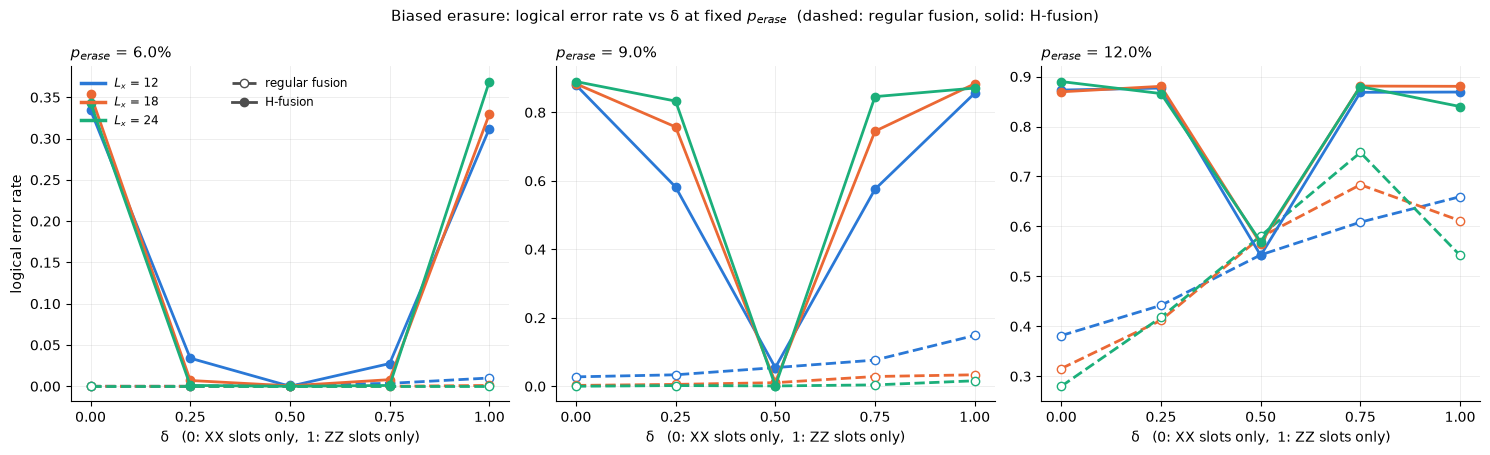

In [ ]:
plot_bias("erasure", "$p_{erase}$", "Biased erasure: logical error rate vs δ at fixed $p_{erase}$")

### Result

* **`δ = 0.5` (§7's model): the codes agree** (at 12%: 54.3 / 57.9 / 58.1%
  regular vs 54.2 / 56.6 / 56.9% H-fusion). Both rise slowly with size, so 12%
  is just above threshold, consistent with §7's 11.75%.
* **H-fusion, `δ = 0` and `δ = 1`:** at 6% they are 33.5 / 35.4 / 34.3% and
  31.2 / 33.0 / 36.9%. They are nearly flat with size, so they sit at
  threshold: one sector is erased at `2p = 12%`, matching §7's 11.75%. At 9%
  only `δ = 0.5` still improves with size.
* **Regular fusion:** improves with size at every `δ` at 6% and 9%. At 12% the
  two ends still improve (`δ = 0`: 38.2 -> 31.6 -> 28.0%; `δ = 1`:
  66.0 -> 61.2 -> 54.2%), while `δ = 0.5` and `0.75` get worse. As in §11,
  `δ = 0` is the regular code's best point.

Shot counts are §9's (2,000 / 2,000 / 1,000), so an entry of 0 means fewer than
about one failure in a thousand, and the small rates at 6% and 9% are only good
to a factor of a few.

---
## 13. Measurement threshold vs `δ`

§11 cut the problem at fixed `p_meas`. Here the cut is the other way: for each
`δ` the whole `p_meas` sweep is redone and its threshold found, giving
`p_th(δ)`. The noise model, decoder, sizes and shots are §11's, so `p_th(0.5)`
is §6's threshold.

**Only the regular-fusion code is swept.** The H-fusion code's two sectors
decouple (§8), and each fails once its own flip rate reaches §6's
`p_c = 0.996%`. The sector with the larger share, at rate `2 max(δ, 1 - δ) p`,
fails first, so

`p_th(δ) = p_c / (2 max(δ, 1 - δ))`,

which `HexagonMOD2_fbqc_walkthrough.ipynb` §12 confirms on the identical
decoding problem: its H-fusion crossings follow the formula to within a few
percent at every `δ`. The plot below draws the formula as a reference.

### Predictions for the regular code

* **`δ = 0`:** exactly §10's pure-dephasing decoding problem (`XX` flips only),
  whose threshold was an `XX` flip rate of 2.98%. That rate is `2p` here, so
  `p ≈ 1.49%`.
* **`δ = 0.5`:** §6's `p_c ≈ 1.0%` (the unbiased model).

### Method

The threshold moves by a large factor across `δ`, so a single `p` grid either
misses it or wastes points. Each `δ` therefore gets two passes:

1. **Coarse:** log-spaced `p` at Lx = 12 and 18 only (cheap). Its 12 x 18
   crossing is the centre for pass 2.
2. **Fine:** points spread evenly around that centre, at Lx = 12, 18, 24. The
   reported crossings are 12 x 18 and 18 x 24, using §6's `find_crossing`.

For `p_meas`: 15 coarse points from 0.3% to 4%, 11 fine points from 0.75x to
1.25x, 20,000 shots, `δ` in steps of 1/8. One noiseless sample per size is
reused across `p`, so the points on one curve are correlated. These are naive
crossings with no finite-size-scaling fit, like §10's. The crossings are saved
to `bias_threshold/` for `HexagonMOD2_fbqc_walkthrough.ipynb` §14's comparison.

In [ ]:
TH_CODE = "regular fusion"
TH_DELTAS = {"meas": np.round(np.linspace(0, 1, 9), 4), "erasure": np.round(np.linspace(0, 1, 5), 4)}
TH_COARSE_PS = {"meas": np.round(np.geomspace(0.003, 0.04, 15), 6),
                "erasure": np.round(np.geomspace(0.04, 0.3, 10), 6)}
TH_FINE_SPAN = {"meas": (0.75, 1.25, 11), "erasure": (0.8, 1.2, 7)}
P_C_TH = {"meas": 0.00996, "erasure": 0.1175}     # §6 and §7 thresholds (regular fusion)
P_TH_DEPHASE = 0.02980                            # §10: XX-only flip-rate threshold (= 2p at δ = 0)
BIAS_TH_DIR = "bias_threshold"
os.makedirs(BIAS_TH_DIR, exist_ok=True)


def bias_meas_p_sweep(x_max, code, delta, ps, n_workers=4):
    """Logical failure rate vs p_meas at fixed delta -- §11's sweep transposed."""
    S = bias_structure(x_max, code)
    rates = []
    for p in ps:
        q_xx, q_zz = slot_split(p, delta)
        rng = np.random.default_rng((SEED_BIAS, x_max, int(round(p * 1e6)), int(round(delta * 1e4)), 7))
        q = np.where(S['is_xx'], q_xx, q_zz).astype(np.float32)
        outcomes = S['raw'].copy()
        for s0 in range(0, outcomes.shape[0], 2000):
            blk = outcomes[s0:s0 + 2000]
            blk ^= (rng.random(blk.shape, dtype=np.float32) < q).astype(np.uint8)
        reweight_matching(S, q_xx, q_zz, 0.0)
        rates.append(_decode_rate(S, outcomes, n_workers))
    return np.array(rates)


def two_pass_threshold(sweep, noise, delta):
    """Coarse 12 x 18 crossing, then a fine grid around it at all three sizes."""
    coarse = [sweep(x, delta, TH_COARSE_PS[noise]) for x in (4, 6)]
    centre = find_crossing(TH_COARSE_PS[noise], coarse[0], coarse[1])
    if centre is None:
        return dict(centre=None, ps=TH_COARSE_PS[noise], curves=coarse, crossings=(None, None))
    ps = np.round(centre * np.linspace(*TH_FINE_SPAN[noise]), 6)
    curves = [sweep(L // 3, delta, ps) for L in BIAS_LS]
    return dict(centre=centre, ps=ps, curves=curves,
                crossings=tuple(find_crossing(ps, curves[i], curves[i + 1]) for i in (0, 1)))


def save_th_csv(path, results, circuit):
    with open(path, "w") as f:
        f.write("circuit,delta,cross_12x18,cross_18x24\n")
        for delta, r in results.items():
            f.write(f"{circuit},{delta}," + ",".join("" if x is None else f"{x:.6g}" for x in r['crossings']) + "\n")


def run_threshold_vs_delta(noise, sweep):
    results, t_all = {}, time.time()
    for delta in TH_DELTAS[noise]:
        t0 = time.time()
        results[delta] = r = two_pass_threshold(sweep, noise, delta)
        cells_ = "  ".join(f"{(f'{x * 100:.3f}%' if x is not None else '--'):>8}" for x in r['crossings'])
        centre = f"{r['centre'] * 100:.2f}%" if r['centre'] else "none"
        print(f"  {noise} δ={delta:.3f}: coarse centre {centre}   12x18, 18x24: {cells_}   "
              f"({time.time() - t0:.0f}s)", flush=True)
    print(f"\ntotal: {time.time() - t_all:.0f}s")
    path = os.path.join(BIAS_TH_DIR, f"hexagon_{noise}_threshold_vs_delta.csv")
    save_th_csv(path, results, TH_CODE)
    print(f"saved {path}")
    return results


th_vs_delta = {"meas": run_threshold_vs_delta(
    "meas", lambda x, d, ps: bias_meas_p_sweep(x, TH_CODE, d, ps))}

  meas δ=0.000: coarse centre 1.47%   12x18, 18x24:   1.497%    1.459%   (198s)


  meas δ=0.125: coarse centre 1.24%   12x18, 18x24:   1.261%    1.246%   (164s)


  meas δ=0.250: coarse centre 1.14%   12x18, 18x24:   1.141%    1.116%   (177s)


  meas δ=0.375: coarse centre 1.07%   12x18, 18x24:   1.081%    1.061%   (175s)


  meas δ=0.500: coarse centre 0.98%   12x18, 18x24:   1.003%    1.010%   (224s)


  meas δ=0.625: coarse centre 0.99%   12x18, 18x24:   0.997%    1.013%   (194s)


  meas δ=0.750: coarse centre 1.00%   12x18, 18x24:   1.014%    1.000%   (185s)


  meas δ=0.875: coarse centre 1.09%   12x18, 18x24:   1.102%    1.045%   (186s)


  meas δ=1.000: coarse centre 1.77%   12x18, 18x24:   1.748%        --   (214s)



total: 1717s
saved bias_threshold/hexagon_meas_threshold_vs_delta.csv


     δ |    12x18    18x24 | H-fusion predicted
 0.000 |   1.497%   1.459% | 0.498%
 0.125 |   1.261%   1.246% | 0.569%
 0.250 |   1.141%   1.116% | 0.664%
 0.375 |   1.081%   1.061% | 0.797%
 0.500 |   1.003%   1.010% | 0.996%
 0.625 |   0.997%   1.013% | 0.797%
 0.750 |   1.014%   1.000% | 0.664%
 0.875 |   1.102%   1.045% | 0.569%
 1.000 |   1.748%       -- | 0.498%


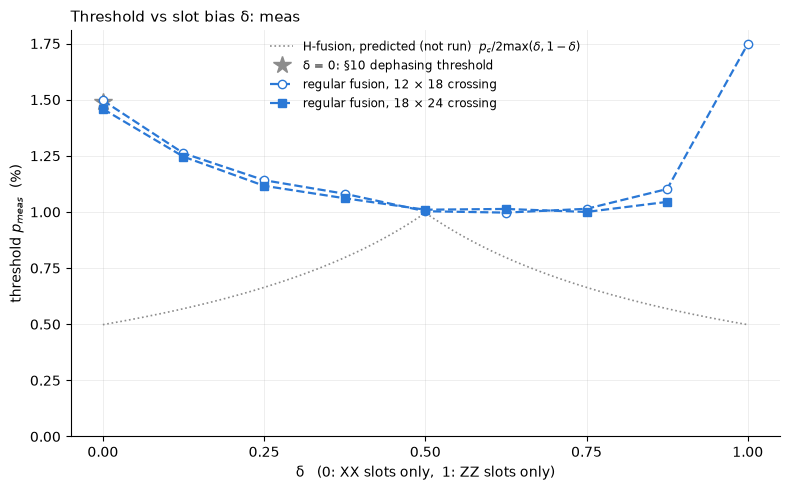

In [ ]:
def th_prediction_hfusion(noise, delta):
    return P_C_TH[noise] / (2 * np.maximum(delta, 1 - delta))


def plot_th_vs_delta(noise, xlab, extra=(), legend_loc="upper center"):
    res = th_vs_delta[noise]
    fmt = lambda x: f"{x * 100:.3f}%" if x is not None else "--"
    print(f"{'δ':>6} | {'12x18':>8} {'18x24':>8} | H-fusion predicted")
    for d, r in res.items():
        print(f"{d:>6.3f} | {fmt(r['crossings'][0]):>8} {fmt(r['crossings'][1]):>8} | "
              f"{th_prediction_hfusion(noise, d) * 100:.3f}%")

    fig, ax = plt.subplots(figsize=(8, 5))
    dd = np.linspace(0, 1, 201)
    ax.plot(dd, th_prediction_hfusion(noise, dd) * 100, color="0.55", lw=1.2, ls=":",
            label="H-fusion, predicted (not run)  $p_c / 2\\max(δ, 1-δ)$")
    for (d, y, lab) in extra:
        ax.plot([d], [y * 100], marker="*", ms=13, color="0.55", ls="none", label=lab)
    for k, (mk, pair) in enumerate((("o", "12 × 18"), ("s", "18 × 24"))):
        pts = [(d, r['crossings'][k]) for d, r in res.items() if r['crossings'][k] is not None]
        ax.plot([d for d, _ in pts], [x * 100 for _, x in pts], marker=mk, ms=6, lw=1.6, ls="--",
                color="#2a78d6", mfc="white" if k == 0 else "#2a78d6", label=f"regular fusion, {pair} crossing")
    ax.set_xlabel("δ   (0: XX slots only,  1: ZZ slots only)")
    ax.set_ylabel(f"threshold {xlab}  (%)")
    ax.set_xticks(np.linspace(0, 1, 5))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.25, lw=.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(fontsize=8.5, frameon=False, loc=legend_loc)
    ax.set_title(f"Threshold vs slot bias δ: {noise}", fontsize=11, loc="left")
    fig.tight_layout()
    plt.show()


plot_th_vs_delta("meas", "$p_{meas}$", extra=[(0.0, P_TH_DEPHASE / 2, "δ = 0: §10 dephasing threshold")])

### Result

| `δ` | 12 x 18 | 18 x 24 | H-fusion, predicted |
|---|---|---|---|
| 0     | 1.50% | 1.46% | 0.50% |
| 0.125 | 1.26% | 1.25% | 0.57% |
| 0.25  | 1.14% | 1.12% | 0.66% |
| 0.375 | 1.08% | 1.06% | 0.80% |
| 0.5   | 1.00% | 1.01% | 1.00% |
| 0.625 | 1.00% | 1.01% | 0.80% |
| 0.75  | 1.01% | 1.00% | 0.66% |
| 0.875 | 1.10% | 1.05% | 0.57% |
| 1     | 1.75% | none in the fine grid | 0.50% |

* **Both predictions hold.** `δ = 0.5` gives 1.00% / 1.01%, which is §6's
  0.996%. `δ = 0` gives 1.50% / 1.46%, against 1.49% from §10's dephasing
  threshold.
* **From `δ = 0` to `0.75` the two crossings agree to within 0.03 points.**
  The threshold falls steadily from 1.5% at `δ = 0` to a floor at §6's 1.0%,
  reached at `δ = 0.5` and holding to `0.75`. So biasing the noise towards the
  `XX` slots never hurts the regular code, and pure `XX` noise is tolerated at
  1.5x the unbiased rate.
* **The `ZZ`-heavy end is not converged.** At `δ = 0.875` the crossings split
  (1.10% vs 1.05%). At `δ = 1` the 12 x 18 crossing is 1.75%, but the Lx = 18
  and 24 curves do not cross anywhere in the fine grid (1.33-2.21%), so the
  18 x 24 crossing lies below 1.33%. This is the stall §11 found, and `δ = 1`'s
  threshold cannot be quoted from these sizes. §11's distance table rules out a
  short logical as the cause.
* **The regular code is at least as good as the H-fusion prediction at every
  `δ`,** and the two meet only at `δ = 0.5`.

---
## 14. Erasure threshold vs `δ`

§13's procedure for §12's biased erasure: the `XX` slot is erased with
probability `2 (1 - δ) p` and the `ZZ` slot with `2 δ p` (so `δ = 0.5` is
§7's `p_erase`), decoded with §7's per-shot erasure reweighting. Again only the regular-fusion code is swept. For
H-fusion the same sector argument gives `p_th(δ) = p_c / (2 max(δ, 1 - δ))` with
§7's `p_c = 11.75%`, drawn as a reference.

**Prediction:** §7's 11.75% at `δ = 0.5`. §10 has no erasure
analogue, so the ends are new.

Erasure decoding is per-shot and slow at Lx = 24, so the grid is coarser than
§13's: 10 coarse points from 4% to 30%, 7 fine points from 0.8x to 1.2x the
centre, `δ = 0, 1/4, 1/2, 3/4, 1`, and §9's shot counts (2,000 / 2,000 /
1,000). At those counts the crossings are good to roughly ±0.25 points.

In [ ]:
def bias_erasure_p_sweep(x_max, code, delta, ps, n_workers=4):
    """Logical failure rate vs p_erase at fixed delta -- §12's sweep transposed."""
    S = (hmod_outcome_matching if BIAS_CODES[code] else get_outcome_matching)(x_max, p_meas_eps_h)
    B = bias_structure(x_max, code)
    raw = B['raw'][:shots_by_L_h[3 * x_max]]
    rates = []
    for p in ps:
        rng = np.random.default_rng((SEED_BIAS, x_max, int(round(p * 1e6)), int(round(delta * 1e4)), 11))
        q = np.where(B['is_xx'], *slot_split(p, delta)).astype(np.float32)
        erased = rng.random(raw.shape, dtype=np.float32) < q
        outcomes = np.where(erased, rng.integers(0, 2, size=raw.shape, dtype=np.uint8), raw)
        dets = rows_to_parities_packed(outcomes, S['checks'])
        obs = rows_to_parities_packed(outcomes, S['logs'])
        pred = decode_with_erasure_parallel(dets, S['matcher'], S['outcome_edge'], S['weight'],
                                            len(S['logs']), erased, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / raw.shape[0])
    return np.array(rates)


th_vs_delta["erasure"] = run_threshold_vs_delta(
    "erasure", lambda x, d, ps: bias_erasure_p_sweep(x, TH_CODE, d, ps))

  erasure δ=0.000: coarse centre 14.09%   12x18, 18x24:  12.291%   12.623%   (836s)


  erasure δ=0.250: coarse centre 11.54%   12x18, 18x24:  12.061%   12.024%   (440s)


  erasure δ=0.500: coarse centre 11.15%   12x18, 18x24:  11.959%   12.007%   (493s)


  erasure δ=0.750: coarse centre 11.17%   12x18, 18x24:  11.433%   11.594%   (515s)


  erasure δ=1.000: coarse centre 14.26%   12x18, 18x24:  12.619%   12.613%   (415s)



total: 2699s
saved bias_threshold/hexagon_erasure_threshold_vs_delta.csv


     δ |    12x18    18x24 | H-fusion predicted
 0.000 |  12.291%  12.623% | 5.875%
 0.250 |  12.061%  12.024% | 7.833%
 0.500 |  11.959%  12.007% | 11.750%
 0.750 |  11.433%  11.594% | 7.833%
 1.000 |  12.619%  12.613% | 5.875%


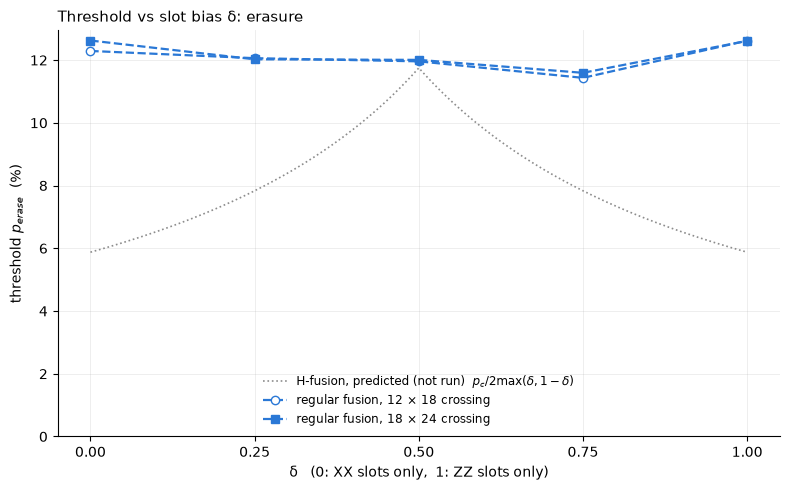

In [ ]:
plot_th_vs_delta("erasure", "$p_{erase}$", legend_loc="lower center")

### Result

| `δ` | 12 x 18 | 18 x 24 | H-fusion, predicted |
|---|---|---|---|
| 0    | 12.3% | 12.6% | 5.9% |
| 0.25 | 12.1% | 12.0% | 7.8% |
| 0.5  | 12.0% | 12.0% | 11.75% |
| 0.75 | 11.4% | 11.6% | 7.8% |
| 1    | 12.6% | 12.6% | 5.9% |

* **`δ = 0.5` matches §7:** 12.0% / 12.0% against 11.75%, within this run's
  resolution.
* **The erasure threshold barely depends on `δ`.** It stays within
  11.4-12.6% across the whole range, i.e. within about ±0.6 points of §7's
  unbiased value. Measurement error is different (§13): there pure-`XX` noise is
  tolerated at 1.5x the unbiased rate. For erasure, moving the erasures onto one
  slot type neither helps nor hurts the regular code much.
* **H-fusion would be far worse away from `δ = 0.5`.** It would drop to 5.9% at
  the ends, half the regular code's value.

At 1,000-2,000 shots the crossings are good to roughly ±0.25 points, so the dip
at `δ = 0.75` is at the edge of what this run resolves.

---
## 15. (archived) How the §6 measurement threshold degrades with prep noise

Everything below is the two-knob version of §10: the prep-noise layer is kept
at a *fixed* rate `r`, `p_meas` is swept on top of it, and what is reported
is §6's measurement threshold `p_meas^th(r)` -- one number per `r`, rather
than a single threshold in `r`. It reuses §10's `prep_noise_sweep`,
structures and sanity checks unchanged, and is kept for reference rather
than as this section's headline result. Variables carry a `_pm` suffix so
nothing here overwrites §10.

**These cells are shipped unexecuted.** Running them re-does 15 full `p_meas`
sweeps at three sizes and takes roughly 40 minutes on a machine with the
memory free for it (each Lx=24 sample is ~370MB and the decoder forks four
workers, so it slows down badly once the box starts swapping).


### Where to look for each crossing

The threshold moves a long way as `r` grows -- by `r ≈ 0.7%` of depolarising
noise the code can barely tolerate any measurement error at all -- so a
single fixed `p_meas` grid would waste almost every point. Each `r` instead
gets an 11-point window centred on a prediction:

* **Depolarising** hits XX and ZZ outcomes with the same marginal `a`, so it
  is (to the decoder) indistinguishable from more readout noise: the
  crossing should sit where `a ⊕ p_meas = p_c`, with `p_c = 0.996%` from §6.
* **Dephasing** only hits XX outcomes, leaving half of every matching-graph
  sector clean, so it costs much less per unit `a`. A scan at Lx=12/18 puts
  the slope near `0.4`, and that is what the window uses.

Neither prediction is trusted -- it only places the window, and the window
widens and re-runs if the three pairwise crossings are not all bracketed.
The threshold reported for each `r` is the mean of the `12x18`, `18x24` and
`12x24` crossings, with their spread as the uncertainty. This is the naive
crossing estimate of §6, not the finite-size-scaling fit: three sizes are
enough to locate a crossing but not to fit `nu` at 16 values of `r`.

Runtime is dominated by the Lx=24 decodes -- roughly 40 minutes in total for
the 15 `(case, r)` pairs below at 20000 shots.


In [ ]:
r_grid_pm = {"depolarise": [round(0.001 * k, 4) for k in range(8)],    # 0 .. 0.7%
             "dephase":    [round(0.002 * k, 4) for k in range(7)]}   # 0 .. 1.2%


def predicted_p_threshold(r, channel):
    """Centre of the p_meas window -- a placement heuristic, nothing more."""
    a = prep_flip_probs(r, channel)[0]
    if channel == "depolarise":
        return max(0.0, (P_C_MEAS - a) / (1 - 2 * a))    # a XOR p = p_c
    return max(0.0, P_C_MEAS - 0.40 * a)                 # empirical slope


def threshold_at_r(r, channel, shots=20000, n_pts=11, seed=4321, n_workers=4):
    """Sweep p_meas over a window around the prediction, widening until all
    three pairwise crossings are bracketed."""
    p0 = predicted_p_threshold(r, channel)
    half = max(8e-4, 0.18 * p0)
    for _ in range(3):
        ps = np.linspace(max(2e-4, p0 - half), p0 + half, n_pts)
        curves = [prep_noise_sweep(L // 3, r, channel, ps, shots=shots,
                                    seed=seed, n_workers=n_workers) for L in Ls_prep]
        crossings = [find_crossing(ps, curves[i], curves[j]) for i, j in PREP_PAIRS]
        if all(x is not None for x in crossings):
            break
        half *= 2.5
    return ps, curves, crossings


pm_curves, pm_thresholds = {}, {}
t_prep0 = time.time()
for channel in ("depolarise", "dephase"):
    for r in r_grid_pm[channel]:
        t0 = time.time()
        ps_r, curves_r, crossings_r = threshold_at_r(r, channel)
        pm_curves[(channel, r)] = (ps_r, curves_r)
        found = [x for x in crossings_r if x is not None]
        p_th = float(np.mean(found)) if found else np.nan
        spread = float(np.std(found, ddof=1)) if len(found) > 1 else np.nan
        pm_thresholds[(channel, r)] = (p_th, spread)
        detail = ", ".join(f"{x:.5f}" if x is not None else "none" for x in crossings_r)
        pair_names = ", ".join(f"{Ls_prep[i]}x{Ls_prep[j]}" for i, j in PREP_PAIRS)
        print(f"{channel:<11} r={r:<7.4f} p_th = {p_th:.5f} +/- {spread:.5f}   "
              f"[{pair_names}: {detail}]  ({time.time() - t0:.0f}s)", flush=True)

print(f"\ntotal sweep time: {time.time() - t_prep0:.0f}s")


In [ ]:
csv_path_pm = os.path.join(out_dir_prep, "vs_p_meas_results.csv")
with open(csv_path_pm, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["channel", "r", "p_meas", "L", "P_fail", "n_shots"])
    for (channel, r), (ps_r, curves_r) in pm_curves.items():
        for L, curve in zip(Ls_prep, curves_r):
            for p, v in zip(ps_r, curve):
                writer.writerow([channel, r, p, L, v, n_shots_prep])

csv_path_pm_th = os.path.join(out_dir_prep, "vs_p_meas_thresholds.csv")
with open(csv_path_pm_th, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["channel", "r", "p_threshold", "spread"])
    for (channel, r), (p_th, spread) in pm_thresholds.items():
        writer.writerow([channel, r, p_th, spread])
print(f"wrote {csv_path_pm} and {csv_path_pm_th}")


### Crossings

One panel per `r`: logical failure rate against `p_meas` for Lx = 12, 18, 24.
Below the crossing the larger code wins and the curves fan downward with
size; above it the ordering inverts. The dashed line in each panel is the
reported threshold (the mean of the three pairwise crossings).


In [ ]:
for channel in ("depolarise", "dephase"):
    rs = r_grid_pm[channel]
    ncol = 4
    nrow = int(np.ceil(len(rs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 2.9 * nrow),
                             squeeze=False, sharey=True)
    for ax, r in zip(axes.ravel(), rs):
        ps_r, curves_r = pm_curves[(channel, r)]
        for L, curve in zip(Ls_prep, curves_r):
            ax.plot(np.asarray(ps_r) * 100, curve, "o-", lw=2, ms=5,
                    color=PREP_COLOURS[L], label=f"Lx = {L}")
        p_th, _ = pm_thresholds[(channel, r)]
        if np.isfinite(p_th):
            ax.axvline(p_th * 100, ls="--", lw=1, color="0.45")
        ax.set_title(f"$r$ = {r * 100:g}%" +
                     (f"    $p_{{meas}}^{{th}}$ = {p_th * 100:.3f}%" if np.isfinite(p_th) else ""),
                     fontsize=9.5)
        ax.grid(alpha=.25, lw=.6)
        ax.tick_params(labelsize=8)
    for ax in axes.ravel()[len(rs):]:
        ax.set_visible(False)
    for col in range(ncol):                      # label the lowest live axis per column
        live = [axes[row][col] for row in range(nrow) if axes[row][col].get_visible()]
        if live:
            live[-1].set_xlabel("$p_{meas}$  (%)", fontsize=9)
    for row in axes:
        row[0].set_ylabel("logical failure rate", fontsize=9)
    axes[0][0].legend(fontsize=8, framealpha=.9)
    fig.suptitle(CASE_TITLES[channel] + "  --  crossings at each prep-noise rate $r$",
                 fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(os.path.join(out_dir_prep, f"vs_p_meas_crossings_{channel}.png"), dpi=150)
    plt.show()


### Threshold vs prep-noise rate


In [ ]:
CASE_STYLE = {"depolarise": ("#2a78d6", "o", "depolarising, $r/3$ each of X, Y, Z"),
              "dephase":    ("#eb6834", "s", "pure dephasing, Z with prob. $r$")}

plt.figure(figsize=(6.6, 4.4))
for channel in ("depolarise", "dephase"):
    colour, marker, label = CASE_STYLE[channel]
    rs = np.array(r_grid_pm[channel])
    y = np.array([pm_thresholds[(channel, r)][0] for r in r_grid_pm[channel]])
    e = np.array([pm_thresholds[(channel, r)][1] for r in r_grid_pm[channel]])
    plt.errorbar(rs * 100, y * 100, yerr=np.nan_to_num(e) * 100, fmt=marker + "-",
                 lw=2, ms=6, capsize=3, color=colour, label=label)
    plt.annotate(label.split(",")[0], (rs[-1] * 100, y[-1] * 100), ha="right",
                 textcoords="offset points", xytext=(-8, 8), fontsize=9, color=colour)

# The depolarising reference curve: prep noise and readout noise hit both
# outcome classes alike, so they should simply XOR into one effective rate.
rr = np.linspace(0, max(r_grid_pm["depolarise"]), 200)
a_ref = 2 * (2 * rr / 3) * (1 - 2 * rr / 3)
plt.plot(rr * 100, np.clip((P_C_MEAS - a_ref) / (1 - 2 * a_ref), 0, None) * 100,
         ":", lw=1.5, color="0.45", label=r"$a(r) \oplus p_{meas} = p_c$")
plt.axhline(P_C_MEAS * 100, ls="--", lw=1, color="0.75")

plt.xlabel("prep-noise rate $r$  (%)")
plt.ylabel("measurement-error threshold $p_{meas}^{th}$  (%)")
plt.title("Hexagon FBQC: fusion-measurement threshold vs. resource-state noise")
plt.ylim(bottom=0)
plt.margins(x=0.08)
plt.legend(fontsize=9, framealpha=.9, loc="lower left")
plt.grid(alpha=.25, lw=.6)
plt.tight_layout()
plt.savefig(os.path.join(out_dir_prep, "vs_p_meas_threshold_vs_r.png"), dpi=150)
plt.show()


In [ ]:
print("=" * 72)
print("MEASUREMENT THRESHOLD p_meas^th VS PREP-NOISE RATE r")
print("=" * 72)
for channel in ("depolarise", "dephase"):
    a_name = "2q(1-q), q = 2r/3" if channel == "depolarise" else "2r(1-r), XX only"
    print(f"\n{CASE_TITLES[channel]}")
    print(f"  prep-flip probability per outcome bit: a = {a_name}")
    print(f"\n  {'r':>8} {'a':>9} | {'p_meas threshold':>20} {'spread':>9}")
    for r in r_grid_pm[channel]:
        p_th, spread = pm_thresholds[(channel, r)]
        a = prep_flip_probs(r, channel)[0]
        print(f"  {r * 100:>7.2f}% {a * 100:>8.3f}% | {p_th * 100:>19.3f}% "
              f"{spread * 100:>8.3f}%")

    rs = np.array(r_grid_pm[channel], dtype=float)
    ys = np.array([pm_thresholds[(channel, r)][0] for r in r_grid_pm[channel]])
    ok = np.isfinite(ys)
    slope, intercept = np.polyfit(rs[ok][-3:], ys[ok][-3:], 1)
    print(f"\n  -> p_meas^th falls from {ys[ok][0] * 100:.3f}% at r = 0 to "
          f"{ys[ok][-1] * 100:.3f}% at r = {rs[ok][-1] * 100:.2f}%")
    print(f"  -> straight line through the last three points reaches zero at "
          f"r ~ {-intercept / slope * 100:.2f}%  (linear extrapolation, not a fit)")
